In [ ]:
# zseeker haplotypes path /scratch/10906/geomeg/pangenome_fastas/human_pangenome/zdna_csvs

In [30]:
import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")

## Data, metadata and preprocessing

In [ ]:
https://data.humanpangenome.org

In [1]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path
import re

# -----------------------------
# Paths
# -----------------------------
meta_file = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_release2_metadata.csv")
csv_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
out_tsv   = Path("/work/10906/geomeg/vista/pangenomes_zdna/processed_metadata.tsv")

# -----------------------------
# Load metadata
# -----------------------------
meta = pd.read_csv(meta_file)

if "sample_id" not in meta.columns:
    raise SystemExit("❌ 'sample_id' column not found in metadata file.")

# -----------------------------
# Collect CSV files
# -----------------------------
csv_files = sorted(csv_dir.glob("*.csv"))
if not csv_files:
    raise SystemExit("❌ No CSV files found in zdna_csvs directory.")

records = []

# -----------------------------
# Extract filename info
# -----------------------------
for f in csv_files:
    fname = f.name
    prefix = fname.split("_")[0]  # part before the first underscore

    # detect keywords
    lowername = fname.lower()
    if "pat" in lowername:
        pat_or_mat = "pat"
    elif "mat" in lowername:
        pat_or_mat = "mat"
    else:
        pat_or_mat = "0"

    if "hap1" in lowername:
        hap1_or_hap2 = "hap1"
    elif "hap2" in lowername:
        hap1_or_hap2 = "hap2"
    else:
        hap1_or_hap2 = "0"

    records.append({
        "filename": fname,
        "sample_id": prefix,
        "pat_or_mat": pat_or_mat,
        "hap1_or_hap2": hap1_or_hap2
    })

df = pd.DataFrame(records)

# -----------------------------
# Merge metadata
# -----------------------------
merged = df.merge(meta, on="sample_id", how="left", validate="many_to_one")

# -----------------------------
# Reorder columns
# -----------------------------
# Move filename, sample_id, pat_or_mat, hap1_or_hap2 to the front
cols_front = ["filename", "sample_id", "pat_or_mat", "hap1_or_hap2"]
remaining_cols = [c for c in merged.columns if c not in cols_front]
merged = merged[cols_front + remaining_cols]

# -----------------------------
# Save result
# -----------------------------
merged.to_csv(out_tsv, sep="\t", index=False)
print(f"✅ Wrote {len(merged)} rows to {out_tsv}")
print(f"   (Each CSV file matched by prefix before first underscore to sample_id)")


✅ Wrote 466 rows to /work/10906/geomeg/vista/pangenomes_zdna/processed_metadata.tsv
   (Each CSV file matched by prefix before first underscore to sample_id)


In [2]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import numpy as np

meta_file = Path("/work/10906/geomeg/vista/pangenomes_zdna/processed_metadata.tsv")
csv_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
out_tsv   = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")

meta = pd.read_csv(meta_file, sep="\t")

records = []
for f in tqdm(sorted(csv_dir.glob("*.csv")), desc="Processing Z-DNA CSVs"):
    fname = f.name
    try:
        df = pd.read_csv(f, sep=",", dtype={"Chromosome": str})
    except Exception as e:
        print(f"⚠️  Skipping {fname}: {e}")
        continue

    # Drop incomplete rows
    df = df.dropna(subset=["Chromosome", "Start", "End", "Z-DNA Score", "Sequence"])

    # Convert to numeric
    df["Start"] = pd.to_numeric(df["Start"], errors="coerce")
    df["End"]   = pd.to_numeric(df["End"], errors="coerce")
    df["Z-DNA Score"] = pd.to_numeric(df["Z-DNA Score"], errors="coerce")
    df = df.dropna(subset=["Start", "End", "Z-DNA Score"])

    if df.empty:
        n_preds = 0
        avg_len = np.nan
        avg_score = np.nan
    else:
        n_preds = len(df)
        avg_len = (df["End"] - df["Start"] + 1).mean()
        avg_score = df["Z-DNA Score"].mean()

    records.append({
        "filename": fname,
        "n_predictions": int(n_preds),
        "average_length": round(avg_len, 3) if pd.notna(avg_len) else np.nan,
        "average_score": round(avg_score, 3) if pd.notna(avg_score) else np.nan
    })

metrics = pd.DataFrame(records)
merged = meta.merge(metrics, on="filename", how="left", validate="one_to_one")
merged.to_csv(out_tsv, sep="\t", index=False)

print(f"✅ Wrote combined metadata + Z-DNA metrics to {out_tsv}")
print(f"   Total rows: {len(merged)}")


Processing Z-DNA CSVs: 100%|██████████████████| 466/466 [02:06<00:00,  3.69it/s]

✅ Wrote combined metadata + Z-DNA metrics to /work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv
   Total rows: 466


In [13]:
#!/usr/bin/env python3
import pandas as pd
import numpy as np
from pathlib import Path

tsv = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")
df = pd.read_csv(tsv, sep="\t", dtype=str)

# Normalize columns explicitly to string "0"/values
for c in ["pat_or_mat", "hap1_or_hap2"]:
    if c not in df.columns:
        raise SystemExit(f"❌ Missing column {c}")
    df[c] = df[c].astype(str).str.strip().replace({"nan": "0", "NaN": "0", "None": "0", "": "0"})

# Verify
print(df[["sample_id", "pat_or_mat", "hap1_or_hap2"]].head())

# ---------------------------------------------------------------------------
# 1️⃣  Group by sample_id and count mat/hap patterns
# ---------------------------------------------------------------------------
g = df.groupby("sample_id")[["pat_or_mat", "hap1_or_hap2"]].agg(lambda x: set(x))

count_both_zero = 0
count_mat0_hapN = 0
count_matN_hap0 = 0

for sid, row in g.iterrows():
    mats = row["pat_or_mat"]
    haps = row["hap1_or_hap2"]

    # Case 1: both are strictly "0"
    if mats == {"0"} and haps == {"0"}:
        count_both_zero += 1
    # Case 2: mat only 0
    elif mats == {"0"} and any(h != "0" for h in haps):
        count_mat0_hapN += 1
    # Case 3: hap only 0
    elif haps == {"0"} and any(m != "0" for m in mats):
        count_matN_hap0 += 1

print("\n1️⃣ mat/hap summary per sample_id:")
print(f"   • Both 0: {count_both_zero}")
print(f"   • mat=0, hap≠0: {count_mat0_hapN}")
print(f"   • mat≠0, hap=0: {count_matN_hap0}")


# ---------------------------------------------------------------------------
# 2️⃣  Unique population abbreviations
# ---------------------------------------------------------------------------
if "population_abbreviation" in df.columns:
    # Treat "", " ", and NaN as missing
    n_pop = df["population_abbreviation"].replace(["", " ", "nan", "NaN"], pd.NA).dropna().nunique()
    print(f"2️⃣ Unique population_abbreviation values (excluding blanks): {n_pop}")
else:
    print("2️⃣ Column 'population_abbreviation' not found.\n")


# ---------------------------------------------------------------------------
# 3️⃣  Sex counts per sample
# ---------------------------------------------------------------------------
if "sex" in df.columns:
    sex_by_id = df.groupby("sample_id")["sex"].first().str.lower()
    n_male = (sex_by_id == "male").sum()
    n_female = (sex_by_id == "female").sum()
    print(f"3️⃣ Sex distribution by sample_id:")
    print(f"   • Male: {n_male}")
    print(f"   • Female: {n_female}\n")
else:
    print("3️⃣ Column 'sex' not found.\n")

# ---------------------------------------------------------------------------
# 4️⃣  Lowest/highest in last 3 numeric columns (explicit fix)
# ---------------------------------------------------------------------------
# Try to coerce these specific columns to numeric
for c in ["n_predictions", "average_length", "average_score"]:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

numcols = [c for c in ["n_predictions", "average_length", "average_score"] if c in df.columns]

if len(numcols) >= 1:
    print("4️⃣ Extremes for numeric Z-DNA metrics:")
    for c in numcols:
        low = df[c].min(skipna=True)
        high = df[c].max(skipna=True)
        s_low = df.loc[df[c] == low, "sample_id"].unique()[:6]
        s_high = df.loc[df[c] == high, "sample_id"].unique()[:6]
        print(f"   • {c}: min={low}, max={high}")
        print(f"     lowest IDs: {', '.join(map(str, s_low))}")
        print(f"     highest IDs: {', '.join(map(str, s_high))}")
else:
    print("4️⃣ No numeric Z-DNA metric columns found.\n")


  sample_id pat_or_mat hap1_or_hap2
0     CHM13          0            0
1    GRCh38          0            0
2   HG00097          0         hap1
3   HG00097          0         hap2
4   HG00099          0         hap1

1️⃣ mat/hap summary per sample_id:
   • Both 0: 2
   • mat=0, hap≠0: 104
   • mat≠0, hap=0: 128
2️⃣ Unique population_abbreviation values (excluding blanks): 27
3️⃣ Sex distribution by sample_id:
   • Male: 116
   • Female: 116

4️⃣ Extremes for numeric Z-DNA metrics:
   • n_predictions: min=240301, max=276954
     lowest IDs: NA20762
     highest IDs: HG03470
   • average_length: min=55.347, max=56.48
     lowest IDs: HG02391
     highest IDs: NA20827
   • average_score: min=74.395, max=75.899
     lowest IDs: GRCh38
     highest IDs: HG02391


In [1]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path
from tqdm import tqdm

# ----------------------------------------------------
# Paths
# ----------------------------------------------------
csv_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs")
alias_dir = Path("/scratch/10906/geomeg/pangenomes_hprc/human_pangenome/chrom_aliases")
out_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")
out_dir.mkdir(exist_ok=True)

# ----------------------------------------------------
# Function to load alias map (robust)
# ----------------------------------------------------
def load_alias_map(alias_file: Path) -> dict:
    lines = [line.strip() for line in open(alias_file) if line.strip() and not line.startswith("#")]
    parts = [l.split() for l in lines]
    df = pd.DataFrame(parts, columns=["assembly", "ucsc", "genbank"])
    df = df.apply(lambda x: x.str.strip())
    return dict(zip(df["assembly"], df["ucsc"]))

# ----------------------------------------------------
# Iterate over Z-DNA CSVs
# ----------------------------------------------------
for csv_file in tqdm(sorted(csv_dir.glob("*.csv")), desc="Mapping chromosomes"):
    prefix = csv_file.name.split("_")[0]

    # Determine alias keyword based on CSV chromosome IDs
    alias_key = None
    try:
        with open(csv_file) as f:
            head_lines = [next(f) for _ in range(10)]
        if any("#1#" in line for line in head_lines):
            alias_key = "pat"  # paternal → "#1#"
        elif any("#2#" in line for line in head_lines):
            alias_key = "mat"  # maternal → "#2#"
    except StopIteration:
        pass  # empty or short file

    # fallback to filename keywords if above fails
    fname_lower = csv_file.name.lower()
    if alias_key is None:
        if "_pat" in fname_lower or "_hap1" in fname_lower:
            alias_key = "pat"
        elif "_mat" in fname_lower or "_hap2" in fname_lower:
            alias_key = "mat"

    # Find alias file
    # Try to find alias file by matching CSV stem first (1:1 name match)
    alias_stem = csv_file.name.replace(".zseeker.csv", "")
    alias_candidates = list(alias_dir.glob(f"{alias_stem}.chromAlias.txt"))
    
    # If still not found, broaden to pattern-based search
    if not alias_candidates:
        alias_candidates = list(alias_dir.glob(f"{prefix}*{alias_key}*.chromAlias.txt"))
    
    if not alias_candidates:
        print(f"⚠️  No alias file found for {csv_file.name}, skipping.")
        continue


    alias_file = alias_candidates[0]
    alias_map = load_alias_map(alias_file)
    print(f"🧩 Using alias: {alias_file.name}")

    # Load and map
    try:
        df = pd.read_csv(csv_file)
    except Exception as e:
        print(f"⚠️  Skipping {csv_file.name}: {e}")
        continue

    if "Chromosome" not in df.columns:
        print(f"⚠️  No 'Chromosome' column in {csv_file.name}, skipping.")
        continue

    df["Chromosome"] = df["Chromosome"].astype(str).str.strip()
    df["Chromosome_mapped"] = df["Chromosome"].map(alias_map)

    # warn for unmapped chromosomes
    unmapped = df["Chromosome_mapped"].isna().sum()
    if unmapped:
        print(f"⚠️  {unmapped} contigs not found in alias for {csv_file.name}")

    df["Chromosome_mapped"] = df["Chromosome_mapped"].fillna(df["Chromosome"])

    out_path = out_dir / csv_file.name
    df.to_csv(out_path, index=False)
    print(f"✅ Mapped {csv_file.name} → {out_path.name}")


Mapping chromosomes:   0%|                                                                      | 0/466 [00:00<?, ?it/s]

⚠️  No alias file found for CHM13_v2.0_maskedY_rCRS.fa.PanSN.zseeker.csv, skipping.
⚠️  No alias file found for GRCh38_GCA_000001405.15_no_alt_analysis_set.PanSN.zseeker.csv, skipping.
🧩 Using alias: HG00097_hap1_hprc_r2_v1.0.1.chromAlias.txt


Mapping chromosomes:   1%|▍                                                             | 3/466 [00:00<02:24,  3.20it/s]

✅ Mapped HG00097_hap1_hprc_r2_v1.0.1.zseeker.csv → HG00097_hap1_hprc_r2_v1.0.1.zseeker.csv
🧩 Using alias: HG00097_hap2_hprc_r2_v1.0.1.chromAlias.txt


Mapping chromosomes:   1%|▌                                                             | 4/466 [00:01<03:55,  1.96it/s]

✅ Mapped HG00097_hap2_hprc_r2_v1.0.1.zseeker.csv → HG00097_hap2_hprc_r2_v1.0.1.zseeker.csv
🧩 Using alias: HG00099_hap1_hprc_r2_v1.0.1.chromAlias.txt


... (916 outputs left out)

Mapping chromosomes: 100%|███████████████████████████████████████████████████████████▊| 465/466 [06:48<00:00,  1.09it/s]

✅ Mapped NA21309_mat_hprc_r2_v1.0.1.zseeker.csv → NA21309_mat_hprc_r2_v1.0.1.zseeker.csv
🧩 Using alias: NA21309_pat_hprc_r2_v1.0.1.chromAlias.txt


Mapping chromosomes: 100%|████████████████████████████████████████████████████████████| 466/466 [06:49<00:00,  1.14it/s]

✅ Mapped NA21309_pat_hprc_r2_v1.0.1.zseeker.csv → NA21309_pat_hprc_r2_v1.0.1.zseeker.csv


In [2]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path

# ----------------------------------------------------
# Path
# ----------------------------------------------------
mapped_dir = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")

# ----------------------------------------------------
# Process each CSV
# ----------------------------------------------------
for csv_file in sorted(mapped_dir.glob("*.csv")):
    try:
        df = pd.read_csv(csv_file)
    except Exception as e:
        print(f"⚠️  Skipping {csv_file.name}: {e}")
        continue

    if "Chromosome_mapped" not in df.columns:
        print(f"⚠️  No 'Chromosome_mapped' column in {csv_file.name}, skipping.")
        continue

    # Modify Chromosome_mapped
    df["Chromosome_mapped"] = df["Chromosome_mapped"].astype(str).apply(
        lambda x: x.split("_")[0] if "_" in x else x
    )

    # Overwrite same file
    df.to_csv(csv_file, index=False)
    print(f"✅ Cleaned {csv_file.name}")


✅ Cleaned HG00097_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00097_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00099_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00099_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00126_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00126_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00128_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00128_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00133_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00133_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00140_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00140_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00146_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00146_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00232_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00232_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00235_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00235_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00253_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Cleaned HG00253_hap2_hprc_r2_v1.0.1.zseeker.csv


In [4]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path

# ----------------------------------------------------
# Path
# ----------------------------------------------------
mapped_dir = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")

# ----------------------------------------------------
# Process each CSV
# ----------------------------------------------------
for csv_file in sorted(mapped_dir.glob("*.csv")):
    try:
        df = pd.read_csv(csv_file)
    except Exception as e:
        print(f"⚠️  Skipping {csv_file.name}: {e}")
        continue

    # Ensure required column exists
    if "Chromosome_mapped" not in df.columns or "Chromosome" not in df.columns:
        print(f"⚠️  Missing Chromosome/Chromosome_mapped in {csv_file.name}, skipping.")
        continue

    # Replace Chromosome with mapped values
    df["Chromosome"] = df["Chromosome_mapped"]

    # Sort rows by Chromosome (natural order: chr1–chr22, chrX, chrY, chrM)
    chrom_order = {f"chr{i}": i for i in range(1, 23)}
    chrom_order.update({"chrX": 23, "chrY": 24, "chrM": 25, "chrMT": 25, "chrUn": 26, "chrUN": 26})
    df["__sortkey__"] = df["Chromosome"].map(chrom_order).fillna(999)

    df = df.sort_values(by="__sortkey__").drop(columns="__sortkey__")

    # Overwrite same file
    df.to_csv(csv_file, index=False)
    print(f"✅ Updated and sorted {csv_file.name}")


✅ Updated and sorted HG00097_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00097_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00099_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00099_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00126_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00126_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00128_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00128_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00133_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00133_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00140_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00140_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00146_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00146_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00232_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG00232_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Updated and sorted HG0

In [5]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path

mapped_dir = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")

for csv_file in sorted(mapped_dir.glob("*.csv")):
    try:
        df = pd.read_csv(csv_file)
    except Exception as e:
        print(f"⚠️  Skipping {csv_file.name}: {e}")
        continue

    if "Chromosome_mapped" in df.columns:
        df = df.drop(columns=["Chromosome_mapped"])
        df.to_csv(csv_file, index=False)
        print(f"✅ Dropped Chromosome_mapped from {csv_file.name}")
    else:
        print(f"ℹ️  No Chromosome_mapped column in {csv_file.name}, skipped.")


✅ Dropped Chromosome_mapped from HG00097_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00097_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00099_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00099_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00126_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00126_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00128_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00128_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00133_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00133_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00140_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00140_hap2_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00146_hap1_hprc_r2_v1.0.1.zseeker.csv
✅ Dropped Chromosome_mapped from HG00146_hap2_hprc_

In [6]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path

# ----------------------------------------------------
# Target files
# ----------------------------------------------------
files = [
    "CHM13_v2.0_maskedY_rCRS.fa.PanSN.zseeker.csv",
    "GRCh38_GCA_000001405.15_no_alt_analysis_set.PanSN.zseeker.csv",
    "HG002_v1.1.mat_MT.PanSN.zseeker.csv",
    "HG002_v1.1.pat.PanSN.zseeker.csv"
]

base_dir = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")

# ----------------------------------------------------
# Process each file
# ----------------------------------------------------
for fname in files:
    fpath = base_dir / fname
    try:
        df = pd.read_csv(fpath)
    except Exception as e:
        print(f"⚠️  Skipping {fname}: {e}")
        continue

    if "Chromosome" not in df.columns:
        print(f"⚠️  No 'Chromosome' column in {fname}, skipping.")
        continue

    # Keep only the part after the second '#'
    df["Chromosome"] = df["Chromosome"].astype(str).apply(
        lambda x: x.split("#", 2)[-1] if x.count("#") >= 2 else x
    )

    # Overwrite file
    df.to_csv(fpath, index=False)
    print(f"✅ Cleaned Chromosome column in {fname}")


✅ Cleaned Chromosome column in CHM13_v2.0_maskedY_rCRS.fa.PanSN.zseeker.csv
✅ Cleaned Chromosome column in GRCh38_GCA_000001405.15_no_alt_analysis_set.PanSN.zseeker.csv
✅ Cleaned Chromosome column in HG002_v1.1.mat_MT.PanSN.zseeker.csv
✅ Cleaned Chromosome column in HG002_v1.1.pat.PanSN.zseeker.csv


## Preprocessing and Fig. 1

In [2]:
import pandas as pd

df = pd.read_csv("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv", sep="\t")

# fill only where superpopulation is empty
mask_empty = df["superpopulation"].isna() | (df["superpopulation"].astype(str).str.strip() == "")

df.loc[mask_empty & (df["sample_id"] == "HG002"), "superpopulation"] = "EUR"
df.loc[mask_empty & (df["sample_id"] == "HG005"), "superpopulation"] = "EAS"

df.to_csv("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv", sep="\t", index=False)

In [3]:
import pandas as pd

df = pd.read_csv("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv", sep="\t")

counts = df["superpopulation"].value_counts(dropna=False)

print(counts)


superpopulation
AFR    140
EAS    102
AMR     88
SAS     72
EUR     62
NaN      2
Name: count, dtype: int64


In [4]:
import pandas as pd

df = pd.read_csv("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv", sep="\t")

# keep only rows with a non-empty, non-NaN superpopulation
valid = df[ df["superpopulation"].notna() & (df["superpopulation"].astype(str).str.strip() != "") ]

# average across all valid rows
overall_avg = valid["n_predictions"].mean()
print("Overall average (non-empty superpopulation):", overall_avg)

# group-wise averages
group_avgs = valid.groupby("superpopulation")["n_predictions"].mean()
print("\nAverage n_predictions per superpopulation:")
print(group_avgs)


Overall average (non-empty superpopulation): 260206.99353448275

Average n_predictions per superpopulation:
superpopulation
AFR    261854.164286
AMR    259603.284091
EAS    258939.607843
EUR    260159.225806
SAS    259578.625000
Name: n_predictions, dtype: float64


In [5]:
import pandas as pd
from pathlib import Path

# Load table
tsv_path = "/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv"
df = pd.read_csv(tsv_path, sep="\t")

csv_dir = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")

# Create empty column
df["hap_sex"] = ""

# RULE 1 — apply only to sample_id starting with H or N
mask_hn = df["sample_id"].astype(str).str.startswith(("H", "N"))

# Subset rows we will fill
df_hn = df[mask_hn]

# RULE 2 — rows with non-zero pat_or_mat take that value
# pat_or_mat may be string or integer → normalize
df.loc[mask_hn & (df["pat_or_mat"].astype(str) != "0"), "hap_sex"] = \
    df.loc[mask_hn & (df["pat_or_mat"].astype(str) != "0"), "pat_or_mat"]

# RULE 3 — remaining rows (where hap_sex still empty) are X or Y depending on chrY presence
remaining_mask = mask_hn & (df["hap_sex"].astype(str).str.strip() == "")

for idx in df[remaining_mask].index:
    fname = df.loc[idx, "filename"]
    fpath = csv_dir / fname

    if not fpath.exists():
        df.loc[idx, "hap_sex"] = ""   # leave empty if file missing
        continue

    # Load the mapped CSV
    sub = pd.read_csv(fpath)

    # Check if "chrY" is present in Chromosome column
    if "chrY" in sub["Chromosome"].astype(str).unique():
        df.loc[idx, "hap_sex"] = "Y"
    else:
        df.loc[idx, "hap_sex"] = "X"

# Save / overwrite
df.to_csv(tsv_path, sep="\t", index=False)


In [7]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path
from tqdm import tqdm

# --------------------------------------------------------------------
# Paths
# --------------------------------------------------------------------
meta_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")
csv_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")
superpop_out = Path("/work/10906/geomeg/vista/pangenomes_zdna/unique_sequences_by_superpopulation.tsv")

# --------------------------------------------------------------------
# Load metadata
# --------------------------------------------------------------------
meta = pd.read_csv(meta_path, sep="\t", dtype=str)
meta.fillna("", inplace=True)

# identify rows we process
mask_hn = meta["sample_id"].str.startswith(("H","N"))

# ensure required column exists
if "filename" not in meta.columns:
    raise SystemExit("❌ Column 'filename' missing in metadata.")

# create empty new columns
meta["n_total_sequences"] = ""
meta["n_unique_sequences"] = ""
meta["fraction_unique"] = ""

# --------------------------------------------------------------------
# STEP A1 — Load ALL sequences PER HAPLOTYPE (per row)
# filename → set(sequences)
# --------------------------------------------------------------------
hap_seqsets = {}   # filename → set(seqs)

for idx, row in tqdm(meta[mask_hn].iterrows(), total=mask_hn.sum(), desc="Reading haplotype CSVs"):
    filename = row["filename"]
    fpath = csv_dir / filename

    if not fpath.exists():
        print(f"⚠️ Missing file: {filename}")
        continue

    try:
        df = pd.read_csv(fpath, usecols=["Sequence"])
        hap_seqsets[filename] = set(df["Sequence"].dropna().astype(str))
    except Exception as e:
        print(f"⚠️ Error loading {filename}: {e}")

# --------------------------------------------------------------------
# STEP A2 — Global frequency across ALL haplotypes
# --------------------------------------------------------------------
global_freq = {}
for seqset in hap_seqsets.values():
    for s in seqset:
        global_freq[s] = global_freq.get(s, 0) + 1

# --------------------------------------------------------------------
# STEP A3 — Per-haplotype unique metrics appended to metadata
# --------------------------------------------------------------------
for filename, seqs in hap_seqsets.items():
    uniques = {s for s in seqs if global_freq[s] == 1}

    mask = (meta["filename"] == filename)

    meta.loc[mask, "n_total_sequences"]   = len(seqs)
    meta.loc[mask, "n_unique_sequences"]  = len(uniques)
    meta.loc[mask, "fraction_unique"]     = (
        round(len(uniques)/len(seqs), 6) if len(seqs) else ""
    )

# --------------------------------------------------------------------
# OVERWRITE metadata file
# --------------------------------------------------------------------
meta.to_csv(meta_path, sep="\t", index=False)
print(f"\n✅ Updated: {meta_path}")
print("   Added columns per haplotype: n_total_sequences, n_unique_sequences, fraction_unique")

# ====================================================================
# PART B — UNIQUE SEQUENCES BY SUPERPOPULATION (USING HAPLOTYPE SETS)
# ====================================================================

# use only rows with valid superpopulation and valid haplotype
meta_sp = meta[(meta["superpopulation"] != "") & mask_hn].copy()

# superpopulation → combined set of sequences across all haplotypes in that superpop
superpop_seqsets = {}

for _, row in meta_sp.iterrows():
    sp = row["superpopulation"]
    fname = row["filename"]

    seqs = hap_seqsets.get(fname, set())
    superpop_seqsets.setdefault(sp, set()).update(seqs)

# Global freq across superpops
sp_freq = {}
for seqset in superpop_seqsets.values():
    for s in seqset:
        sp_freq[s] = sp_freq.get(s, 0) + 1

# Compute per-superpopulation unique counts
rows = []
for sp, seqs in superpop_seqsets.items():
    uniques = {s for s in seqs if sp_freq[s] == 1}
    rows.append({
        "superpopulation": sp,
        "n_unique_sequences": len(uniques),
        "n_total_sequences": len(seqs),
        "fraction_unique": round(len(uniques)/len(seqs), 6) if len(seqs) else 0
    })

df_sp = pd.DataFrame(rows).sort_values("n_unique_sequences", ascending=False)
df_sp.to_csv(superpop_out, sep="\t", index=False)

print(f"\n✅ Wrote superpopulation summary to: {superpop_out}")
print(df_sp.to_string(index=False))

Reading haplotype CSVs: 100%|█████████████████| 464/464 [01:29<00:00,  5.21it/s]



✅ Updated: /work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv
   Added columns per haplotype: n_total_sequences, n_unique_sequences, fraction_unique

✅ Wrote superpopulation summary to: /work/10906/geomeg/vista/pangenomes_zdna/unique_sequences_by_superpopulation.tsv
superpopulation  n_unique_sequences  n_total_sequences  fraction_unique
            AFR              300412             852879         0.352233
            EAS               98085             565303         0.173509
            SAS               72036             561121         0.128379
            AMR               63716             605839         0.105170
            EUR               44728             516110         0.086664


In [1]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path
from tqdm import tqdm

# --------------------------------------------------------------------
# Paths
# --------------------------------------------------------------------
meta_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")
csv_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")


# --------------------------------------------------------------------
# Load metadata
# --------------------------------------------------------------------
meta = pd.read_csv(meta_path, sep="\t", dtype=str)
meta.fillna("", inplace=True)

# identify rows we process
mask_hn = meta["sample_id"].str.startswith(("H","N"))

# ensure required column exists
if "filename" not in meta.columns:
    raise SystemExit("❌ Column 'filename' missing in metadata.")

# create empty new columns
meta["n_total_sequences"] = ""
meta["n_unique_sequences"] = ""
meta["fraction_unique"] = ""

# --------------------------------------------------------------------
# STEP A1 — Load ALL sequences PER HAPLOTYPE (per row)
# filename → set(sequences)
# --------------------------------------------------------------------
hap_seqsets = {}   # filename → set(seqs)

for idx, row in tqdm(meta[mask_hn].iterrows(), total=mask_hn.sum(), desc="Reading haplotype CSVs"):
    filename = row["filename"]
    fpath = csv_dir / filename

    if not fpath.exists():
        print(f"⚠️ Missing file: {filename}")
        continue

    try:
        df = pd.read_csv(fpath, usecols=["Sequence"])
        hap_seqsets[filename] = set(df["Sequence"].dropna().astype(str))
    except Exception as e:
        print(f"⚠️ Error loading {filename}: {e}")

# --------------------------------------------------------------------
# STEP A2 — Global frequency across ALL haplotypes
# --------------------------------------------------------------------
global_freq = {}
for seqset in hap_seqsets.values():
    for s in seqset:
        global_freq[s] = global_freq.get(s, 0) + 1

# --------------------------------------------------------------------
# STEP A3 — Per-haplotype unique metrics appended to metadata
# --------------------------------------------------------------------
for filename, seqs in hap_seqsets.items():
    uniques = {s for s in seqs if global_freq[s] == 1}

    mask = (meta["filename"] == filename)

    meta.loc[mask, "n_total_sequences"]   = len(seqs)
    meta.loc[mask, "n_unique_sequences"]  = len(uniques)
    meta.loc[mask, "fraction_unique"]     = (
        round(len(uniques)/len(seqs), 6) if len(seqs) else ""
    )
# ====================================================================
# PART C — EXTRACT SHARED & ALL UNIQUE SEQUENCES (WITH LENGTH+SCORE)
# ====================================================================

print("\n=== PART C: Extracting shared & unique sequences with attributes ===")

shared_out = Path("/work/10906/geomeg/vista/pangenomes_zdna/all_shared_sequences.tsv")
unique_out = Path("/work/10906/geomeg/vista/pangenomes_zdna/all_unique_sequences.tsv")

# --------------------------------------------------------------------
# C1. Find sequences shared across ALL haplotypes
# --------------------------------------------------------------------
all_haps = list(hap_seqsets.keys())
if not all_haps:
    raise SystemExit("No haplotype sequence sets found.")

# intersection across all haplotype sets
shared_seqs = set.intersection(*(hap_seqsets[f] for f in all_haps))

print(f"Shared across all haplotypes: {len(shared_seqs)} sequences")

# --------------------------------------------------------------------
# C2. Build lookup tables for (seq → (length, score)) for each haplotype
#     Handles duplicate Sequence rows by keeping the first occurrence
# --------------------------------------------------------------------
hap_lookup = {}

for filename in tqdm(all_haps, desc="Building lookup dictionaries"):
    fpath = csv_dir / filename
    try:
        # df = pd.read_csv(
        #     fpath,
        #     usecols=["Sequence", "Start", "End", "Z-DNA Score"],
        #     dtype=str,
        #     na_filter=False,
        #     engine="python",   # avoids tokenizing errors
        # )
        df = pd.read_csv(
        fpath,
        usecols=["Sequence", "Start", "End", "Z-DNA Score"],
        dtype=str,
        na_filter=False,
        engine="c",
        on_bad_lines="skip",
        )

        # Convert numeric fields
        df["Start"] = pd.to_numeric(df["Start"], errors="coerce")
        df["End"]   = pd.to_numeric(df["End"], errors="coerce")
        df["Z-DNA Score"] = pd.to_numeric(df["Z-DNA Score"], errors="coerce")

        # Drop bad rows
        df = df.dropna(subset=["Start", "End", "Z-DNA Score"])

        # Compute length
        df["length"] = df["End"].astype(int) - df["Start"].astype(int) + 1

        # Deduplicate rows by Sequence
        df = df.drop_duplicates(subset="Sequence", keep="first")

        # Now index is unique → safe for lookup
        lookup = df.set_index("Sequence")[["length", "Z-DNA Score"]].to_dict("index")
        hap_lookup[filename] = lookup

    except Exception as e:
        print(f"⚠️ Error building lookup for {filename}: {e}")
        hap_lookup[filename] = {}



# --------------------------------------------------------------------
# C3. Write shared sequences (just use one haplotype’s lookup)
# --------------------------------------------------------------------
shared_rows = []
if shared_seqs:
    first_hap = all_haps[0]
    lookup = hap_lookup[first_hap]

    for s in shared_seqs:
        if s in lookup:
            shared_rows.append({
                "length": lookup[s]["length"],
                "score": lookup[s]["Z-DNA Score"]
            })
        else:
            print(f"⚠️ Missing shared sequence in lookup: {s}")

pd.DataFrame(shared_rows).to_csv(shared_out, sep="\t", index=False)
print(f"✔️ Wrote: {shared_out}")

# --------------------------------------------------------------------
# C4. Compute all unique sequences per haplotype
#     (global unique meaning freq==1)
# --------------------------------------------------------------------
all_unique_rows = []

for filename, seqs in hap_seqsets.items():
    lookup = hap_lookup.get(filename, {})
    for s in seqs:
        if global_freq.get(s, 0) == 1:   # unique across all haplotypes
            if s in lookup:
                all_unique_rows.append({
                    "length": lookup[s]["length"],
                    "score": lookup[s]["Z-DNA Score"]
                })
            else:
                print(f"⚠️ Unique sequence missing from lookup in {filename}: {s}")

# output
pd.DataFrame(all_unique_rows).to_csv(unique_out, sep="\t", index=False)
print(f"✔️ Wrote: {unique_out}")
print(f"Unique sequence rows: {len(all_unique_rows)}")

# ====================================================================
# END PART C
# ====================================================================

Reading haplotype CSVs: 100%|█████████████████████████████████████████████████████████| 464/464 [01:28<00:00,  5.26it/s]



=== PART C: Extracting shared & unique sequences with attributes ===
Shared across all haplotypes: 52267 sequences


Building lookup dictionaries: 100%|███████████████████████████████████████████████████| 464/464 [05:53<00:00,  1.31it/s]


✔️ Wrote: /work/10906/geomeg/vista/pangenomes_zdna/shared_sequences.tsv
✔️ Wrote: /work/10906/geomeg/vista/pangenomes_zdna/all_unique_sequences.tsv
Unique sequence rows: 401855


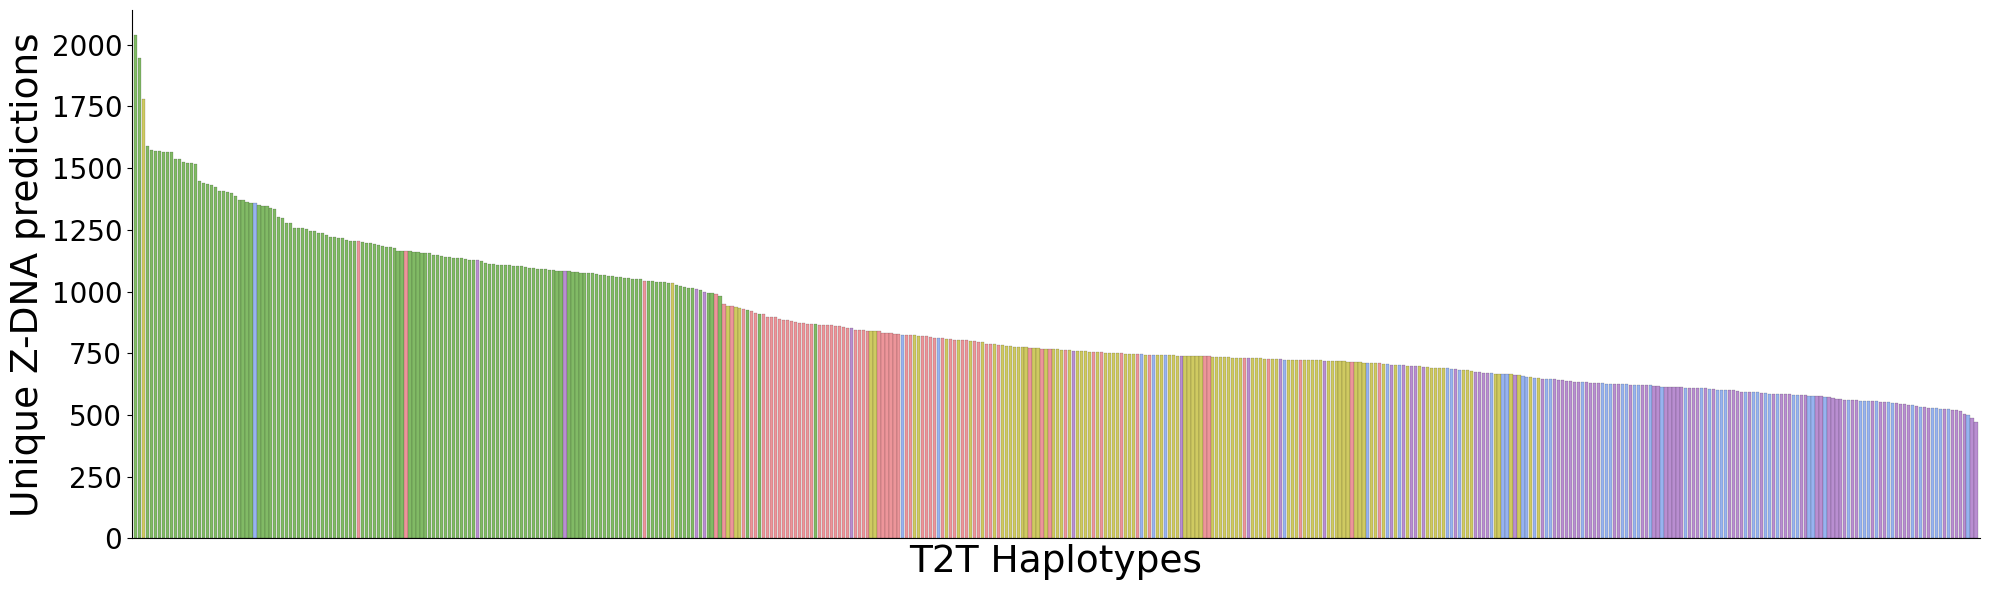

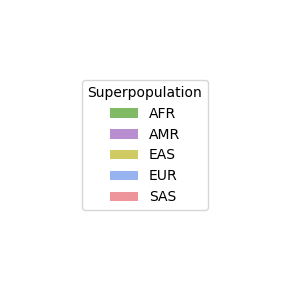

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")
# ----------------------------------------------------------
# Load data
# ----------------------------------------------------------
df = pd.read_csv("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv", sep="\t", dtype=str)

# Convert counts to numeric, drop rows where n_unique_sequences is empty or non-numeric
df["n_unique_sequences"] = pd.to_numeric(df["n_unique_sequences"], errors="coerce")
df = df.dropna(subset=["n_unique_sequences"])

# Sort descending by count
df = df.sort_values("n_unique_sequences", ascending=False).reset_index(drop=True)

# ----------------------------------------------------------
# Superpopulation color palette (YOU CAN EDIT THESE HEX CODES)
# ----------------------------------------------------------
# superpop_colors = {
#     "AFR": "#1f77b4",
#     "AMR": "#ff7f0e",
#     "EAS": "#2ca02c",
#     "EUR": "#d62728",
#     "SAS": "#9467bd",
#     "": "#7f7f7f",      # for empty superpop rows (if any)
# }
superpop_colors = {
    "AFR": "#81BA65",
    "AMR": "#B98ED1",
    "EAS": "#CFCA61",
    "EUR": "#97B3F0",
    "SAS": "#ED959A",
    "": "#7f7f7f",
}
# Map colors, fallback to gray
df["color"] = df["superpopulation"].map(superpop_colors).fillna("#7f7f7f")

# ----------------------------------------------------------
# Create main bar plot
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(20, 6))

ax.bar(
    x=range(len(df)),
    height=df["n_unique_sequences"],
    color=df["color"],
    edgecolor="black",
    linewidth=0.1   # very thin outlines
)
ax.tick_params(axis="y", labelsize=20)
# Axis labels
ax.set_ylabel("Unique Z-DNA predictions", fontsize=27)
ax.set_xlabel("T2T Haplotypes", fontsize=27)

# Remove x ticks (460 bars → meaningless)
ax.set_xticks([])
ax.set_xlim(-1, len(df))

# Make plot cleaner
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("unique_sequences_barplot.png", dpi=300)
plt.show()

# ----------------------------------------------------------
# Save separate legend
# ----------------------------------------------------------
fig_leg, ax_leg = plt.subplots(figsize=(3, 3))

# Create legend handles
handles = []
labels = []

for sp, c in superpop_colors.items():
    if sp == "":
        continue  # skip empty category
    h = ax_leg.bar(0, 0, color=c)  # invisible proxy bar
    handles.append(h)
    labels.append(sp)


ax_leg.legend(handles, labels, title="Superpopulation", loc="center")
ax_leg.axis("off")

plt.tight_layout()
plt.savefig("superpopulation_legend.png", dpi=600)
plt.show()


Shared sequences: 52267
Unique sequences: 401855


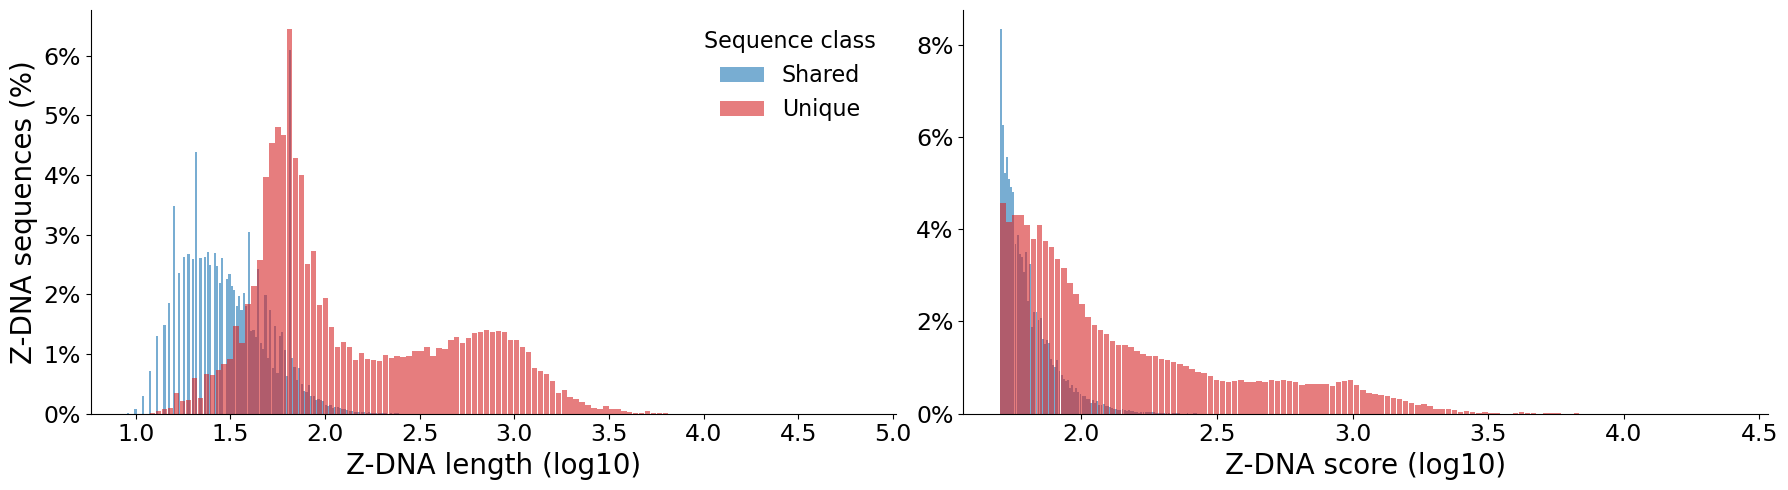


--- Length (raw) ---
U statistic: 1.8481e+10
Z statistic: 283.0070
Raw p-value (true, unrounded): 0.0000e+00
Bonferroni-corrected p-value: 0.0000e+00
Effect size r: 0.4200

--- Score (raw) ---
U statistic: 1.7144e+10
Z statistic: 235.5830
Raw p-value (true, unrounded): 0.0000e+00
Bonferroni-corrected p-value: 0.0000e+00
Effect size r: 0.3496


In [11]:
import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------------------------
# Load data
# --------------------------------------------------------------------
shared = pd.read_csv("all_shared_sequences.tsv", sep="\t")
unique = pd.read_csv("all_unique_sequences.tsv", sep="\t")

shared["length"] = shared["length"].astype(float)
shared["score"]  = shared["score"].astype(float)
unique["length"] = unique["length"].astype(float)
unique["score"]  = unique["score"].astype(float)

# log10 transforms
shared["log10_length"] = np.log10(shared["length"])
shared["log10_score"]  = np.log10(shared["score"])

unique["log10_length"] = np.log10(unique["length"])
unique["log10_score"]  = np.log10(unique["score"])

# --------------------------------------------------------------------
# Percentage-normalized histogram helper
# --------------------------------------------------------------------
def hist_percentage(ax, values, bins, color, label):
    counts, bin_edges = np.histogram(values, bins=bins)
    percentages = counts / counts.sum() * 100
    ax.bar(
        (bin_edges[:-1] + bin_edges[1:]) / 2,
        percentages,
        width=(bin_edges[1] - bin_edges[0]) * 0.9,
        alpha=0.6,
        color=color,
        label=label,
    )

# --------------------------------------------------------------------
# Plot setup
# --------------------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(18, 5))

colors = {
    "shared": "#1f77b4",
    "unique": "#d62728",
}

# More bins = thinner bars (nuanced distribution)
bins_length = 120
bins_score  = 120

# --------------------------------------------------------------------
# LEFT PANEL — log10(length)
# --------------------------------------------------------------------
hist_percentage(
    axs[0],
    shared["log10_length"],
    bins=bins_length,
    color=colors["shared"],
    label="Shared"
)

hist_percentage(
    axs[0],
    unique["log10_length"],
    bins=bins_length,
    color=colors["unique"],
    label="Unique"
)

axs[0].set_xlabel("Z-DNA length (log10)", fontsize=20)
axs[0].set_ylabel("Z-DNA sequences (%)", fontsize=20)

# Despine
axs[0].spines["right"].set_visible(False)
axs[0].spines["top"].set_visible(False)
axs[0].tick_params(axis='both', labelsize=17)


# Integer percentage ticks
axs[0].yaxis.set_major_formatter(lambda x, _: f"{int(x)}%")

# --------------------------------------------------------------------
# RIGHT PANEL — log10(score)
# --------------------------------------------------------------------
hist_percentage(
    axs[1],
    shared["log10_score"],
    bins=bins_score,
    color=colors["shared"],
    label="Shared"
)

hist_percentage(
    axs[1],
    unique["log10_score"],
    bins=bins_score,
    color=colors["unique"],
    label="Unique"
)

axs[1].set_xlabel("Z-DNA score (log10)", fontsize=20)

# Despine
axs[1].spines["right"].set_visible(False)
axs[1].spines["top"].set_visible(False)
axs[1].tick_params(axis='both', labelsize=17)
# No redundant y-label
axs[1].set_ylabel("")

# Integer percentage ticks
axs[1].yaxis.set_major_formatter(lambda x, _: f"{int(x)}%")

# --------------------------------------------------------------------
# Legend only once
# --------------------------------------------------------------------
axs[0].legend(title="Sequence class", frameon=False, fontsize=16, title_fontsize=16)


# --------------------------------------------------------------------
# Print counts
# --------------------------------------------------------------------
print(f"Shared sequences: {len(shared)}")
print(f"Unique sequences: {len(unique)}")

# --------------------------------------------------------------------
# Final layout
# --------------------------------------------------------------------
plt.tight_layout()
plt.savefig("scorelen_uniquevsshared.png", dpi=600)
plt.show()
from scipy.stats import mannwhitneyu, norm
import numpy as np


def mw_test_true_p(x, y, label, alternative="two-sided"):
    # SciPy MWU (we only use U here)
    U, _ = mannwhitneyu(x, y, alternative="two-sided")  # always two-sided here

    nx, ny = len(x), len(y)

    # Expected mean and SD under H0
    mean_U = nx * ny / 2
    sd_U   = np.sqrt(nx * ny * (nx + ny + 1) / 12)

    # Z-statistic
    Z = (U - mean_U) / sd_U

    # Get one-sided or two-sided p-values manually
    if alternative == "greater":
        # x > y
        p = norm.sf(Z)           # sf = 1 - cdf = P(Z > observed Z)
    elif alternative == "less":
        # x < y
        p = norm.cdf(Z)
    else:
        # two-sided
        p = 2 * norm.sf(abs(Z))

    # Bonferroni correction (2 tests = length + score)
    p_bonf = min(p * 2, 1.0)

    # Effect size r
    r = abs(Z) / np.sqrt(nx + ny)

    print(f"\n--- {label} ---")
    print(f"U statistic: {U:.4e}")
    print(f"Z statistic: {Z:.4f}")
    print(f"Raw p-value (true, unrounded): {p:.4e}")
    print(f"Bonferroni-corrected p-value: {p_bonf:.4e}")
    print(f"Effect size r: {r:.4f}")


# --------------------------------------------------------------------
# Run tests with your intended direction:
# unique > shared  →  alternative="greater"
# --------------------------------------------------------------------

mw_test_true_p(unique["length"], shared["length"], 
               "Length (raw)", alternative="greater")

mw_test_true_p(unique["score"], shared["score"], 
               "Score (raw)", alternative="greater")

In [9]:
print("Median(shared length) =", shared["length"].median())
print("Median(unique length) =", unique["length"].median())

print("Median(shared score)  =", shared["score"].median())
print("Median(unique score)  =", unique["score"].median())


Median(shared length) = 32.0
Median(unique length) = 83.0
Median(shared score)  = 59.25
Median(unique score)  = 101.0


In [16]:
#!/usr/bin/env python3
import pandas as pd
from pathlib import Path
from tqdm import tqdm

# --------------------------------------------------------------------
# Paths
# --------------------------------------------------------------------
meta_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv")
csv_dir   = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_csvs_mapped")

ref_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv")
out_tsv  = Path("/work/10906/geomeg/vista/pangenomes_zdna/shared_with_reference_by_chr.tsv")

# --------------------------------------------------------------------
# Load metadata → identify haplotype rows
# --------------------------------------------------------------------
meta = pd.read_csv(meta_path, sep="\t", dtype=str)
meta.fillna("", inplace=True)

mask_hn = meta["sample_id"].str.startswith(("H", "N"))
meta_haps = meta[mask_hn].copy()

# We will use the filenames in the metadata table
haplotype_files = dict(zip(meta_haps["filename"], meta_haps["sample_id"]))

# --------------------------------------------------------------------
# Chromosomes to evaluate
# --------------------------------------------------------------------
CHR_LIST = [f"chr{i}" for i in range(1, 23)]

# --------------------------------------------------------------------
# Load reference genome → per-chromosome sequence sets
# --------------------------------------------------------------------
print("Loading reference genome Z-DNA predictions...")

ref_df = pd.read_csv(ref_path, dtype=str)
ref_df["Sequence"] = ref_df["Sequence"].astype(str)
# Load chromosome mapping: NC_ accession → UCSC chr name
map_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv")
chrom_map = pd.read_csv(map_path, sep="\t", dtype=str)

# Build dictionary: "NC_060925.1" → "chr1"
refseq_to_chr = dict(zip(chrom_map["refseq_accession"], chrom_map["ucsc_pansn_name"]))

# Replace NC codes in reference dataframe with UCSC-style chr names
ref_df["Chromosome"] = ref_df["Chromosome"].map(refseq_to_chr)

# Keep only autosomes (chr1–chr22)
ref_df = ref_df[ref_df["Chromosome"].isin([f"chr{i}" for i in range(1, 23)])]

# keep only autosomes
ref_df = ref_df[ref_df["Chromosome"].isin(CHR_LIST)]

# build: ref_seqs[chrom] = set(sequences)
ref_seqs = {
    chrom: set(ref_df[ref_df["Chromosome"] == chrom]["Sequence"])
    for chrom in CHR_LIST
}

# number of unique sequences per chromosome (denominator)
ref_counts = {chrom: len(ref_seqs[chrom]) for chrom in CHR_LIST}

# --------------------------------------------------------------------
# Load haplotypes → per-chromosome sequence sets
# --------------------------------------------------------------------
print("Loading haplotype CSVs...")

hap_chrom_sets = {}   # filename → {chrom: set(seqs)}

for filename in tqdm(haplotype_files.keys(), desc="Reading haplotypes"):
    fpath = csv_dir / filename

    if not fpath.exists():
        print(f"⚠ Missing haplotype file: {filename}")
        continue

    df = pd.read_csv(fpath, dtype=str)
    df["Sequence"] = df["Sequence"].astype(str)
    
    # Normalize haplotype chromosome names
    df["Chromosome"] = (
        df["Chromosome"]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)   # convert chr1.0 → chr1
        .str.replace("^chr", "", regex=True)    # drop chr prefix for clean rebuild
        .str.strip()
    )
    df["Chromosome"] = "chr" + df["Chromosome"]
    
    # Keep only chr1..chr22
    df = df[df["Chromosome"].isin(CHR_LIST)]


    # build per-chrom dict
    chrom_dict = {}
    for chrom in CHR_LIST:
        chrom_df = df[df["Chromosome"] == chrom]
        if len(chrom_df) == 0:
            chrom_dict[chrom] = None   # mark as absent
        else:
            chrom_dict[chrom] = set(chrom_df["Sequence"])

    hap_chrom_sets[filename] = chrom_dict

# --------------------------------------------------------------------
# Compute intersection percentages
# --------------------------------------------------------------------
rows = []

for filename, chrom_dict in hap_chrom_sets.items():
    sample_id = haplotype_files[filename]

    row = {"sample_id": sample_id, "filename": filename}

    for chrom in CHR_LIST:
        if chrom_dict[chrom] is None:
            row[chrom] = ""       # chromosome missing in haplotype
        else:
            # intersection with reference
            shared = chrom_dict[chrom].intersection(ref_seqs[chrom])

            if ref_counts[chrom] == 0:
                row[chrom] = ""   # reference has no sequences
            else:
                # percentage = shared / total_ref
                frac = len(shared) / ref_counts[chrom]

                # 0 if shared==0; real number otherwise
                row[chrom] = round(frac, 6) if len(shared) > 0 else 0

    rows.append(row)

# --------------------------------------------------------------------
# Output
# --------------------------------------------------------------------
result_df = pd.DataFrame(rows)
result_df = result_df[["sample_id", "filename"] + CHR_LIST]

result_df.to_csv(out_tsv, sep="\t", index=False)

print(f"\n✅ Wrote output to: {out_tsv}")
print(result_df.head())


Loading reference genome Z-DNA predictions...
Loading haplotype CSVs...


Reading haplotypes: 100%|█████████████████████████████████████████████████████████████| 464/464 [05:54<00:00,  1.31it/s]



✅ Wrote output to: /work/10906/geomeg/vista/pangenomes_zdna/shared_with_reference_by_chr.tsv
  sample_id                                 filename      chr1      chr2  \
0   HG00097  HG00097_hap1_hprc_r2_v1.0.1.zseeker.csv  0.828371  0.805653   
1   HG00097  HG00097_hap2_hprc_r2_v1.0.1.zseeker.csv  0.827916  0.814658   
2   HG00099  HG00099_hap1_hprc_r2_v1.0.1.zseeker.csv  0.825582  0.806965   
3   HG00099  HG00099_hap2_hprc_r2_v1.0.1.zseeker.csv  0.832812  0.801717   
4   HG00126  HG00126_hap1_hprc_r2_v1.0.1.zseeker.csv  0.819719  0.818713   

       chr3      chr4      chr5      chr6      chr7      chr8  ...     chr13  \
0  0.790618  0.798670  0.805140  0.797472  0.816808  0.808929  ...  0.783365   
1  0.802115  0.794238  0.803774  0.799140  0.818846  0.818861  ...  0.777810   
2  0.795569  0.788918  0.803518  0.799842  0.816469  0.809912  ...  0.735857   
3  0.798674  0.796011  0.799334  0.800457  0.819949  0.809421  ...  0.775910   
4  0.798254  0.798316  0.807873  0.795979  0.8137

/tmp/ipykernel_2480577/1486793274.py:133: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


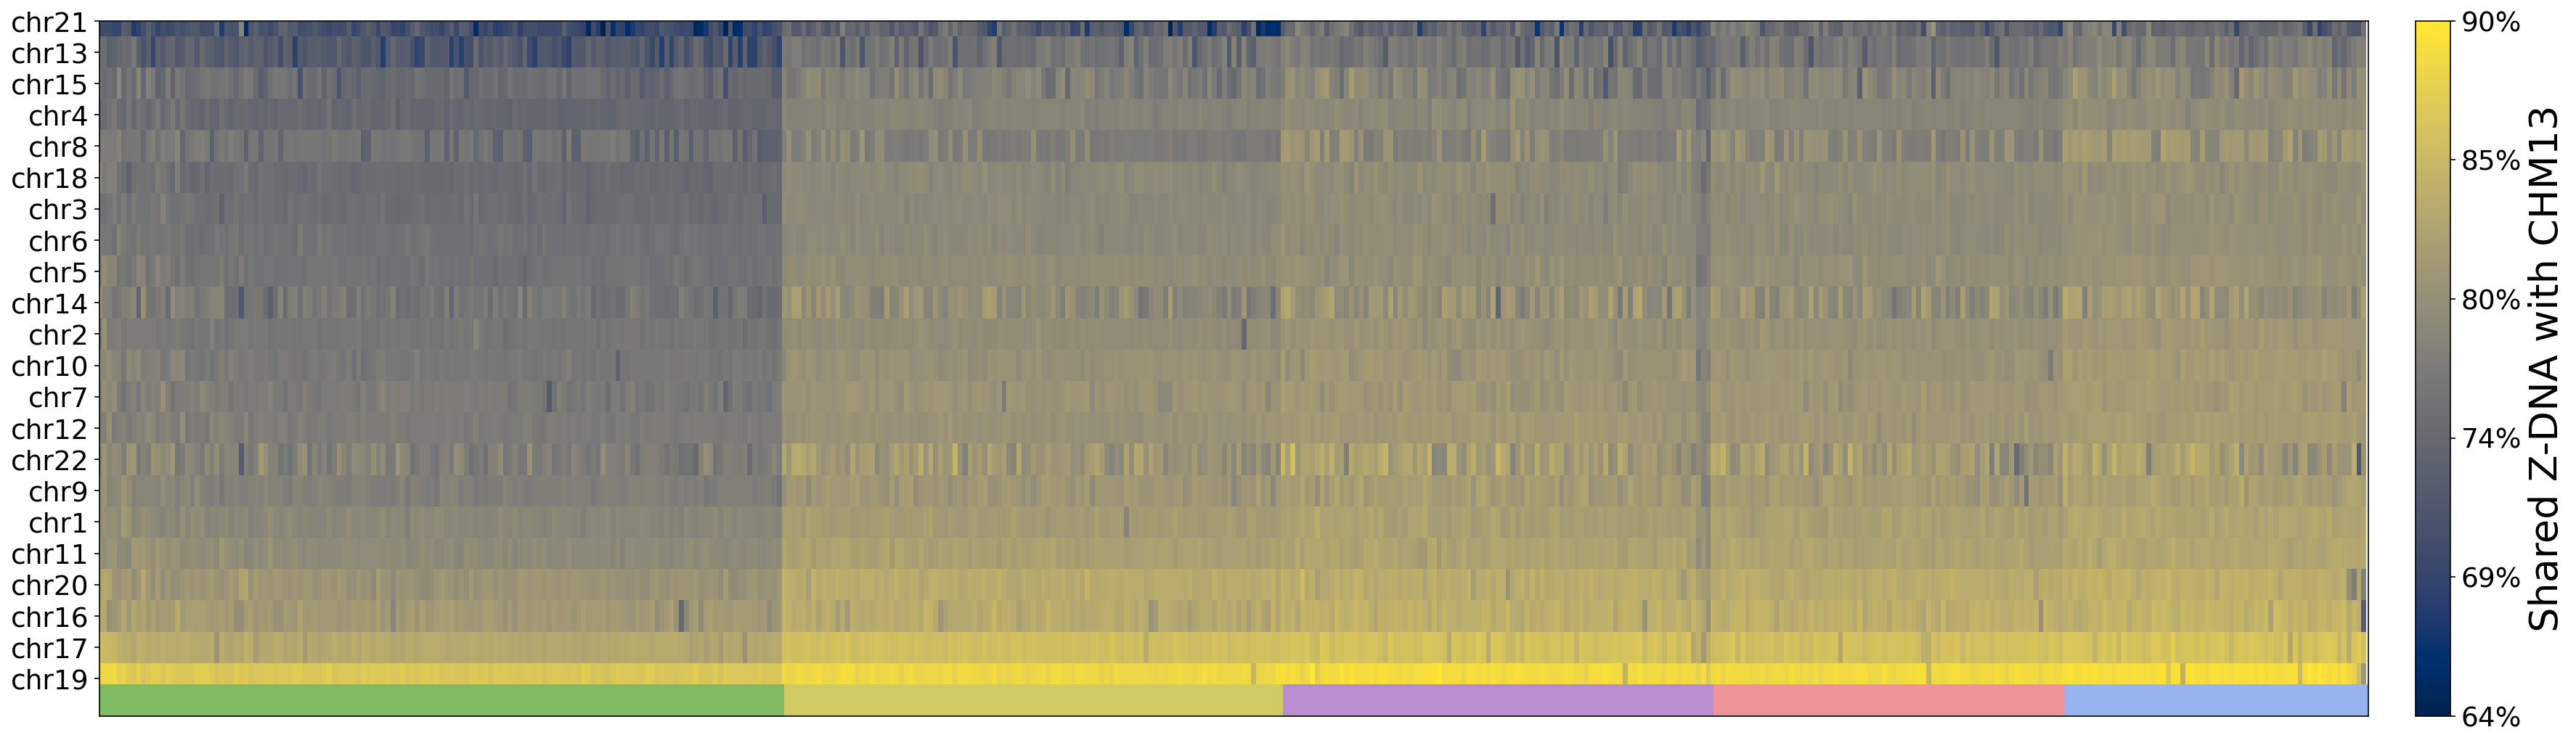

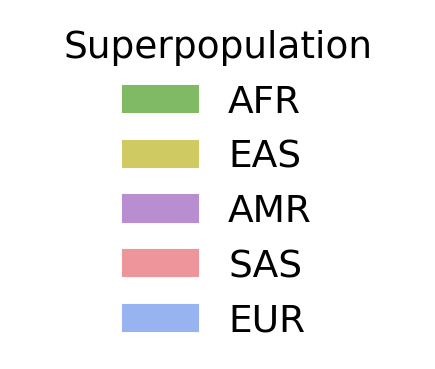

In [28]:
#!/usr/bin/env python3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patches as mpatches
import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")

# --------------------------------------------------------------------
# Load data
# --------------------------------------------------------------------
heatmap_tsv = "/work/10906/geomeg/vista/pangenomes_zdna/shared_with_reference_by_chr.tsv"
meta_path   = "/work/10906/geomeg/vista/pangenomes_zdna/hprc_zdna_metrics.tsv"

df = pd.read_csv(heatmap_tsv, sep="\t")
meta = pd.read_csv(meta_path, sep="\t", dtype=str)

# Chromosomes 1–22
chroms = [f"chr{i}" for i in range(1, 23)]

# Merge metadata
meta = meta[["sample_id", "filename", "superpopulation"]]
df = df.merge(meta, on=["sample_id", "filename"], how="left")

# --------------------------------------------------------------------
# Convert all chromosome columns to float (empty → NaN)
# --------------------------------------------------------------------
for chrom in chroms:
    df[chrom] = pd.to_numeric(df[chrom], errors="coerce")

# --------------------------------------------------------------------
# Per-haplotype mean shared (for sorting inside each superpopulation)
# --------------------------------------------------------------------
df["mean_shared"] = df[chroms].mean(axis=1, skipna=True)

# --------------------------------------------------------------------
# Sort superpopulations by descending haplotype COUNT  (largest first)
# --------------------------------------------------------------------
sp_counts = df["superpopulation"].value_counts().sort_values(ascending=False)
ordered_sps = sp_counts.index.tolist()

df["sp_rank"] = df["superpopulation"].apply(lambda x: ordered_sps.index(x))

# Sort haplotypes within each superpopulation by highest mean_shared
df_sorted = df.sort_values(["sp_rank", "mean_shared"], ascending=[True, False])

hap_order = df_sorted["filename"].tolist()
superpop_order = df_sorted["superpopulation"].tolist()

# --------------------------------------------------------------------
# SORT CHROMOSOMES by descending average shared across all haplotypes
# --------------------------------------------------------------------
chrom_means = df_sorted[chroms].mean(axis=0)
chroms_sorted = chrom_means.sort_values(ascending=False).index.tolist()

# --------------------------------------------------------------------
# Build the heatmap matrix in the sorted chromosome order
# --------------------------------------------------------------------
mat = df_sorted[chroms_sorted].T.astype(np.float32)
mat.index = chroms_sorted
mat.columns = hap_order

# --------------------------------------------------------------------
# Superpopulation color bar preparation
# --------------------------------------------------------------------
superpop_colors_hex = {
    "AFR": "#81BA65",
    "AMR": "#B98ED1",
    "EAS": "#CFCA61",
    "EUR": "#97B3F0",
    "SAS": "#ED959A",
}

def hex_to_rgb01(hex_color):
    h = hex_color.lstrip("#")
    return tuple(int(h[i:i+2], 16)/255 for i in (0, 2, 4))

# One RGB color per haplotype in left→right order
sp_color_vec = [hex_to_rgb01(superpop_colors_hex[sp]) for sp in superpop_order]

# --------------------------------------------------------------------
# PLOTTING
# --------------------------------------------------------------------
fig = plt.figure(figsize=(28, 10), dpi=150)
gs = fig.add_gridspec(2, 1, height_ratios=[14, 1], hspace=0.25)

ax = fig.add_subplot(gs[0])

# Heatmap normalization
vmin = np.nanmin(mat.values)
vmax = np.nanmax(mat.values)
norm = Normalize(vmin=vmin, vmax=vmax)

im = ax.imshow(mat, aspect='auto', cmap="cividis", norm=norm)

# --------------------------------------------------------------------
# Axis formatting
# --------------------------------------------------------------------
ax.set_yticks(np.arange(len(chroms_sorted)))
ax.set_yticklabels(chroms_sorted, fontsize=18)  # ← increased tick font

ax.set_xticks([])  # hide haplotype names

# --------------------------------------------------------------------
# Superpopulation bar drawn INSIDE heatmap axes
# --------------------------------------------------------------------
sp_bar = np.array(sp_color_vec).reshape(1, -1, 3)

extent = [0, mat.shape[1], -1.5, -0.2]
ax.imshow(sp_bar, aspect='auto', extent=extent)

ax.set_ylim(-1.2, len(chroms_sorted)-1)
ax.set_xticks([])

# --------------------------------------------------------------------
# Heatmap colorbar (percent scale)
# --------------------------------------------------------------------
cbar = fig.colorbar(
    im, ax=ax, orientation="vertical",
    fraction=0.02, pad=0.02,
    boundaries=np.linspace(vmin, vmax, 256),
    ticks=np.linspace(vmin, vmax, 6)
)

cbar.set_label("Shared Z-DNA with CHM13", fontsize=26)  # ↑ bigger label
cbar.ax.tick_params(labelsize=18)  # ↑ bigger ticks

ticks = cbar.get_ticks()
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t*100:.0f}%" for t in ticks])

plt.tight_layout()
plt.savefig("heatmap_shared.png", dpi=600, bbox_inches="tight", pad_inches=0.1)

plt.show()

# --------------------------------------------------------------------
# Separate figure for superpopulation legend
# --------------------------------------------------------------------
fig_leg, ax_leg = plt.subplots(figsize=(3, 2), dpi=150)

handles = [
    mpatches.Patch(color=superpop_colors_hex[sp], label=sp)
    for sp in ordered_sps
]

ax_leg.legend(
    handles=handles,
    loc="center",
    frameon=False,
    fontsize=18,        # ↑ increased font
    title="Superpopulation",
    title_fontsize=18   # ↑ increased font
)

ax_leg.axis('off')
plt.tight_layout()
plt.show()

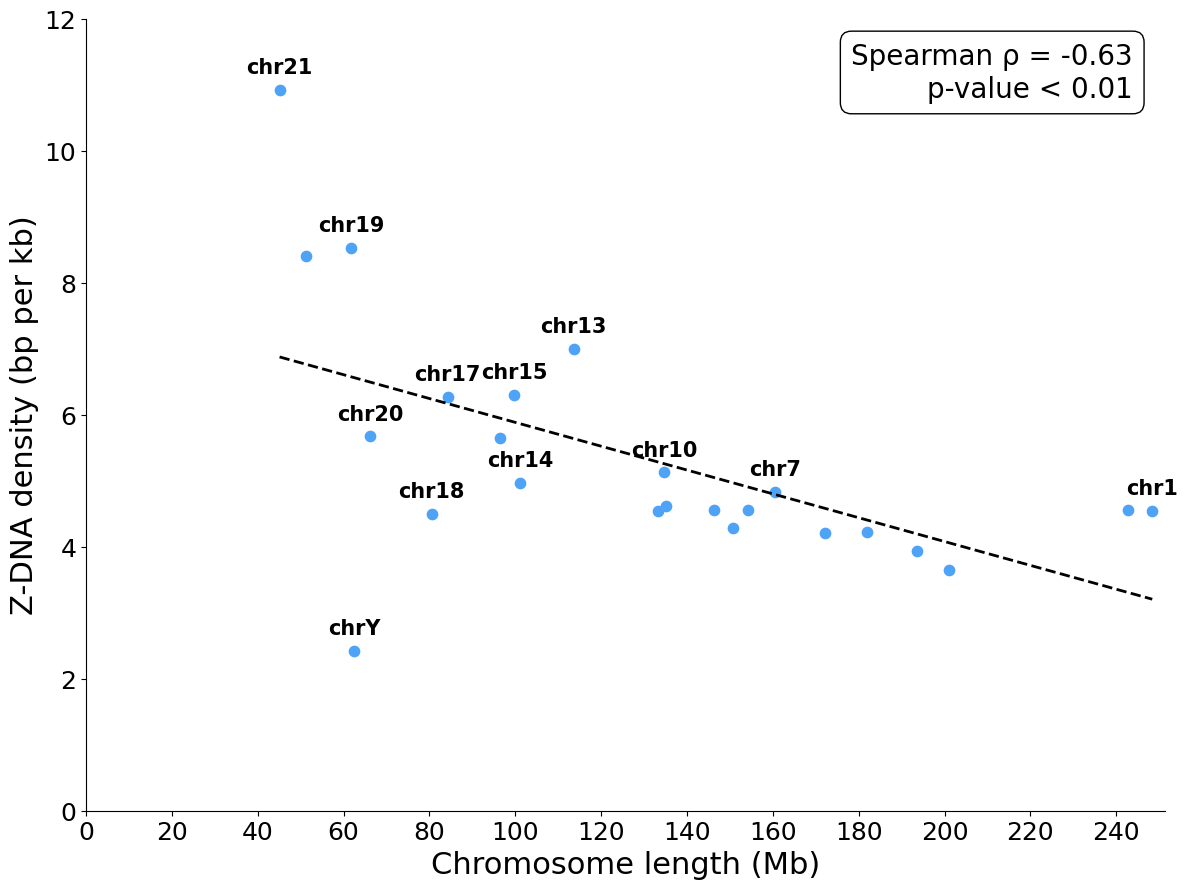

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr
import statsmodels.api as sm

# Load file
path = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
df = pd.read_csv(path, sep="\t")

# Keep needed columns
df = df[["ucsc_pansn_name", "gcf_seq_length", "gcf_zdna_density_per_kb"]].copy()

# Ensure numeric
df["gcf_seq_length"] = pd.to_numeric(df["gcf_seq_length"], errors="coerce")

# Convert bp → megabases
df["length_mb"] = df["gcf_seq_length"] / 1e6

# Chromosome order
chrom_order = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]
df["ucsc_pansn_name"] = pd.Categorical(df["ucsc_pansn_name"], categories=chrom_order, ordered=True)
df = df.sort_values("ucsc_pansn_name")

# ---------------------------------------------------------
# LINEAR regression: ZDNA density ~ length (in Mb)
# ---------------------------------------------------------
X = sm.add_constant(df["length_mb"])
model = sm.OLS(df["gcf_zdna_density_per_kb"], X).fit()
df["reg_pred"] = model.predict(X)

# Spearman correlation
rho, pval = spearmanr(df["length_mb"], df["gcf_zdna_density_per_kb"])
p_text = "p-value < 0.01" if pval < 0.01 else f"p-value = {pval:.2e}"

# Smooth regression line
x_smooth = np.linspace(df["length_mb"].min(),
                       df["length_mb"].max(), 300)
X_smooth = sm.add_constant(x_smooth)
y_smooth = model.predict(X_smooth)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
plt.figure(figsize=(12, 9))

plt.scatter(
    df["length_mb"],
    df["gcf_zdna_density_per_kb"],
    color="#4FA3F7",
    s=55
)

plt.plot(x_smooth, y_smooth, '--', color='black', linewidth=2)

# Skip annotation list
skip = {"chr16", "chr11", "chr12", "chr3", "chr4", "chr5",
        "chr6", "chr8", "chr9", "chrX", "chr2", "chr22"}

# Annotate selected
for _, row in df.iterrows():
    if row["ucsc_pansn_name"] in skip:
        continue

    plt.text(
        row["length_mb"],
        row["gcf_zdna_density_per_kb"] + 0.25,
        row["ucsc_pansn_name"],
        ha="center",
        fontsize=15,
        fontweight="bold"
    )

# ---------------------------------------------------------
# Set X-axis limits with padding
# ---------------------------------------------------------
xmin = df["length_mb"].min()
xmax = df["length_mb"].max()
xrange = xmax - xmin

left_pad  = xrange * 0.015
right_pad = xrange * 0.015

plt.xlim(xmin - left_pad, xmax + right_pad)
# ---------------------------------------------------------
# X-axis ticks in Mb (integer or nice stepping)
# ---------------------------------------------------------
max_mb = int(np.ceil(xmax / 10) * 10)  # round to nearest 10
ticks = np.arange(0, max_mb + 1, 20)   # tick every 20 Mb
plt.xticks(ticks)

plt.xlabel("Chromosome length (Mb)", fontsize=22)
plt.ylabel("Z-DNA density (bp per kb)", fontsize=22)
plt.ylim(0, 12)
plt.tick_params(axis='both', which='major', labelsize=18)

# Correlation inset
text = f"Spearman ρ = {rho:.2f}\n{p_text}"
plt.text(
    0.97, 0.97, text,
    transform=plt.gca().transAxes,
    fontsize=20,
    ha="right", va="top",
    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.4")
)

# Clean frame
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/chr_length_density_Mb", dpi=600)
plt.show()


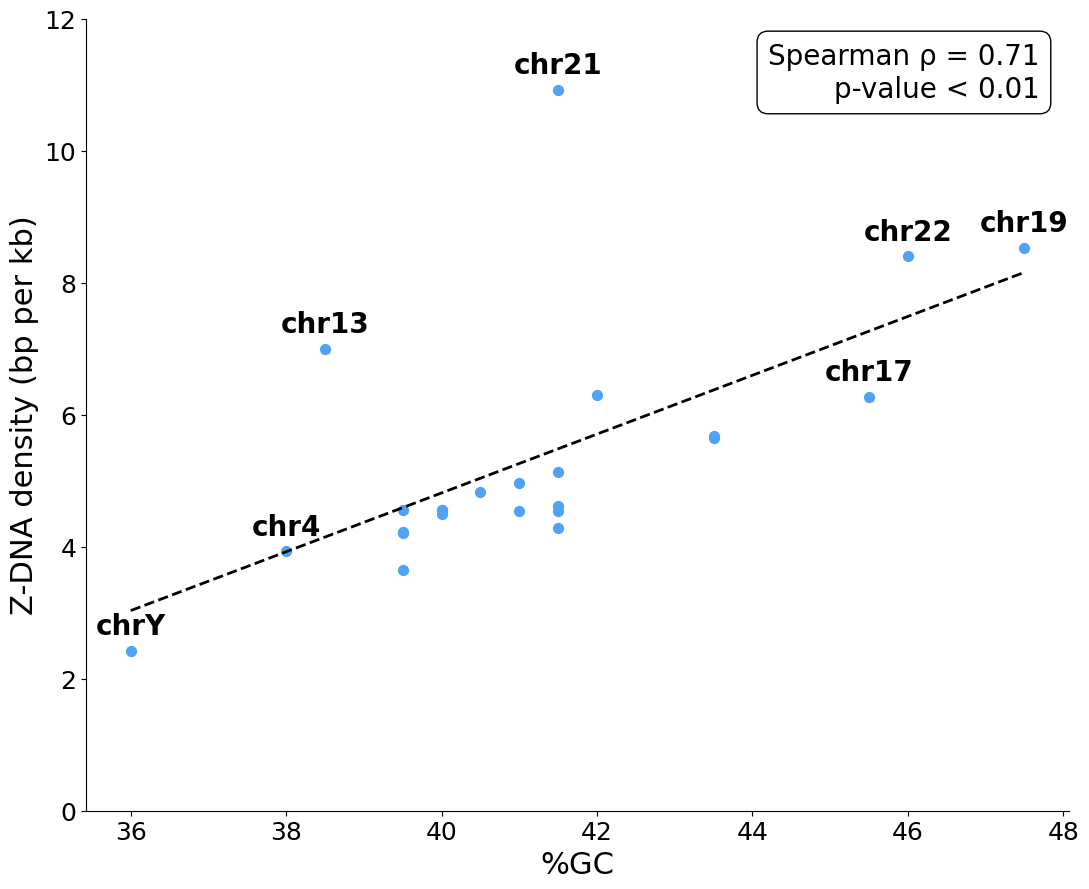

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr
import statsmodels.api as sm

# Load file
path = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
df = pd.read_csv(path, sep="\t")

# Keep only needed
df = df[["ucsc_pansn_name", "gc_percent", "gcf_zdna_density_per_kb"]].copy()

# Chromosome order
chrom_order = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]
df["ucsc_pansn_name"] = pd.Categorical(df["ucsc_pansn_name"], categories=chrom_order, ordered=True)
df = df.sort_values("ucsc_pansn_name")

# Spearman correlation
rho, pval = spearmanr(df["gc_percent"], df["gcf_zdna_density_per_kb"])
p_text = "p-value < 0.01" if pval < 0.01 else f"p-value = {pval:.2e}"

# Regression
X = sm.add_constant(df["gc_percent"])
model = sm.OLS(df["gcf_zdna_density_per_kb"], X).fit()
df["reg_pred"] = model.predict(X)

# Identify chromosomes to annotate
lowest_gc = df.nsmallest(3, "gc_percent")["ucsc_pansn_name"].tolist()
highest_gc = df.nlargest(3, "gc_percent")["ucsc_pansn_name"].tolist()
extra = ["chr13", "chr21"]

annotate_set = set(lowest_gc + highest_gc + extra)

# Plot
plt.figure(figsize=(11, 9))

# lighter blue
plt.scatter(df["gc_percent"],
            df["gcf_zdna_density_per_kb"],
            color="#4FA3F7",
            s=50)  # smaller dots

# Regression line (smooth)
x_smooth = np.linspace(df["gc_percent"].min(),
                       df["gc_percent"].max(), 300)

X_smooth = sm.add_constant(x_smooth)   # <-- FIX
y_smooth = model.predict(X_smooth)

plt.plot(x_smooth, y_smooth, '--', color='black', linewidth=2)

# Annotate selected chromosomes
for _, row in df.iterrows():
    if row["ucsc_pansn_name"] in annotate_set:
        plt.text(
            row["gc_percent"],
            row["gcf_zdna_density_per_kb"] + 0.25,
            row["ucsc_pansn_name"],
            ha="center",
            fontsize=20,        # larger text
            fontweight="bold"
        )

# Labels and limits
plt.tick_params(axis='both', which='major', labelsize=18)
plt.xlabel("%GC", fontsize=22)
plt.ylabel("Z-DNA density (bp per kb)", fontsize=22)
plt.ylim(0, 12)

# Correlation panel
text = f"Spearman ρ = {rho:.2f}\n{p_text}"
plt.text(
    0.97, 0.97, text,
    transform=plt.gca().transAxes,
    fontsize=20,
    ha="right", va="top",
    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.4")
)

# Despine
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("/work/10906/geomeg/vista/pangenomes_zdna/gc_density_per_chr", dpi=600)
plt.show()


## Figure 2

In [3]:
#!/usr/bin/env python3
import os
import pandas as pd
import numpy as np
import pyranges as pr

############################################################
# HELPERS
############################################################

def first_attribute(val):
    if pd.isna(val):
        return ""
    return str(val).split(";", 1)[0]


############################################################
# GFF READER – ALL FEATURES EXCEPT "region", NO SOURCE/ATTRIBUTES IN OUTPUT
############################################################

def read_gff(gff_path: str) -> pr.PyRanges:
    """
    Load GFF3 and return essential columns:
      Chromosome, Start, End, Strand, Feature, feature_ID
    All features are kept EXCEPT 'region'.
    """
    gr = pr.read_gff3(gff_path)
    gdf = gr.df.copy()

    required = {"Chromosome", "Start", "End", "Feature"}
    if not required.issubset(gdf.columns):
        return pr.PyRanges(
            pd.DataFrame(columns=["Chromosome", "Start", "End", "Strand", "Feature", "feature_ID"])
        )

    # Normalize strand
    if "Strand" in gdf.columns:
        gdf["Strand"] = gdf["Strand"].astype(str).replace({"*": "."})
        gdf.loc[~gdf["Strand"].isin(["+", "-", "."]), "Strand"] = "."
    else:
        gdf["Strand"] = "."

    # Attributes column (used only as fallback for feature_ID if needed)
    attr_col = "Attributes" if "Attributes" in gdf.columns else None
    if attr_col is None:
        gdf["Attributes"] = ""
        attr_col = "Attributes"

    # Build feature_ID
    fid = pd.Series("", index=gdf.index, dtype="string")

    # 1) Prefer ID
    if "ID" in gdf.columns:
        fid = gdf["ID"].astype("string").fillna("")

    # 2) Fill empties from common ID-like columns
    for c in ["gene_id", "locus_tag", "Parent", "Name", "gene", "transcript_id", "protein_id"]:
        if c in gdf.columns:
            s = gdf[c].astype("string").fillna("")
            fid = fid.mask((fid == "") | fid.isna(), s)

    # 3) Still empty? Use first attribute token
    attrs_first = gdf[attr_col].astype("string").fillna("").map(first_attribute)
    fid = fid.mask((fid == "") | fid.isna(), attrs_first)

    gdf["feature_ID"] = fid.fillna("").astype(str)

    # Drop "region" features completely
    gdf = gdf[gdf["Feature"] != "region"].copy()

    # Keep only the columns we need
    keep = ["Chromosome", "Start", "End", "Strand", "Feature", "feature_ID"]
    gdf = gdf[keep].dropna(subset=["Chromosome", "Start", "End"])

    # Drop exact duplicates
    gdf = gdf.drop_duplicates(
        subset=["Chromosome", "Start", "End", "Strand", "Feature", "feature_ID"]
    )

    gdf["Start"] = gdf["Start"].astype(int)
    gdf["End"] = gdf["End"].astype(int)

    return pr.PyRanges(gdf)


############################################################
# ZSEEKER READER – DROP NA SENTINEL ROWS
############################################################

def read_zfile(z_path: str) -> pd.DataFrame:
    """
    Read ZSeeker CSV and normalize to:
      Chromosome, Start, End, Z-DNA Score, Sequence

    Rows where Start/End are NA (NA sentinel for 'no Z on chromosome')
    are dropped here; their effect is represented by feature-only rows.
    """
    try:
        raw = pd.read_csv(z_path)
    except Exception as e:
        print(f"[WARN] Could not read Z file {z_path}: {e}. Treating as empty.")
        return pd.DataFrame(columns=["Chromosome", "Start", "End", "Z-DNA Score", "Sequence"])

    if raw.empty:
        return pd.DataFrame(columns=["Chromosome", "Start", "End", "Z-DNA Score", "Sequence"])

    lc = {c.lower(): c for c in raw.columns}

    def pick(*opts):
        for o in opts:
            if o in lc:
                return lc[o]
        return None

    c_chr = pick("chromosome", "chr")
    c_sta = pick("start", "begin", "from")
    c_end = pick("end", "stop", "to")
    c_sc  = pick("z-dna score", "zdna score", "z_dna score", "zdna_score", "zscore", "score")
    c_seq = pick("sequence", "seq")

    z = pd.DataFrame({
        "Chromosome": raw[c_chr] if c_chr else pd.Series(dtype="object"),
        "Start":      pd.to_numeric(raw[c_sta], errors="coerce") if c_sta else pd.Series(dtype="float64"),
        "End":        pd.to_numeric(raw[c_end], errors="coerce") if c_end else pd.Series(dtype="float64"),
        "Z-DNA Score":pd.to_numeric(raw[c_sc],  errors="coerce") if c_sc else pd.Series(dtype="float64"),
        "Sequence":   raw[c_seq] if c_seq else pd.Series(dtype="object"),
    })

    # Drop NA-sentinel rows (no real Z on that chromosome)
    z_valid = z.dropna(subset=["Start", "End"]).copy()
    return z_valid


############################################################
# BUILD PYRANGES FOR Z
############################################################

def z_to_pyranges(zdf: pd.DataFrame) -> pr.PyRanges:
    if zdf.empty:
        return pr.PyRanges(pd.DataFrame(
            columns=["Chromosome", "Start", "End", "Strand", "Z-DNA Score", "Sequence"]
        ))
    zdf = zdf.copy()
    zdf["Start"] = zdf["Start"].astype(int)
    zdf["End"]   = zdf["End"].astype(int)
    zdf["Strand"] = "."
    return pr.PyRanges(zdf[["Chromosome", "Start", "End", "Strand", "Z-DNA Score", "Sequence"]])


############################################################
# OVERLAPS: 1 ROW PER (FEATURE, Z) PAIR
############################################################

def compute_overlaps(feat: pr.PyRanges, z: pr.PyRanges) -> pd.DataFrame:
    if len(feat) == 0 or len(z) == 0:
        return pd.DataFrame(columns=[
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_end",
            "feature_strand",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_score",
            "zdna_sequence",
        ])

    ov = feat.join(z, strandedness=False)
    if ov.df.empty:
        return pd.DataFrame(columns=[
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_end",
            "feature_strand",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_score",
            "zdna_sequence",
        ])

    d = ov.df
    return pd.DataFrame({
        "chromosome":     d["Chromosome"],
        "feature_type":   d["Feature"],
        "feature_start":  d["Start"],
        "feature_end":    d["End"],
        "feature_strand": d["Strand"],
        "feature_ID":     d["feature_ID"],
        "zdna_start":     d["Start_b"],
        "zdna_end":       d["End_b"],
        "zdna_score":     d["Z-DNA Score"],
        "zdna_sequence":  d["Sequence"],
    })


############################################################
# FEATURE-ONLY ROWS (NO Z OVERLAP)
############################################################

def feature_only(feat_df: pd.DataFrame, ov_feat_keys: pd.DataFrame) -> pd.DataFrame:
    if feat_df.empty:
        return pd.DataFrame(columns=[
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_end",
            "feature_strand",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_score",
            "zdna_sequence",
        ])

    if ov_feat_keys is None or ov_feat_keys.empty:
        # No features overlapped any Z: all features become feature-only
        f = feat_df.copy()
    else:
        merged = feat_df.merge(
            ov_feat_keys.drop_duplicates(),
            how="left",
            on=["Chromosome", "Feature", "Start", "End", "Strand", "feature_ID"],
            indicator=True,
        )
        f = merged[merged["_merge"] == "left_only"].drop(columns=["_merge"])

    if f.empty:
        return pd.DataFrame(columns=[
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_end",
            "feature_strand",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_score",
            "zdna_sequence",
        ])

    return pd.DataFrame({
        "chromosome":     f["Chromosome"],
        "feature_type":   f["Feature"],
        "feature_start":  f["Start"],
        "feature_end":    f["End"],
        "feature_strand": f["Strand"],
        "feature_ID":     f["feature_ID"],
        "zdna_start":     np.nan,
        "zdna_end":       np.nan,
        "zdna_score":     np.nan,
        "zdna_sequence":  np.nan,
    })


############################################################
# Z-ONLY ROWS (INTERGENIC)
############################################################

def z_only(zdf: pd.DataFrame, ov_z_keys: pd.DataFrame) -> pd.DataFrame:
    if zdf.empty:
        return pd.DataFrame(columns=[
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_end",
            "feature_strand",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_score",
            "zdna_sequence",
        ])

    if ov_z_keys is None or ov_z_keys.empty:
        merged = zdf.copy()
        merged["_merge"] = "left_only"
    else:
        merged = zdf.merge(
            ov_z_keys.drop_duplicates(),
            how="left",
            left_on=["Chromosome", "Start", "End"],
            right_on=["Chromosome", "Start_b", "End_b"],
            indicator=True,
        )

    z = merged[merged["_merge"] == "left_only"].drop(columns=[c for c in ["_merge","Start_b","End_b"] if c in merged.columns])
    if z.empty:
        return pd.DataFrame(columns=[
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_end",
            "feature_strand",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_score",
            "zdna_sequence",
        ])

    return pd.DataFrame({
        "chromosome":     z["Chromosome"],
        "feature_type":   pd.Series([np.nan] * len(z)),
        "feature_start":  pd.Series([np.nan] * len(z)),
        "feature_end":    pd.Series([np.nan] * len(z)),
        "feature_strand": pd.Series([np.nan] * len(z)),
        "feature_ID":     pd.Series([np.nan] * len(z)),
        "zdna_start":     z["Start"].astype(int),
        "zdna_end":       z["End"].astype(int),
        "zdna_score":     z["Z-DNA Score"],
        "zdna_sequence":  z["Sequence"],
    })


############################################################
# FINALIZE: ADD LENGTHS, SET DTYPES, COLUMN ORDER
############################################################

def finalize(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Inclusive lengths: end - start + 1
    df["feature_length"] = (df["feature_end"] - df["feature_start"] + 1).where(df["feature_end"].notna())
    df["zdna_length"]    = (df["zdna_end"]    - df["zdna_start"]    + 1).where(df["zdna_end"].notna())

    df = df[
        [
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_length",
            "feature_end",
            "feature_strand",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_length",
            "zdna_score",
            "zdna_sequence",
        ]
    ]

    intcols = ["feature_start", "feature_end", "feature_length", "zdna_start", "zdna_end", "zdna_length"]
    for c in intcols:
        df[c] = df[c].astype("Int64")

    strcols = ["chromosome", "feature_type", "feature_strand", "feature_ID", "zdna_sequence"]
    for c in strcols:
        df[c] = df[c].astype("string")

    df["zdna_score"] = df["zdna_score"].astype("float64")

    return df


############################################################
# RUN ONE PAIR
############################################################

def annotate_pair(gff_path: str, z_path: str, out_path: str):
    print(f"[INFO] Annotating\n  GFF: {gff_path}\n  Z  : {z_path}\n  OUT: {out_path}")

    feat = read_gff(gff_path)
    feat_df = feat.df.copy()

    zdf = read_zfile(z_path)
    z_pr = z_to_pyranges(zdf)

    ov = compute_overlaps(feat, z_pr)

    # Keys for anti-joins
    if ov.empty:
        ov_feat_keys = pd.DataFrame(columns=["Chromosome", "Feature", "Start", "End", "Strand", "feature_ID"])
        ov_z_keys    = pd.DataFrame(columns=["Chromosome", "Start_b", "End_b"])
    else:
        ov_feat_keys = pd.DataFrame({
            "Chromosome": ov["chromosome"],
            "Feature":    ov["feature_type"],
            "Start":      ov["feature_start"],
            "End":        ov["feature_end"],
            "Strand":     ov["feature_strand"],
            "feature_ID": ov["feature_ID"],
        })
        ov_z_keys = pd.DataFrame({
            "Chromosome": ov["chromosome"],
            "Start_b":    ov["zdna_start"],
            "End_b":      ov["zdna_end"],
        })

    fonly = feature_only(feat_df, ov_feat_keys)
    zonly = z_only(zdf, ov_z_keys)

    pieces = [ov, fonly, zonly]
    pieces = [p for p in pieces if not p.empty]

    if pieces:
        combined = pd.concat(pieces, ignore_index=True)
    else:
        combined = pd.DataFrame(
            columns=[
                "chromosome",
                "feature_type",
                "feature_start",
                "feature_end",
                "feature_strand",
                "feature_ID",
                "zdna_start",
                "zdna_end",
                "zdna_score",
                "zdna_sequence",
            ]
        )

    final = finalize(combined)
    final = final[final["chromosome"].notna()].copy()

    final.to_parquet(out_path, index=False, engine="pyarrow")
    print(f"[OK] wrote {len(final)} rows → {out_path}")


############################################################
# MAIN
############################################################

def main():
    base = "/work/10906/geomeg/vista/pangenomes_zdna/tmp"

    pairs = [
        ("CHM13.chm13.gff3.gz", "CHM13_v2.0_maskedY_rCRS.fa.PanSN.zseeker.csv"),
        ("GCF_009914755.1_T2T-CHM13v2.0_genomic.gff.gz", "GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"),
    ]

    for gff, zcsv in pairs:
        g = os.path.join(base, gff)
        z = os.path.join(base, zcsv)

        root = gff.replace(".gff3.gz", "").replace(".gff.gz", "")
        out = os.path.join(base, f"{root}_ann.parquet")

        annotate_pair(g, z, out)


if __name__ == "__main__":
    main()


[INFO] Annotating
  GFF: /work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13.chm13.gff3.gz
  Z  : /work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13_v2.0_maskedY_rCRS.fa.PanSN.zseeker.csv
  OUT: /work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13.chm13_ann.parquet


/tmp/ipykernel_1530316/855158751.py:400: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(pieces, ignore_index=True)
/tmp/ipykernel_1530316/855158751.py:400: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(pieces, ignore_index=True)


[OK] wrote 5446132 rows → /work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13.chm13_ann.parquet
[INFO] Annotating
  GFF: /work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic.gff.gz
  Z  : /work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv
  OUT: /work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_ann.parquet


/tmp/ipykernel_1530316/855158751.py:400: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(pieces, ignore_index=True)


[OK] wrote 6389634 rows → /work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_ann.parquet


In [31]:
#!/usr/bin/env python3
import sys, os
import numpy as np
import pandas as pd
import pyranges as pr
import re

# ---------------- CONFIG ----------------
FEATURES = [
    "CDS",
    "exon",
    "gene",
    "lnc_RNA",
    "mRNA",
    "meiotic_recombination_region",
    "miRNA",
    "non_allelic_homologous_recombination_region",
    "primary_transcript",
    "promoter",
    "protein_binding_site",
    "pseudogene",
    "recombination_feature",
    "rRNA",
    "silencer",
    "snoRNA",
    "transcript",
    "transcriptional_cis_regulatory_region",
    "enhancer"
]


# Your annotated parquet schema columns:
# chromosome, feature_type, feature_start, feature_end, feature_length,
# feature_strand, feature_ID, zdna_start, zdna_end, zdna_length, zdna_score, zdna_sequence
 
# We will treat inputs as end-INCLUSIVE (your QC confirmed that),
# and convert to half-open for PyRanges by adding +1 to End.
END_IS_INCLUSIVE = True


# ----------------------------------------
def _to_pr(df: pd.DataFrame, chr_col: str, start_col: str, end_col: str,
           end_is_inclusive: bool = True) -> pr.PyRanges:
    """Convert to PyRanges after dropping nulls/dups and making half-open."""
    if df.empty:
        return pr.PyRanges(pd.DataFrame(columns=["Chromosome", "Start", "End"]))
    tmp = df[[chr_col, start_col, end_col]].dropna().drop_duplicates().copy()
    tmp = tmp.rename(columns={chr_col: "Chromosome", start_col: "Start", end_col: "End"})
    if end_is_inclusive:
        tmp["End"] = tmp["End"].astype("int64") + 1
    tmp["Start"] = tmp["Start"].astype("int64")
    tmp["End"]   = tmp["End"].astype("int64")
    tmp = tmp[tmp["End"] > tmp["Start"]]
    return pr.PyRanges(tmp)


def _sum_union_bp(pyr: pr.PyRanges) -> int:
    if len(pyr) == 0:
        return 0
    dfm = pyr.merge().df
    return int((dfm["End"] - dfm["Start"]).sum())


def mean_feature_coverage(pr_feat: pr.PyRanges, pr_z_union: pr.PyRanges) -> float:
    """Equal-weight mean of per-feature coverage fraction (0..1)."""
    if len(pr_feat) == 0:
        return np.nan
    feat_df = pr_feat.df.reset_index(drop=True)
    feat_len = (feat_df["End"] - feat_df["Start"]).to_numpy()
    if len(pr_z_union) == 0:
        # No Z anywhere → all features get 0 coverage
        return 0.0

    ov = pr_feat.join(pr_z_union)
    if ov.df.empty:
        return 0.0

    ovdf = ov.df
    ovdf["overlap_bp"] = np.minimum(ovdf["End"], ovdf["End_b"]) - np.maximum(ovdf["Start"], ovdf["Start_b"])

    # Map back to feature rows by coordinates
    feat_index = feat_df.reset_index().rename(columns={"index": "fidx"})
    merged = ovdf.merge(feat_index, on=["Chromosome", "Start", "End"], how="left", validate="many_to_one")
    covered = merged.groupby("fidx")["overlap_bp"].sum()

    covered_full = np.zeros(len(feat_len), dtype=np.int64)
    covered_full[covered.index.values] = covered.values
    with np.errstate(divide="ignore", invalid="ignore"):
        fracs = np.where(feat_len > 0, covered_full / feat_len, 0.0)
    return float(fracs.mean())




# Load genome size directly from CHM13 PanSN report
PAN_SN_FILE = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
chrom_info = pd.read_csv(PAN_SN_FILE, sep="\t", dtype=str)
chrom_info["gcf_seq_length"] = pd.to_numeric(chrom_info["gcf_seq_length"], errors="coerce")
CHM13_GENOME_SIZE = chrom_info["gcf_seq_length"].sum()


def per_assembly_metrics(parquet_file: str) -> dict:
    asm = "CHM13v2.0"
    df = pd.read_parquet(parquet_file)
    
    # --- genome size & E ---
    


    # --- Z union ---
    zmask = df["zdna_start"].notna() & df["zdna_end"].notna()
    pr_z  = _to_pr(df.loc[zmask], "chromosome", "zdna_start", "zdna_end", END_IS_INCLUSIVE)
    z_union = pr_z.merge() if len(pr_z) else pr_z
    total_z_bp = _sum_union_bp(z_union)

    # --- genome size & E ---
    genome_size = int(CHM13_GENOME_SIZE)

    genome_z_fraction = (total_z_bp / genome_size) if genome_size and genome_size > 0 else np.nan

    row = {
        "assembly": asm,           # plain accession only
        "genome_size": genome_size,
        "total_z_bp": int(total_z_bp),
        "genome_z_fraction": genome_z_fraction,
    }


    # Pre-extract unique feature intervals once per feature
    for feat in FEATURES:
        feats = df.loc[df["feature_type"] == feat, ["chromosome","feature_start","feature_end","feature_strand","feature_ID"]]
        if feats.empty:
            O = np.nan
            feature_bp = 0
            z_bp_in_feature = 0
            frac_cov_by_z = np.nan
        else:
            # Unique by coords + strand + ID (your spec)
            feats_u = feats.drop_duplicates()
            pr_feat = _to_pr(feats_u, "chromosome", "feature_start", "feature_end", END_IS_INCLUSIVE)
            feat_union = pr_feat.merge() if len(pr_feat) else pr_feat

            feature_bp = _sum_union_bp(feat_union)

            # Observed: mean per-feature coverage (equal weight)
            O = mean_feature_coverage(pr_feat, z_union)

            # Also compute union coverage fraction (optional secondary metric)
            if feature_bp == 0 or len(z_union) == 0 or len(feat_union) == 0:
                z_bp_in_feature = 0
                frac_cov_by_z = 0.0 if feature_bp > 0 else np.nan
            else:
                inter = feat_union.intersect(z_union)
                z_bp_in_feature = _sum_union_bp(inter)
                frac_cov_by_z = z_bp_in_feature / feature_bp if feature_bp > 0 else np.nan

        # Symmetric enrichment S = (O - E)/(O + E)
        E = genome_z_fraction
        if (O is None) or (E is None) or (pd.isna(O)) or (pd.isna(E)):
            S = np.nan
        else:
            denom = O + E
            if denom == 0:
                S = 0.0
            else:
                S = (O - E) / denom

        # Optional: plain ratio enrichment (O/E) if E>0 (not required, but handy)
        ratio = (O / E) if (E and not pd.isna(E) and E > 0 and not pd.isna(O)) else np.nan

        row[f"{feat}_mean_cov"] = O
        row[f"{feat}_S_enrichment"] = S
        row[f"{feat}_ratio_enrichment"] = ratio
        row[f"{feat}_feature_bp"] = int(feature_bp)
        row[f"{feat}_z_bp_in_feature"] = int(z_bp_in_feature)
        row[f"{feat}_frac_cov_by_z"] = float(frac_cov_by_z) if not pd.isna(frac_cov_by_z) else np.nan

    return row

parquet_file = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_ann.parquet"

import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")
row = per_assembly_metrics(parquet_file)


out = pd.DataFrame([row])
out.to_csv("CHM13_feature_enrichment.tsv", sep="\t", index=False)

In [35]:
#!/usr/bin/env python3
import os
import numpy as np
import pandas as pd
import pyranges as pr

# -----------------------------------
# CONFIG
# -----------------------------------
FEATURES = [
    "CDS",
    "exon",
    "gene",
    "lnc_RNA",
    "mRNA",
    "meiotic_recombination_region",
    "miRNA",
    "non_allelic_homologous_recombination_region",
    "primary_transcript",
    "promoter",
    "protein_binding_site",
    "pseudogene",
    "recombination_feature",
    "rRNA",
    "silencer",
    "snoRNA",
    "transcript",
    "transcriptional_cis_regulatory_region",
    "enhancer"
]

END_IS_INCLUSIVE = True


# -----------------------------------
# Helpers
# -----------------------------------
def _to_pr(df, chr_col, start_col, end_col, inclusive=True):
    """Convert df to PyRanges with proper half-open coordinates."""
    if df.empty:
        return pr.PyRanges(pd.DataFrame({"Chromosome":[], "Start":[], "End":[]}))
    tmp = df[[chr_col, start_col, end_col]].dropna().drop_duplicates().copy()
    tmp = tmp.rename(columns={chr_col:"Chromosome", start_col:"Start", end_col:"End"})
    if inclusive:
        tmp["End"] = tmp["End"].astype("int64") + 1   # convert inclusive → half-open
    tmp["Start"] = tmp["Start"].astype("int64")
    tmp["End"]   = tmp["End"].astype("int64")
    tmp = tmp[tmp["End"] > tmp["Start"]]
    return pr.PyRanges(tmp)


def _sum_union_bp(prx):
    if len(prx) == 0:
        return 0
    dfm = prx.merge().df
    return int((dfm["End"] - dfm["Start"]).sum())


# -----------------------------------
# Load genome size for enrichment E
# -----------------------------------
PAN_SN_FILE = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
chrom_info = pd.read_csv(PAN_SN_FILE, sep="\t", dtype=str)
chrom_info["gcf_seq_length"] = pd.to_numeric(chrom_info["gcf_seq_length"], errors="coerce")
CHM13_GENOME_SIZE = chrom_info["gcf_seq_length"].sum()


# -----------------------------------
# MAIN FUNCTION
# -----------------------------------
def per_assembly_metrics(parquet_file):
    asm = "CHM13v2.0"
    df = pd.read_parquet(parquet_file)

    # -------------------------------
    # Z union over whole genome
    # -------------------------------
    zmask = df["zdna_start"].notna() & df["zdna_end"].notna()
    pr_z  = _to_pr(df.loc[zmask], "chromosome", "zdna_start", "zdna_end", END_IS_INCLUSIVE)
    z_union = pr_z.merge() if len(pr_z) else pr_z
    total_z_bp = _sum_union_bp(z_union)

    genome_size = int(CHM13_GENOME_SIZE)
    genome_z_fraction = total_z_bp / genome_size if genome_size > 0 else np.nan

    row = {
        "assembly": asm,
        "genome_size": genome_size,
        "total_z_bp": total_z_bp,
        "genome_z_fraction": genome_z_fraction,
    }

    # -----------------------------------
    # Pre-load ALL unique Z predictions
    # -----------------------------------
    z_all = df.loc[zmask, [
        "chromosome", "zdna_start", "zdna_end",
        "zdna_score", "zdna_length", "zdna_sequence"
    ]].drop_duplicates().copy()

    pr_z_all = _to_pr(z_all, "chromosome", "zdna_start", "zdna_end", END_IS_INCLUSIVE)

    # -----------------------------------
    # Feature-wise metrics
    # -----------------------------------
    for feat in FEATURES:

        # extract features
        fdf = df.loc[df["feature_type"] == feat, [
            "chromosome", "feature_start", "feature_end", "feature_ID"
        ]]

        if fdf.empty:
            row[f"{feat}_avg_zdna_score"] = np.nan
            row[f"{feat}_avg_zdna_length"] = np.nan
            row[f"{feat}_mean_cov"] = np.nan
            row[f"{feat}_S_enrichment"] = np.nan
            row[f"{feat}_ratio_enrichment"] = np.nan
            row[f"{feat}_feature_bp"] = 0
            row[f"{feat}_z_bp_in_feature"] = 0
            row[f"{feat}_frac_cov_by_z"] = np.nan
            continue

        # unique feature coords
        feats_u = fdf.drop_duplicates()
        pr_feat = _to_pr(feats_u, "chromosome", "feature_start", "feature_end", END_IS_INCLUSIVE)
        feat_union = pr_feat.merge()

        feature_bp = _sum_union_bp(feat_union)

        # -------------------------------
        # find all Z hits touching feature
        # -------------------------------
        join = pr_feat.join(pr_z_all)
        ov = join.df

        if ov.empty:
            avg_score = np.nan
            avg_len   = np.nan
        else:
            # recover original Z coords
            ov["z_start"] = ov["Start_b"]
            ov["z_end"]   = ov["End_b"] - 1   # inclusive

            # join with Z metadata
            tmp = ov.merge(
                z_all,
                left_on=["Chromosome", "z_start", "z_end"],
                right_on=["chromosome", "zdna_start", "zdna_end"],
                how="inner"
            ).drop_duplicates()

            avg_score = tmp["zdna_score"].mean()
            avg_len   = tmp["zdna_length"].mean()

        # -------------------------------
        # coverage for enrichment O/E
        # -------------------------------
        if feature_bp == 0:
            O = np.nan
            z_bp_in_feature = 0
            frac_cov = np.nan
        else:
            inter = feat_union.intersect(z_union)
            z_bp_in_feature = _sum_union_bp(inter)
            frac_cov = z_bp_in_feature / feature_bp
            O = frac_cov

        # enrichment
        E = genome_z_fraction
        if pd.isna(O) or pd.isna(E):
            S = np.nan
            ratio = np.nan
        else:
            S = (O - E) / (O + E) if (O + E) != 0 else 0
            ratio = O / E if E > 0 else np.nan

        # store
        row[f"{feat}_avg_zdna_score"] = avg_score
        row[f"{feat}_avg_zdna_length"] = avg_len
        row[f"{feat}_mean_cov"] = O
        row[f"{feat}_S_enrichment"] = S
        row[f"{feat}_ratio_enrichment"] = ratio
        row[f"{feat}_feature_bp"] = int(feature_bp)
        row[f"{feat}_z_bp_in_feature"] = int(z_bp_in_feature)
        row[f"{feat}_frac_cov_by_z"] = frac_cov

    return row


# -----------------------------------
# RUN
# -----------------------------------
parquet_file = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_ann.parquet"
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")

row = per_assembly_metrics(parquet_file)
pd.DataFrame([row]).to_csv("CHM13_feature_enrichment_with_avgs.tsv", sep="\t", index=False)


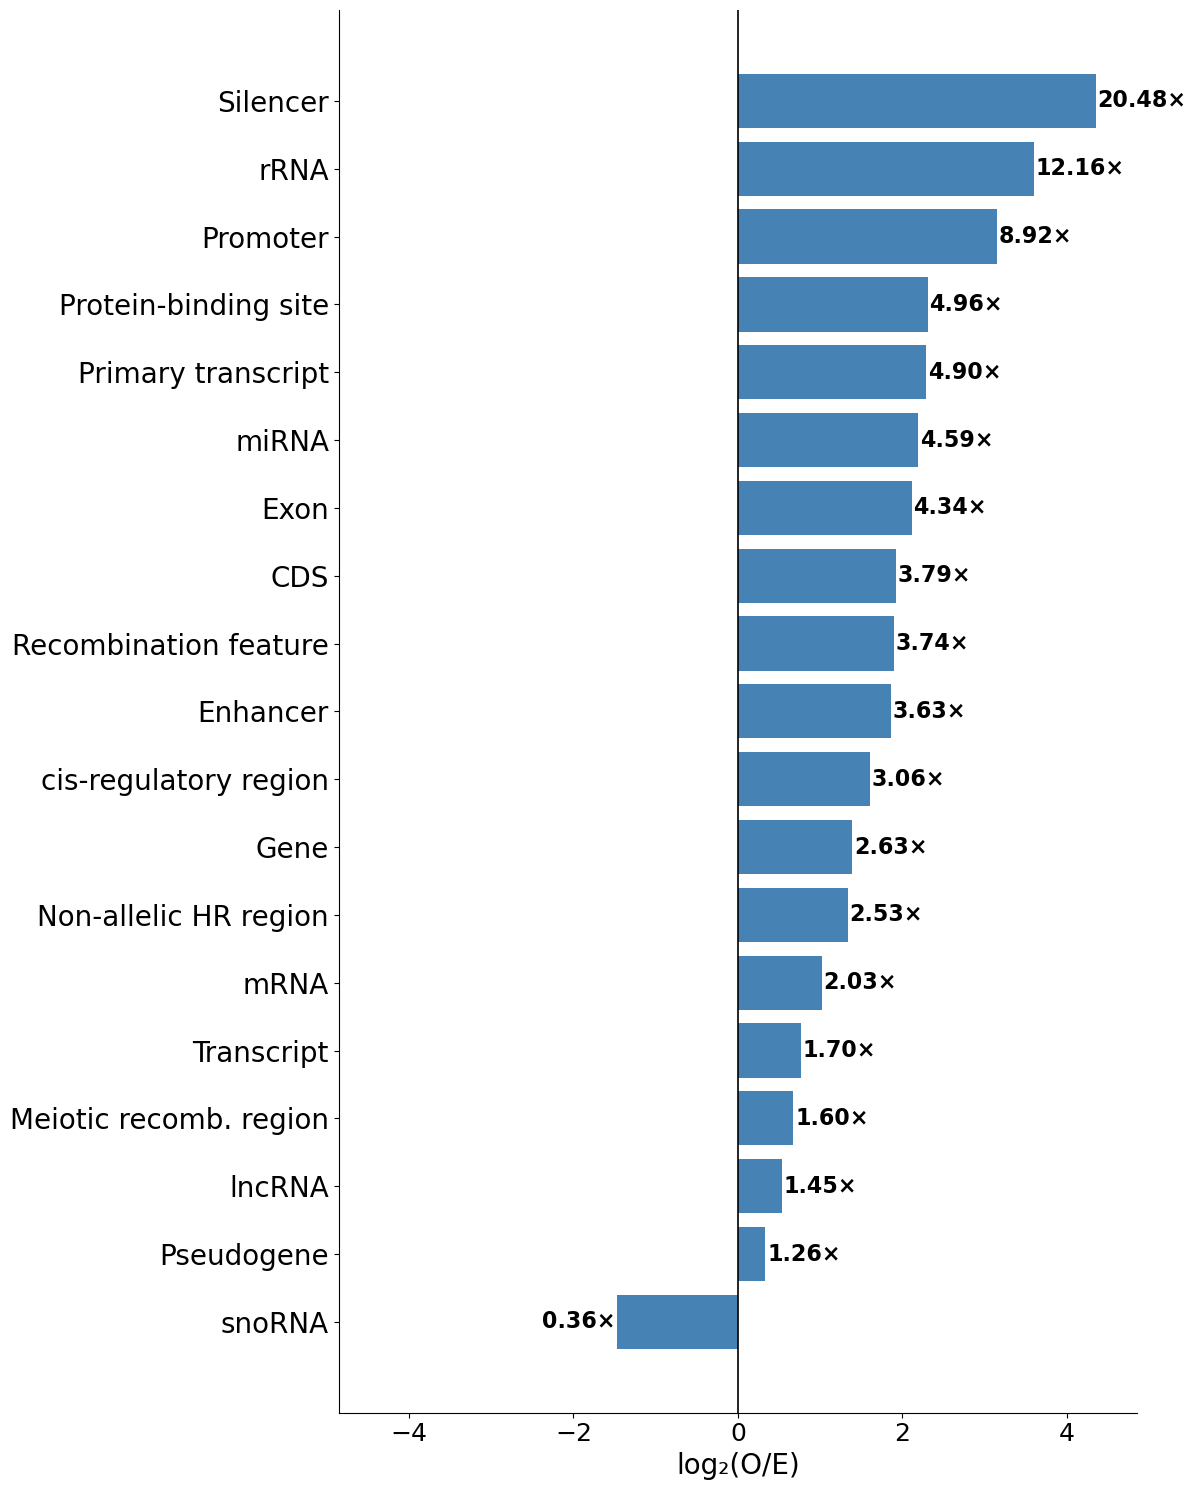

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")
row = per_assembly_metrics(parquet_file)
FEATURE_LABELS = {
    "CDS": "CDS",
    "exon": "Exon",
    "gene": "Gene",
    "lnc_RNA": "lncRNA",
    "mRNA": "mRNA",
    "meiotic_recombination_region": "Meiotic recomb. region",
    "miRNA": "miRNA",
    "non_allelic_homologous_recombination_region": "Non-allelic HR region",
    "primary_transcript": "Primary transcript",
    "promoter": "Promoter",
    "protein_binding_site": "Protein-binding site",
    "pseudogene": "Pseudogene",
    "recombination_feature": "Recombination feature",
    "rRNA": "rRNA",
    "silencer": "Silencer",
    "snoRNA": "snoRNA",
    "transcript": "Transcript",
    "transcriptional_cis_regulatory_region": "cis-regulatory region",
    "enhancer": "Enhancer"
}

# -------------------------
# Load enrichment file
# -------------------------
df = pd.read_csv("CHM13_feature_enrichment.tsv", sep="\t")

ratio_cols = [c for c in df.columns if c.endswith("_ratio_enrichment")]
vals = df.iloc[0][ratio_cols].to_dict()

features = [c.replace("_ratio_enrichment", "") for c in ratio_cols]
ratios   = np.array([vals[c] for c in ratio_cols], dtype=float)

# -------------------------
# Convert ratio → log2 ratio for centered plotting
# -------------------------
log2_ratios = np.log2(ratios)

# Sort by log2 values
order = np.argsort(log2_ratios)

features_sorted = [features[i] for i in order]        # FIX 1
labels_sorted   = [FEATURE_LABELS[f] for f in features_sorted]   # FIX 2

log2_sorted     = log2_ratios[order]
ratios_sorted   = ratios[order]

# -------------------------
# Plot
# -------------------------
fig, ax = plt.subplots(figsize=(12, 15))

y_pos = np.arange(len(labels_sorted))

ax.barh(
    y_pos,
    log2_sorted,
    color="steelblue",
    height=0.8
)

# Central neutral line (log2 = 0)
ax.axvline(0, color="black", linewidth=1.2)

# Y-axis labels
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_sorted, fontsize=20)   # FIX 3

ax.set_xlabel("log₂(O/E)", fontsize=20)
ax.tick_params(axis='x', labelsize=18)

# Symmetric x-limits
max_abs = np.max(np.abs(log2_sorted))
ax.set_xlim(-max_abs - 0.5, max_abs + 0.5)

# Remove unnecessary spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# -------------------------
# Add annotations (raw fold-change, e.g. '2.4×')
# -------------------------
for i, (log2_val, raw_ratio) in enumerate(zip(log2_sorted, ratios_sorted)):

    x_pos = log2_val + (0.02 if log2_val >= 0 else -0.02)
    
    ax.text(
        x_pos,
        i,
        f"{raw_ratio:.2f}×",
        va='center',
        ha='left' if log2_val >= 0 else 'right',
        fontsize=16,
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig("chm13_ft_enr.png", dpi=600, bbox_inches="tight")
plt.show()

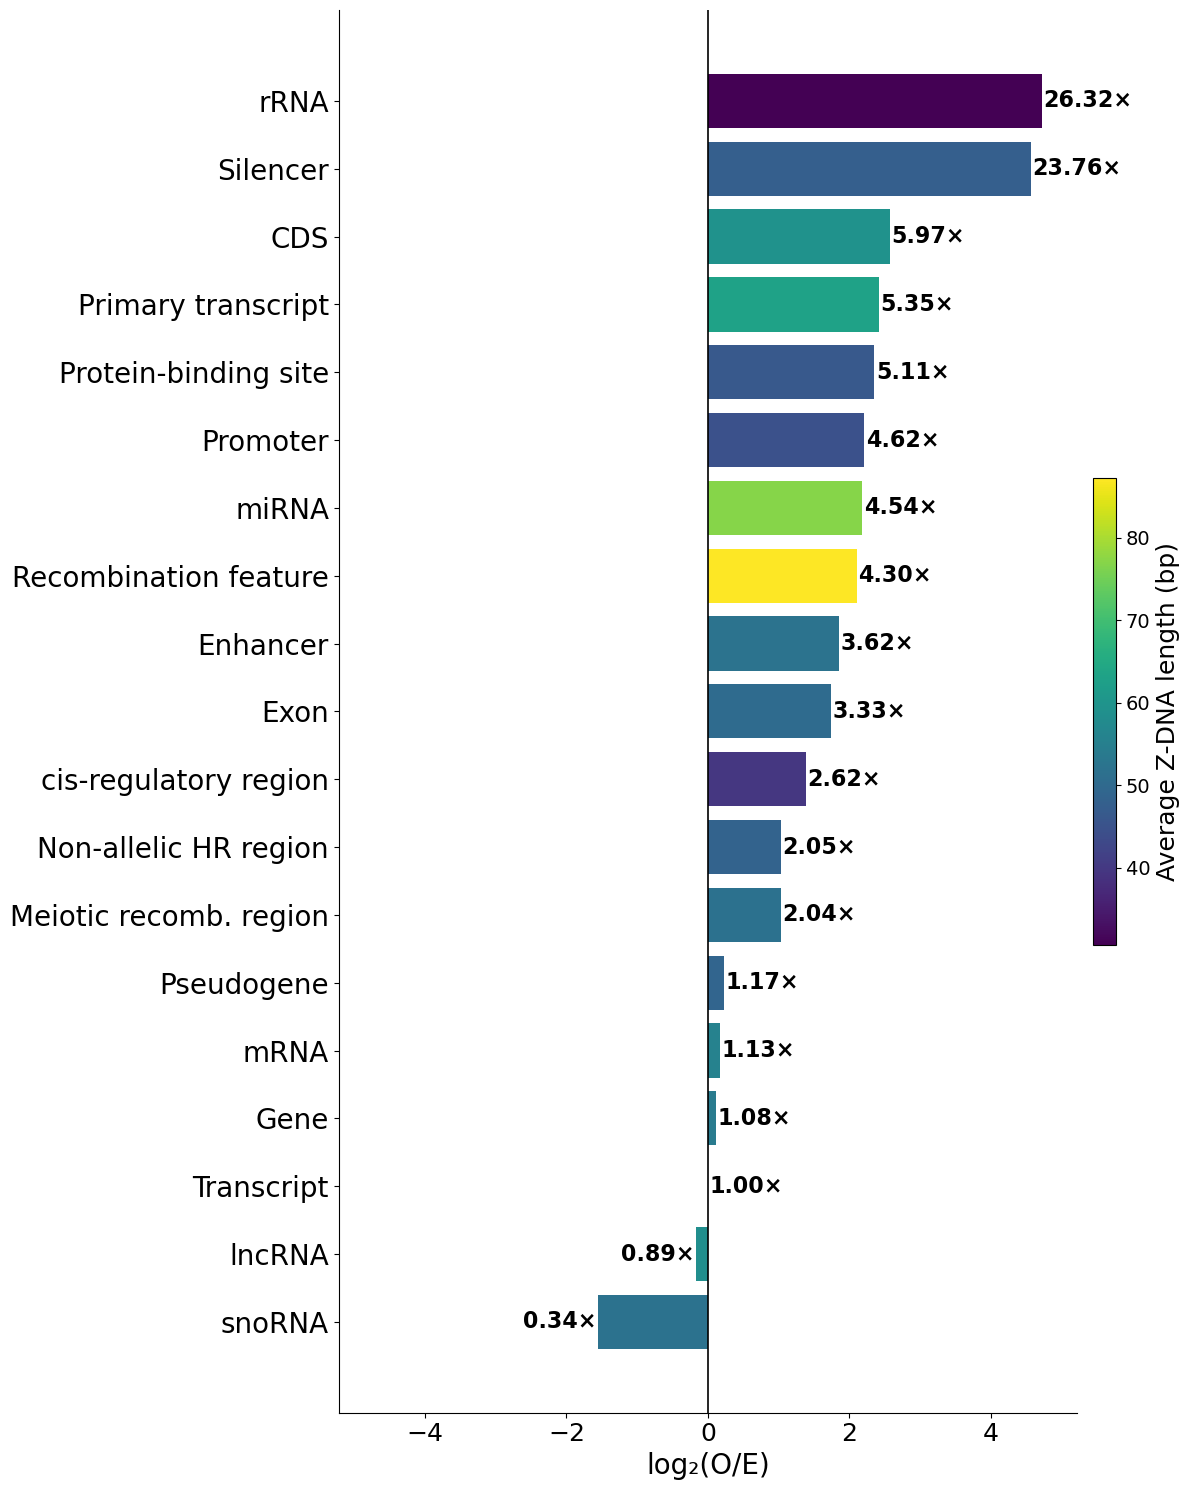

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
import matplotlib.cm as cm

# ----------------------------------------
# Load enrichment file (WITH the new *_avg columns)
# ----------------------------------------
df = pd.read_csv("CHM13_feature_enrichment_with_avgs.tsv", sep="\t")

FEATURE_LABELS = {
    "CDS": "CDS",
    "exon": "Exon",
    "gene": "Gene",
    "lnc_RNA": "lncRNA",
    "mRNA": "mRNA",
    "meiotic_recombination_region": "Meiotic recomb. region",
    "miRNA": "miRNA",
    "non_allelic_homologous_recombination_region": "Non-allelic HR region",
    "primary_transcript": "Primary transcript",
    "promoter": "Promoter",
    "protein_binding_site": "Protein-binding site",
    "pseudogene": "Pseudogene",
    "recombination_feature": "Recombination feature",
    "rRNA": "rRNA",
    "silencer": "Silencer",
    "snoRNA": "snoRNA",
    "transcript": "Transcript",
    "transcriptional_cis_regulatory_region": "cis-regulatory region",
    "enhancer": "Enhancer"
}

# ----------------------------------------
# Extract ratio columns and matching features
# ----------------------------------------
ratio_cols = [c for c in df.columns if c.endswith("_ratio_enrichment")]
vals = df.iloc[0][ratio_cols].to_dict()

features = [c.replace("_ratio_enrichment", "") for c in ratio_cols]
ratios   = np.array([vals[c] for c in ratio_cols], dtype=float)

# ----------------------------------------
# NEW: Extract average Z-length columns
# ----------------------------------------
avg_len_cols = [f"{f}_avg_zdna_length" for f in features]
avg_lengths  = df.iloc[0][avg_len_cols].to_numpy(dtype=float)

# ----------------------------------------
# log2-transform ratios and sort
# ----------------------------------------
log2_ratios = np.log2(ratios)

order = np.argsort(log2_ratios)

features_sorted  = [features[i] for i in order]
labels_sorted    = [FEATURE_LABELS[f] for f in features_sorted]
log2_sorted      = log2_ratios[order]
ratios_sorted    = ratios[order]
avg_len_sorted   = avg_lengths[order]

# ----------------------------------------
# Build color normalization scale
# ----------------------------------------
cmap = cm.viridis
norm = Normalize(vmin=np.nanmin(avg_len_sorted), vmax=np.nanmax(avg_len_sorted))

colors = cmap(norm(avg_len_sorted))

# ----------------------------------------
# Plot
# ----------------------------------------
fig, ax = plt.subplots(figsize=(12, 15))

y_pos = np.arange(len(labels_sorted))

bars = ax.barh(
    y_pos,
    log2_sorted,
    color=colors,     # <-- color by avg Z-length
    height=0.8
)

# Zero line
ax.axvline(0, color="black", linewidth=1.2)

# Labels
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_sorted, fontsize=20)

ax.set_xlabel("log₂(O/E)", fontsize=20)
ax.tick_params(axis='x', labelsize=18)

# Symmetric x limits
max_abs = np.max(np.abs(log2_sorted))
ax.set_xlim(-max_abs - 0.5, max_abs + 0.5)

# Clean look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ----------------------------------------
# Annotate O/E fold-change next to bars
# ----------------------------------------
for i, (log2_val, raw_ratio) in enumerate(zip(log2_sorted, ratios_sorted)):
    x_pos = log2_val + (0.02 if log2_val >= 0 else -0.02)
    ax.text(
        x_pos,
        i,
        f"{raw_ratio:.2f}×",
        va='center',
        ha='left' if log2_val >= 0 else 'right',
        fontsize=16,
        fontweight='bold'
    )

# ----------------------------------------
# Add colorbar for avg zdna length
# ----------------------------------------
cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    fraction=0.03,   # thinner colorbar
    pad=0.02         # spacing from plot
)

cbar.set_label("Average Z-DNA length (bp)", fontsize=18)
cbar.ax.tick_params(labelsize=14)


plt.tight_layout()
plt.savefig("chm13_ft_enr_color_by_avg_zdna_length.png", dpi=600, bbox_inches="tight")
plt.show()


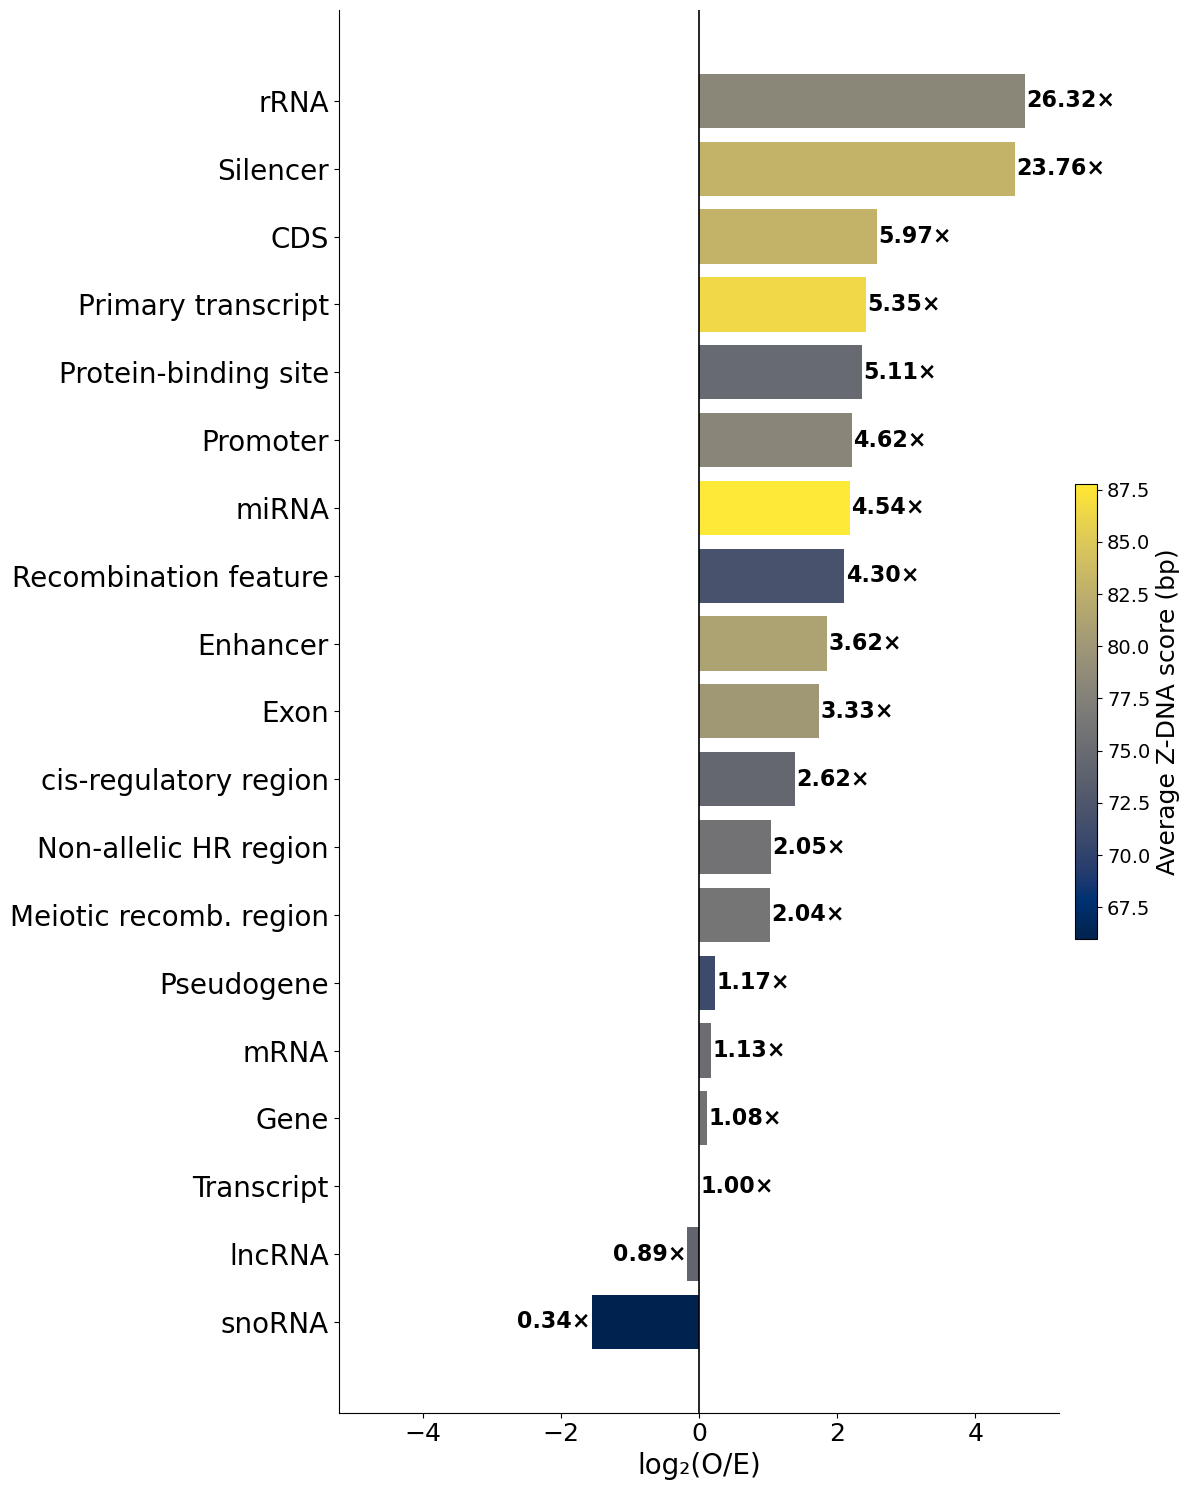

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
import matplotlib.cm as cm

# ----------------------------------------
# Load enrichment file (WITH the new *_avg columns)
# ----------------------------------------
df = pd.read_csv("CHM13_feature_enrichment_with_avgs.tsv", sep="\t")

FEATURE_LABELS = {
    "CDS": "CDS",
    "exon": "Exon",
    "gene": "Gene",
    "lnc_RNA": "lncRNA",
    "mRNA": "mRNA",
    "meiotic_recombination_region": "Meiotic recomb. region",
    "miRNA": "miRNA",
    "non_allelic_homologous_recombination_region": "Non-allelic HR region",
    "primary_transcript": "Primary transcript",
    "promoter": "Promoter",
    "protein_binding_site": "Protein-binding site",
    "pseudogene": "Pseudogene",
    "recombination_feature": "Recombination feature",
    "rRNA": "rRNA",
    "silencer": "Silencer",
    "snoRNA": "snoRNA",
    "transcript": "Transcript",
    "transcriptional_cis_regulatory_region": "cis-regulatory region",
    "enhancer": "Enhancer"
}

# ----------------------------------------
# Extract ratio columns and matching features
# ----------------------------------------
ratio_cols = [c for c in df.columns if c.endswith("_ratio_enrichment")]
vals = df.iloc[0][ratio_cols].to_dict()

features = [c.replace("_ratio_enrichment", "") for c in ratio_cols]
ratios   = np.array([vals[c] for c in ratio_cols], dtype=float)

# ----------------------------------------
# NEW: Extract average Z-length columns
# ----------------------------------------
avg_len_cols = [f"{f}_avg_zdna_score" for f in features]
avg_lengths  = df.iloc[0][avg_len_cols].to_numpy(dtype=float)

# ----------------------------------------
# log2-transform ratios and sort
# ----------------------------------------
log2_ratios = np.log2(ratios)

order = np.argsort(log2_ratios)

features_sorted  = [features[i] for i in order]
labels_sorted    = [FEATURE_LABELS[f] for f in features_sorted]
log2_sorted      = log2_ratios[order]
ratios_sorted    = ratios[order]
avg_len_sorted   = avg_lengths[order]

# ----------------------------------------
# Build color normalization scale
# ----------------------------------------
cmap = cm.cividis
norm = Normalize(vmin=np.nanmin(avg_len_sorted), vmax=np.nanmax(avg_len_sorted))

colors = cmap(norm(avg_len_sorted))

# ----------------------------------------
# Plot
# ----------------------------------------
fig, ax = plt.subplots(figsize=(12, 15))

y_pos = np.arange(len(labels_sorted))

bars = ax.barh(
    y_pos,
    log2_sorted,
    color=colors,     # <-- color by avg Z-length
    height=0.8
)

# Zero line
ax.axvline(0, color="black", linewidth=1.2)

# Labels
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_sorted, fontsize=20)

ax.set_xlabel("log₂(O/E)", fontsize=20)
ax.tick_params(axis='x', labelsize=18)

# Symmetric x limits
max_abs = np.max(np.abs(log2_sorted))
ax.set_xlim(-max_abs - 0.5, max_abs + 0.5)

# Clean look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ----------------------------------------
# Annotate O/E fold-change next to bars
# ----------------------------------------
for i, (log2_val, raw_ratio) in enumerate(zip(log2_sorted, ratios_sorted)):
    x_pos = log2_val + (0.02 if log2_val >= 0 else -0.02)
    ax.text(
        x_pos,
        i,
        f"{raw_ratio:.2f}×",
        va='center',
        ha='left' if log2_val >= 0 else 'right',
        fontsize=16,
        fontweight='bold'
    )

# ----------------------------------------
# Add colorbar for avg zdna length
# ----------------------------------------
cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    fraction=0.03,   # thinner colorbar
    pad=0.02         # spacing from plot
)

cbar.set_label("Average Z-DNA score (bp)", fontsize=18)
cbar.ax.tick_params(labelsize=14)


plt.tight_layout()
plt.savefig("chm13_ft_enr_color_by_avg_zdna_score.png", dpi=600, bbox_inches="tight")
plt.show()


In [36]:
import pandas as pd

censat_file = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/censat_v2.1_4.tsv"
telomere_file = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/chm13v2.0_telomere.tsv"

# --------------------------
# Load censat
# --------------------------
censat = pd.read_csv(censat_file, sep="\t", dtype=str)

# Simplify: take substring before the first "_"
censat["feature"] = censat["annotation"].str.split("_").str[0]

# Standardize column names
censat = censat.rename(columns={
    "start_bp": "start",
    "end_bp": "end"
})

censat = censat[["chromosome", "start", "end", "feature"]]

# --------------------------
# Load telomeres
# --------------------------
tel = pd.read_csv(telomere_file, sep="\t", dtype=str)

tel = tel.rename(columns={
    "tel_start": "start",
    "tel_end": "end"
})

# Assign feature name
tel["feature"] = "telomere"

tel = tel[["chromosome", "start", "end", "feature"]]

# --------------------------
# Combine
# --------------------------
combined = pd.concat([censat, tel], ignore_index=True)

# Write output
combined.to_csv("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/chm13_censat_tel.tsv", sep="\t", index=False)



Wrote chm13_annotations_combined.tsv


In [37]:
#!/usr/bin/env python3
import os
import pandas as pd
import numpy as np
import pyranges as pr


###############################################################################
# LOAD FEATURE FILE (no strand)
###############################################################################

def read_feature_tsv(path: str) -> pr.PyRanges:
    """
    Read custom feature file with columns:
        chromosome, start, end, feature
    and convert to PyRanges with columns:
        Chromosome, Start, End, Feature, feature_ID
    """
    df = pd.read_csv(path, sep="\t", dtype=str)

    df["Start"] = pd.to_numeric(df["start"], errors="coerce")
    df["End"]   = pd.to_numeric(df["end"],   errors="coerce")
    df["Feature"] = df["feature"].astype(str)

    # feature_ID = feature + start + end (unique enough)
    df["feature_ID"] = (
        df["Feature"] + ":" + df["Start"].astype(str) + "-" + df["End"].astype(str)
    )

    df = df[["chromosome", "Start", "End", "Feature", "feature_ID"]]
    df = df.dropna(subset=["chromosome", "Start", "End"])
    df = df.drop_duplicates()

    # Convert to PyRanges
    df = df.rename(columns={"chromosome": "Chromosome"})
    return pr.PyRanges(df)


###############################################################################
# READ Z-DNA CSV
###############################################################################

def read_zdna_csv(path: str) -> pd.DataFrame:
    """
    Extract Z-DNA intervals from the ZSeeker CSV:
        Chromosome, Start, End, Score, Sequence

    Removes NA-sentinel rows.
    """
    raw = pd.read_csv(path)

    # Identify columns (case-insensitive)
    lc = {c.lower(): c for c in raw.columns}
    def pick(*opts):
        for o in opts:
            if o in lc:
                return lc[o]
        return None

    c_chr = pick("chromosome", "chr")
    c_sta = pick("start", "begin")
    c_end = pick("end", "stop")
    c_sc  = pick("zdna score", "z-dna score", "score", "zscore")
    c_seq = pick("sequence", "seq")

    z = pd.DataFrame({
        "Chromosome": raw[c_chr] if c_chr else pd.Series(dtype=str),
        "Start":      pd.to_numeric(raw[c_sta], errors="coerce"),
        "End":        pd.to_numeric(raw[c_end], errors="coerce"),
        "Score":      pd.to_numeric(raw[c_sc],  errors="coerce"),
        "Sequence":   raw[c_seq] if c_seq else pd.Series(dtype=str),
    })

    # Drop sentinel NA rows where Start/End missing
    z = z.dropna(subset=["Start", "End"]).copy()

    return z


###############################################################################
# CONVERT Z TO PYRANGES
###############################################################################

def z_to_pr(zdf: pd.DataFrame) -> pr.PyRanges:
    if zdf.empty:
        return pr.PyRanges(pd.DataFrame(columns=["Chromosome", "Start", "End", "Score", "Sequence"]))

    df = pd.DataFrame({
        "Chromosome": zdf["Chromosome"],
        "Start": zdf["Start"].astype(int),
        "End":   zdf["End"].astype(int),
        "Score": zdf["Score"],
        "Sequence": zdf["Sequence"]
    })

    return pr.PyRanges(df)


###############################################################################
# OVERLAP COMPUTATION
###############################################################################

def compute_overlaps(feat: pr.PyRanges, z: pr.PyRanges) -> pd.DataFrame:
    if len(feat) == 0 or len(z) == 0:
        return pd.DataFrame()

    ov = feat.join(z, strandedness=False)
    if ov.df.empty:
        return pd.DataFrame()

    d = ov.df

    return pd.DataFrame({
        "chromosome":    d["Chromosome"],
        "feature_type":  d["Feature"],
        "feature_start": d["Start"],
        "feature_end":   d["End"],
        "feature_ID":    d["feature_ID"],
        "zdna_start":    d["Start_b"],
        "zdna_end":      d["End_b"],
        "zdna_score":    d["Score"],
        "zdna_sequence": d["Sequence"],
    })


###############################################################################
# FEATURES WITHOUT Z
###############################################################################

def feature_only(feat_df: pd.DataFrame, ov_keys: pd.DataFrame) -> pd.DataFrame:

    if feat_df.empty:
        return pd.DataFrame()

    if ov_keys.empty:
        missing = feat_df.copy()
    else:
        merged = feat_df.merge(
            ov_keys.drop_duplicates(),
            how="left",
            on=["Chromosome", "Feature", "Start", "End", "feature_ID"],
            indicator=True,
        )
        missing = merged[merged["_merge"] == "left_only"].drop(columns=["_merge"])

    if missing.empty:
        return pd.DataFrame()

    return pd.DataFrame({
        "chromosome":    missing["Chromosome"],
        "feature_type":  missing["Feature"],
        "feature_start": missing["Start"],
        "feature_end":   missing["End"],
        "feature_ID":    missing["feature_ID"],
        "zdna_start":    np.nan,
        "zdna_end":      np.nan,
        "zdna_score":    np.nan,
        "zdna_sequence": np.nan,
    })


###############################################################################
# Z WITHOUT FEATURES (INTERGENIC)
###############################################################################

def z_only(zdf: pd.DataFrame, ov_keys: pd.DataFrame) -> pd.DataFrame:
    if zdf.empty:
        return pd.DataFrame()

    if ov_keys.empty:
        unmatched = zdf.copy()
        unmatched["_merge"] = "left_only"
    else:
        unmatched = zdf.merge(
            ov_keys.drop_duplicates(),
            how="left",
            left_on=["Chromosome", "Start", "End"],
            right_on=["Chromosome", "Start_b", "End_b"],
            indicator=True,
        )

    z = unmatched[unmatched["_merge"] == "left_only"]

    if z.empty:
        return pd.DataFrame()

    return pd.DataFrame({
        "chromosome":    z["Chromosome"],
        "feature_type":  np.nan,
        "feature_start": np.nan,
        "feature_end":   np.nan,
        "feature_ID":    np.nan,
        "zdna_start":    z["Start"].astype(int),
        "zdna_end":      z["End"].astype(int),
        "zdna_score":    z["Score"],
        "zdna_sequence": z["Sequence"],
    })


###############################################################################
# FINAL FORMAT
###############################################################################

def finalize(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df["feature_length"] = (df["feature_end"] - df["feature_start"] + 1).where(df["feature_end"].notna())
    df["zdna_length"]    = (df["zdna_end"]   - df["zdna_start"]   + 1).where(df["zdna_end"].notna())

    # Desired column order
    df = df[
        [
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_length",
            "feature_end",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_length",
            "zdna_score",
            "zdna_sequence",
        ]
    ]

    return df


###############################################################################
# MAIN PIPELINE
###############################################################################

def run_annotation():
    feat_path = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/chm13_censat_tel.tsv"
    z_path = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"
    out_path = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13_censat_tel_zdna_ann.parquet"

    print("[INFO] Loading feature regions...")
    feat = read_feature_tsv(feat_path)
    feat_df = feat.df.copy()

    print("[INFO] Loading Z-DNA...")
    zdf = read_zdna_csv(z_path)
    z_pr = z_to_pr(zdf)

    print("[INFO] Computing overlaps...")
    ov = compute_overlaps(feat, z_pr)

    if ov.empty:
        ov_feature_keys = pd.DataFrame()
        ov_z_keys = pd.DataFrame()
    else:
        ov_feature_keys = pd.DataFrame({
            "Chromosome": ov["chromosome"],
            "Feature":    ov["feature_type"],
            "Start":      ov["feature_start"],
            "End":        ov["feature_end"],
            "feature_ID": ov["feature_ID"],
        })

        ov_z_keys = pd.DataFrame({
            "Chromosome": ov["chromosome"],
            "Start_b":    ov["zdna_start"],
            "End_b":      ov["zdna_end"],
        })

    print("[INFO] Feature-only rows...")
    fonly = feature_only(feat_df, ov_feature_keys)

    print("[INFO] Z-only rows...")
    zonly = z_only(zdf, ov_z_keys)

    print("[INFO] Merging...")
    pieces = [p for p in [ov, fonly, zonly] if not p.empty]
    combined = pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame()

    print("[INFO] Finalizing...")
    final = finalize(combined)

    print(f"[OK] Writing {len(final)} rows → {out_path}")
    final.to_parquet(out_path, index=False, engine="pyarrow")

if __name__ == "__main__":
    run_annotation()


[INFO] Loading feature regions...
[INFO] Loading Z-DNA...
[INFO] Computing overlaps...
[INFO] Feature-only rows...
[INFO] Z-only rows...
[INFO] Merging...
[INFO] Finalizing...
[OK] Writing 275370 rows → /work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13_censat_tel_zdna_ann.parquet


In [37]:
#!/usr/bin/env python3
import os
import numpy as np
import pandas as pd
import pyranges as pr


END_IS_INCLUSIVE = True


# ---------------------------------------------------------
# Helpers
# ---------------------------------------------------------
def _to_pr(df, chr_col, start_col, end_col, inclusive=True):
    """Convert df → PyRanges using half-open coordinates."""
    if df.empty:
        return pr.PyRanges(pd.DataFrame({"Chromosome":[], "Start":[], "End":[]}))
    tmp = df[[chr_col, start_col, end_col]].dropna().drop_duplicates().copy()
    tmp = tmp.rename(columns={chr_col:"Chromosome", start_col:"Start", end_col:"End"})
    if inclusive:
        tmp["End"] = tmp["End"].astype("int64") + 1
    tmp["Start"] = tmp["Start"].astype("int64")
    tmp["End"]   = tmp["End"].astype("int64")
    tmp = tmp[tmp["End"] > tmp["Start"]]
    return pr.PyRanges(tmp)


def _sum_union_bp(prx):
    if len(prx) == 0:
        return 0
    dfm = prx.merge().df
    return int((dfm["End"] - dfm["Start"]).sum())


# ---------------------------------------------------------
# Load genome size for expected Z background
# ---------------------------------------------------------
PAN_SN_FILE = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
chrom_info = pd.read_csv(PAN_SN_FILE, sep="\t", dtype=str)
chrom_info["gcf_seq_length"] = pd.to_numeric(chrom_info["gcf_seq_length"], errors="coerce")
CHM13_GENOME_SIZE = chrom_info["gcf_seq_length"].sum()


# ---------------------------------------------------------
# MAIN
# ---------------------------------------------------------
def per_assembly_metrics(parquet_file):
    asm = "CHM13v2.0"

    df = pd.read_parquet(parquet_file)

    # Auto-detect feature types in this censat/tel set
    FEATURES = sorted(df["feature_type"].dropna().unique())

    # -------------------------------------------------
    # Global Z union (for genome-wide background)
    # -------------------------------------------------
    zmask = df["zdna_start"].notna() & df["zdna_end"].notna()
    pr_z  = _to_pr(df.loc[zmask], "chromosome", "zdna_start", "zdna_end", END_IS_INCLUSIVE)
    z_union = pr_z.merge() if len(pr_z) else pr_z
    total_z_bp = _sum_union_bp(z_union)

    genome_size = int(CHM13_GENOME_SIZE)
    genome_z_fraction = total_z_bp / genome_size if genome_size > 0 else np.nan

    # Base output
    row = {
        "assembly": asm,
        "genome_size": genome_size,
        "total_z_bp": total_z_bp,
        "genome_z_fraction": genome_z_fraction,
    }

    # -------------------------------------------------
    # Load ALL Z predictions
    # -------------------------------------------------
    z_all = df.loc[zmask, [
        "chromosome", "zdna_start", "zdna_end",
        "zdna_score", "zdna_length", "zdna_sequence"
    ]].drop_duplicates()

    pr_z_all = _to_pr(z_all, "chromosome", "zdna_start", "zdna_end", END_IS_INCLUSIVE)

    # -------------------------------------------------
    # Loop through each detected feature type
    # -------------------------------------------------
    for feat in FEATURES:

        # All rows of this feature
        feats = df.loc[df["feature_type"] == feat,
                       ["chromosome","feature_start","feature_end","feature_ID"]]

        if feats.empty:
            row[f"{feat}_avg_zdna_score"] = np.nan
            row[f"{feat}_avg_zdna_length"] = np.nan
            row[f"{feat}_mean_cov"] = np.nan
            row[f"{feat}_S_enrichment"] = np.nan
            row[f"{feat}_ratio_enrichment"] = np.nan
            row[f"{feat}_feature_bp"] = 0
            row[f"{feat}_z_bp_in_feature"] = 0
            row[f"{feat}_frac_cov_by_z"] = np.nan
            continue

        # unique feature intervals
        feats_u = feats.drop_duplicates()
        pr_feat = _to_pr(feats_u, "chromosome", "feature_start", "feature_end", END_IS_INCLUSIVE)
        feat_union = pr_feat.merge()

        feature_bp = _sum_union_bp(feat_union)

        # ================================
        # AVERAGE Z SCORE / LENGTH LOGIC
        # (join, not intersect)
        # ================================
        join = pr_feat.join(pr_z_all)
        ov = join.df

        if ov.empty:
            avg_score = np.nan
            avg_len   = np.nan
        else:
            ov["z_start"] = ov["Start_b"]
            ov["z_end"]   = ov["End_b"] - 1

            tmp = ov.merge(
                z_all,
                left_on=["Chromosome", "z_start", "z_end"],
                right_on=["chromosome", "zdna_start", "zdna_end"],
                how="inner"
            ).drop_duplicates()

            avg_score = tmp["zdna_score"].mean()
            avg_len   = tmp["zdna_length"].mean()

        # ================================
        # COVERAGE / ENRICHMENT
        # ================================
        if feature_bp == 0:
            O = np.nan
            z_bp = 0
            frac_cov = np.nan
        else:
            inter = feat_union.intersect(z_union)
            z_bp = _sum_union_bp(inter)
            frac_cov = z_bp / feature_bp
            O = frac_cov

        E = genome_z_fraction
        if pd.isna(O) or pd.isna(E):
            S = np.nan
            ratio = np.nan
        else:
            S = (O - E) / (O + E) if (O + E) != 0 else 0
            ratio = O / E if E > 0 else np.nan

        # ================================
        # STORE
        # ================================
        row[f"{feat}_avg_zdna_score"] = avg_score
        row[f"{feat}_avg_zdna_length"] = avg_len
        row[f"{feat}_mean_cov"] = O
        row[f"{feat}_S_enrichment"] = S
        row[f"{feat}_ratio_enrichment"] = ratio
        row[f"{feat}_feature_bp"] = int(feature_bp)
        row[f"{feat}_z_bp_in_feature"] = int(z_bp)
        row[f"{feat}_frac_cov_by_z"] = frac_cov

    return row


# ---------------------------------------------------------
# RUN
# ---------------------------------------------------------
parquet_file = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13_censat_tel_zdna_ann.parquet"

os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")
row = per_assembly_metrics(parquet_file)
pd.DataFrame([row]).to_csv("CHM13_censat_tel_enrichment.tsv", sep="\t", index=False)

/tmp/ipykernel_1413402/525666351.py:103: RuntimeWarning: divide by zero encountered in log2
  log2_all = np.log2(all_ratios)


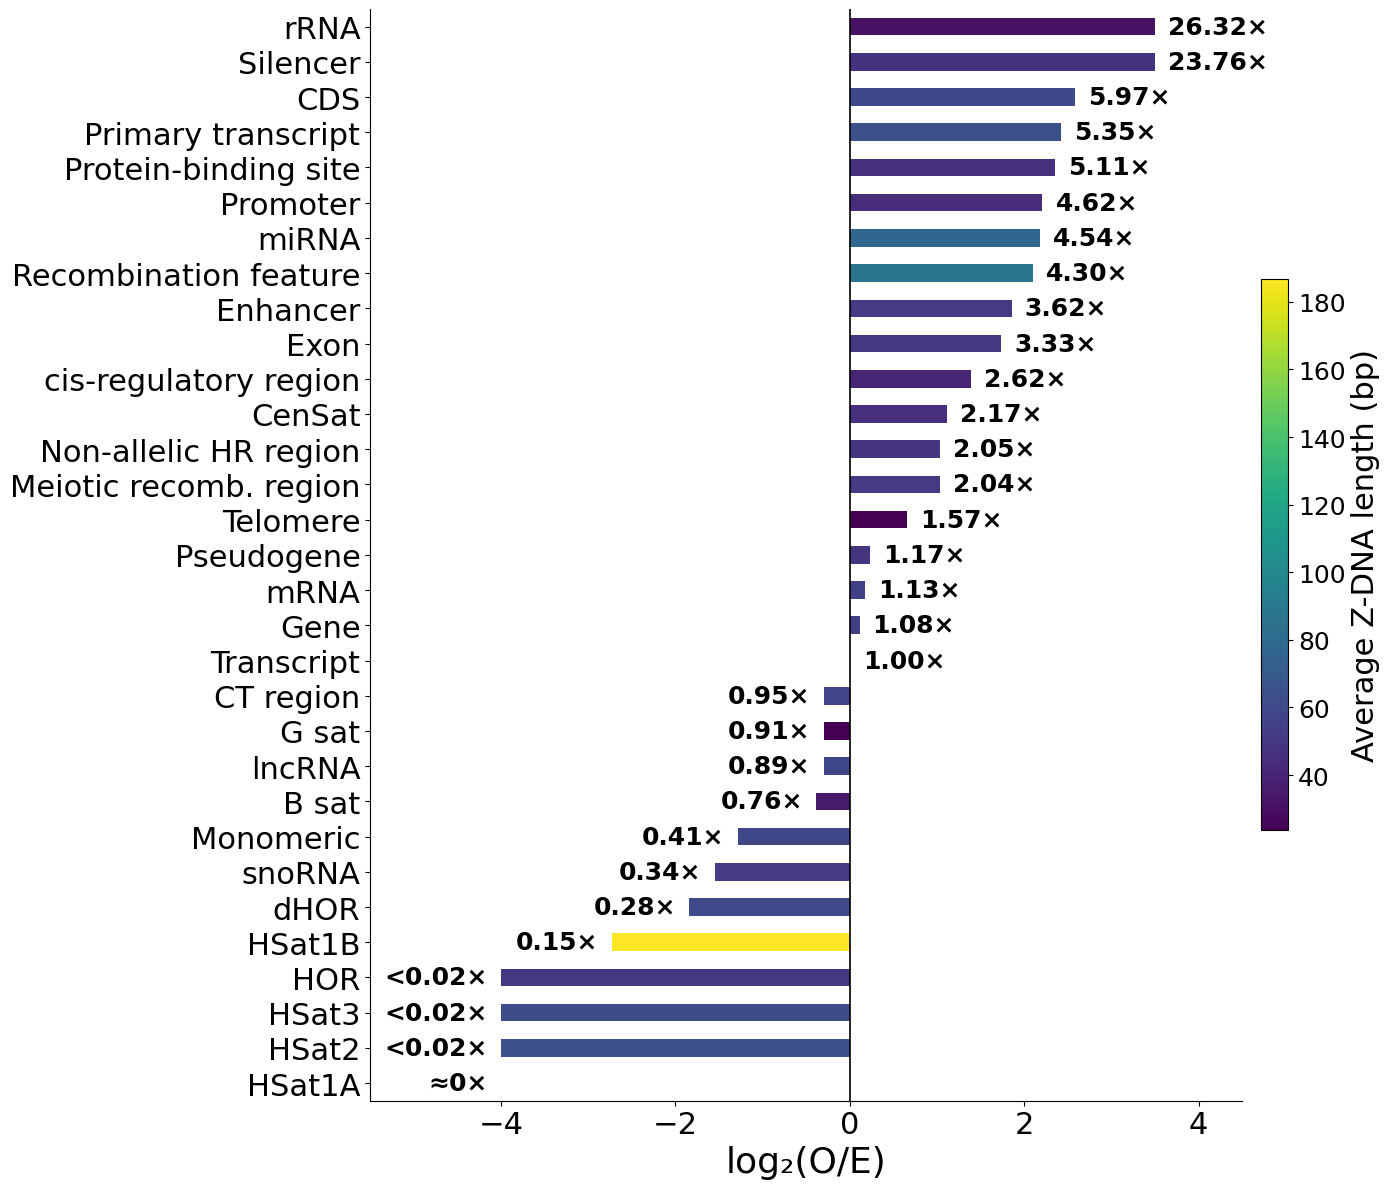

In [25]:
import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.cm as cm


# =============================================================
# LABELS (ONLY THESE FEATURES ARE INCLUDED)
# =============================================================
FEATURE_LABELS = {
    # file 1 features
    "CDS": "CDS",
    "exon": "Exon",
    "gene": "Gene",
    "lnc_RNA": "lncRNA",
    "mRNA": "mRNA",
    "meiotic_recombination_region": "Meiotic recomb. region",
    "miRNA": "miRNA",
    "non_allelic_homologous_recombination_region": "Non-allelic HR region",
    "primary_transcript": "Primary transcript",
    "promoter": "Promoter",
    "protein_binding_site": "Protein-binding site",
    "pseudogene": "Pseudogene",
    "recombination_feature": "Recombination feature",
    "rRNA": "rRNA",
    "silencer": "Silencer",
    "snoRNA": "snoRNA",
    "transcript": "Transcript",
    "transcriptional_cis_regulatory_region": "cis-regulatory region",
    "enhancer": "Enhancer",

    # file 2 features
    "bsat":   "B sat",
    "censat": "CenSat",
    "ct":     "CT region",
    "dhor":   "dHOR",
    "gsat":   "G sat",
    "hor":    "HOR",
    "hsat1A": "HSat1A",
    "hsat1B": "HSat1B",
    "hsat2":  "HSat2",
    "hsat3":  "HSat3",
    "mon":    "Monomeric",
    "telomere": "Telomere",
}

ALLOWED = set(FEATURE_LABELS.keys())

THRESH = 0.02
ZERO_EPS = 1e-6
CAP = 3.5
OFFSET = 0.15             # distance for label
FORCED_NEG = -4.0         # forced bar position for zeros & tiny negatives
MIN_NEG_BAR = -0.30       # minimum negative bar length for tiny negatives


# =============================================================
# Load both tables
# =============================================================
df1 = pd.read_csv("CHM13_feature_enrichment_with_avgs.tsv", sep="\t")
df2 = pd.read_csv("CHM13_censat_tel_enrichment.tsv", sep="\t")


# =============================================================
# Helper: extract only allowed features from a df
# =============================================================
def extract_allowed(df):

    ratio_cols = [c for c in df.columns if c.endswith("_ratio_enrichment")]
    feats = [c.replace("_ratio_enrichment", "") for c in ratio_cols]

    keep_mask = [f in ALLOWED for f in feats]

    feats = [f for f, k in zip(feats, keep_mask) if k]
    ratio_cols = [c for c, k in zip(ratio_cols, keep_mask) if k]

    ratios = df.iloc[0][ratio_cols].to_numpy(float)

    avg_cols = [f"{f}_avg_zdna_length" for f in feats]
    avg_lengths = df.iloc[0][avg_cols].to_numpy(float)

    return feats, ratios, avg_lengths


# =============================================================
# Extract & merge inputs
# =============================================================
feats1, ratios1, avg1 = extract_allowed(df1)
feats2, ratios2, avg2 = extract_allowed(df2)

all_features = feats1 + feats2
all_ratios   = np.concatenate([ratios1, ratios2])
all_avg      = np.concatenate([avg1, avg2])


# =============================================================
# Global sorting
# =============================================================
log2_all = np.log2(all_ratios)
order = np.argsort(log2_all)

features_sorted  = [all_features[i] for i in order]
ratios_sorted    = all_ratios[order]
avg_sorted       = all_avg[order]
log2_sorted      = log2_all[order]
labels_sorted    = [FEATURE_LABELS[f] for f in features_sorted]


# =============================================================
# Final capping with forced bar offsets
# =============================================================
log2_capped = np.zeros_like(log2_sorted)

for idx, (lz, r) in enumerate(zip(log2_sorted, ratios_sorted)):

    if r < ZERO_EPS:
        # true zero → force to a fixed left bar position
        log2_capped[idx] = FORCED_NEG

    elif r < THRESH:
        # small but non-zero → same forced left position
        log2_capped[idx] = FORCED_NEG

    else:
        lz_cap = np.clip(lz, -CAP, CAP)

        # ensure no negative bar sits near zero
        if -0.3 < lz_cap < 0:
            lz_cap = MIN_NEG_BAR

        log2_capped[idx] = lz_cap


# =============================================================
# Colors
# =============================================================
norm = Normalize(vmin=np.nanmin(avg_sorted), vmax=np.nanmax(avg_sorted))
colors = cm.viridis(norm(avg_sorted))


# =============================================================
# Plot
# =============================================================
fig, ax = plt.subplots(figsize=(14, 12))

y_pos = np.arange(len(labels_sorted))
ax.barh(y_pos, log2_capped, color=colors, height=0.5)

ax.axvline(0, color="black", linewidth=1.2)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels_sorted, fontsize=22)
ax.set_ylim(-0.5, len(labels_sorted) - 0.5)

ax.set_xlabel("log₂(O/E)", fontsize=26)
ax.tick_params(axis='x', labelsize=22)
ax.set_xlim(-CAP - 2, CAP + 1)   # stronger negative padding


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# =============================================================
# Annotation (≈0×, <0.02×, normal)
# =============================================================
for i, (lz_cap, r) in enumerate(zip(log2_capped, ratios_sorted)):

    if r < ZERO_EPS:
        label = "≈0×"
    elif r < THRESH:
        label = "<0.02×"
    else:
        label = f"{r:.2f}×"

    if lz_cap >= 0:
        x = lz_cap + OFFSET
        ha = "left"
    else:
        x = lz_cap - OFFSET
        ha = "right"

    ax.text(
        x, i, label,
        fontsize=18,
        va="center",
        ha=ha,
        fontweight="bold"
    )


# =============================================================
# Colorbar
# =============================================================
cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cm.viridis),
    ax=ax,
    fraction=0.03,
    pad=0.02
)
cbar.set_label("Average Z-DNA length (bp)", fontsize=22)
cbar.ax.tick_params(labelsize=18)

plt.tight_layout()
plt.savefig("chm13_ft_enr_color_by_avg_zdna_length.png", dpi=600, bbox_inches="tight")
plt.show()


In [40]:
import pandas as pd

infile  = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/chm13v2.0_rmsk_clean.tsv"
outfile = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/chm13v2.0_rmsk_features.tsv"

# Load full table
df = pd.read_csv(infile, sep="\t")

# Subset + rename
df2 = df[["chrom", "start", "end", "repClass"]].copy()
df2 = df2.rename(columns={
    "chrom": "chromosome",
    "repClass": "feature"
 
})

# Save
df2.to_csv(outfile, sep="\t", index=False)

print("Saved:", outfile)


Saved: /work/10906/geomeg/vista/pangenomes_zdna/ann_files/chm13v2.0_rmsk_features.tsv


In [41]:
#!/usr/bin/env python3
import os
import pandas as pd
import numpy as np
import pyranges as pr


###############################################################################
# LOAD FEATURE FILE (no strand)
###############################################################################

def read_feature_tsv(path: str) -> pr.PyRanges:
    """
    Read custom feature file with columns:
        chromosome, start, end, feature
    and convert to PyRanges with columns:
        Chromosome, Start, End, Feature, feature_ID
    """
    df = pd.read_csv(path, sep="\t", dtype=str)

    df["Start"] = pd.to_numeric(df["start"], errors="coerce")
    df["End"]   = pd.to_numeric(df["end"],   errors="coerce")
    df["Feature"] = df["feature"].astype(str)

    # feature_ID = feature + start + end (unique enough)
    df["feature_ID"] = (
        df["Feature"] + ":" + df["Start"].astype(str) + "-" + df["End"].astype(str)
    )

    df = df[["chromosome", "Start", "End", "Feature", "feature_ID"]]
    df = df.dropna(subset=["chromosome", "Start", "End"])
    df = df.drop_duplicates()

    # Convert to PyRanges
    df = df.rename(columns={"chromosome": "Chromosome"})
    return pr.PyRanges(df)


###############################################################################
# READ Z-DNA CSV
###############################################################################

def read_zdna_csv(path: str) -> pd.DataFrame:
    """
    Extract Z-DNA intervals from the ZSeeker CSV:
        Chromosome, Start, End, Score, Sequence

    Removes NA-sentinel rows.
    """
    raw = pd.read_csv(path)

    # Identify columns (case-insensitive)
    lc = {c.lower(): c for c in raw.columns}
    def pick(*opts):
        for o in opts:
            if o in lc:
                return lc[o]
        return None

    c_chr = pick("chromosome", "chr")
    c_sta = pick("start", "begin")
    c_end = pick("end", "stop")
    c_sc  = pick("zdna score", "z-dna score", "score", "zscore")
    c_seq = pick("sequence", "seq")

    z = pd.DataFrame({
        "Chromosome": raw[c_chr] if c_chr else pd.Series(dtype=str),
        "Start":      pd.to_numeric(raw[c_sta], errors="coerce"),
        "End":        pd.to_numeric(raw[c_end], errors="coerce"),
        "Score":      pd.to_numeric(raw[c_sc],  errors="coerce"),
        "Sequence":   raw[c_seq] if c_seq else pd.Series(dtype=str),
    })

    # Drop sentinel NA rows where Start/End missing
    z = z.dropna(subset=["Start", "End"]).copy()

    return z


###############################################################################
# CONVERT Z TO PYRANGES
###############################################################################

def z_to_pr(zdf: pd.DataFrame) -> pr.PyRanges:
    if zdf.empty:
        return pr.PyRanges(pd.DataFrame(columns=["Chromosome", "Start", "End", "Score", "Sequence"]))

    df = pd.DataFrame({
        "Chromosome": zdf["Chromosome"],
        "Start": zdf["Start"].astype(int),
        "End":   zdf["End"].astype(int),
        "Score": zdf["Score"],
        "Sequence": zdf["Sequence"]
    })

    return pr.PyRanges(df)


###############################################################################
# OVERLAP COMPUTATION
###############################################################################

def compute_overlaps(feat: pr.PyRanges, z: pr.PyRanges) -> pd.DataFrame:
    if len(feat) == 0 or len(z) == 0:
        return pd.DataFrame()

    ov = feat.join(z, strandedness=False)
    if ov.df.empty:
        return pd.DataFrame()

    d = ov.df

    return pd.DataFrame({
        "chromosome":    d["Chromosome"],
        "feature_type":  d["Feature"],
        "feature_start": d["Start"],
        "feature_end":   d["End"],
        "feature_ID":    d["feature_ID"],
        "zdna_start":    d["Start_b"],
        "zdna_end":      d["End_b"],
        "zdna_score":    d["Score"],
        "zdna_sequence": d["Sequence"],
    })


###############################################################################
# FEATURES WITHOUT Z
###############################################################################

def feature_only(feat_df: pd.DataFrame, ov_keys: pd.DataFrame) -> pd.DataFrame:

    if feat_df.empty:
        return pd.DataFrame()

    if ov_keys.empty:
        missing = feat_df.copy()
    else:
        merged = feat_df.merge(
            ov_keys.drop_duplicates(),
            how="left",
            on=["Chromosome", "Feature", "Start", "End", "feature_ID"],
            indicator=True,
        )
        missing = merged[merged["_merge"] == "left_only"].drop(columns=["_merge"])

    if missing.empty:
        return pd.DataFrame()

    return pd.DataFrame({
        "chromosome":    missing["Chromosome"],
        "feature_type":  missing["Feature"],
        "feature_start": missing["Start"],
        "feature_end":   missing["End"],
        "feature_ID":    missing["feature_ID"],
        "zdna_start":    np.nan,
        "zdna_end":      np.nan,
        "zdna_score":    np.nan,
        "zdna_sequence": np.nan,
    })


###############################################################################
# Z WITHOUT FEATURES (INTERGENIC)
###############################################################################

def z_only(zdf: pd.DataFrame, ov_keys: pd.DataFrame) -> pd.DataFrame:
    if zdf.empty:
        return pd.DataFrame()

    if ov_keys.empty:
        unmatched = zdf.copy()
        unmatched["_merge"] = "left_only"
    else:
        unmatched = zdf.merge(
            ov_keys.drop_duplicates(),
            how="left",
            left_on=["Chromosome", "Start", "End"],
            right_on=["Chromosome", "Start_b", "End_b"],
            indicator=True,
        )

    z = unmatched[unmatched["_merge"] == "left_only"]

    if z.empty:
        return pd.DataFrame()

    return pd.DataFrame({
        "chromosome":    z["Chromosome"],
        "feature_type":  np.nan,
        "feature_start": np.nan,
        "feature_end":   np.nan,
        "feature_ID":    np.nan,
        "zdna_start":    z["Start"].astype(int),
        "zdna_end":      z["End"].astype(int),
        "zdna_score":    z["Score"],
        "zdna_sequence": z["Sequence"],
    })


###############################################################################
# FINAL FORMAT
###############################################################################

def finalize(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df["feature_length"] = (df["feature_end"] - df["feature_start"] + 1).where(df["feature_end"].notna())
    df["zdna_length"]    = (df["zdna_end"]   - df["zdna_start"]   + 1).where(df["zdna_end"].notna())

    # Desired column order
    df = df[
        [
            "chromosome",
            "feature_type",
            "feature_start",
            "feature_length",
            "feature_end",
            "feature_ID",
            "zdna_start",
            "zdna_end",
            "zdna_length",
            "zdna_score",
            "zdna_sequence",
        ]
    ]

    return df


###############################################################################
# MAIN PIPELINE
###############################################################################

def run_annotation():
    feat_path = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/chm13v2.0_rmsk_features.tsv"
    z_path = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"
    out_path = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13_trans_el_zdna_ann.parquet"

    print("[INFO] Loading feature regions...")
    feat = read_feature_tsv(feat_path)
    feat_df = feat.df.copy()

    print("[INFO] Loading Z-DNA...")
    zdf = read_zdna_csv(z_path)
    z_pr = z_to_pr(zdf)

    print("[INFO] Computing overlaps...")
    ov = compute_overlaps(feat, z_pr)

    if ov.empty:
        ov_feature_keys = pd.DataFrame()
        ov_z_keys = pd.DataFrame()
    else:
        ov_feature_keys = pd.DataFrame({
            "Chromosome": ov["chromosome"],
            "Feature":    ov["feature_type"],
            "Start":      ov["feature_start"],
            "End":        ov["feature_end"],
            "feature_ID": ov["feature_ID"],
        })

        ov_z_keys = pd.DataFrame({
            "Chromosome": ov["chromosome"],
            "Start_b":    ov["zdna_start"],
            "End_b":      ov["zdna_end"],
        })

    print("[INFO] Feature-only rows...")
    fonly = feature_only(feat_df, ov_feature_keys)

    print("[INFO] Z-only rows...")
    zonly = z_only(zdf, ov_z_keys)

    print("[INFO] Merging...")
    pieces = [p for p in [ov, fonly, zonly] if not p.empty]
    combined = pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame()

    print("[INFO] Finalizing...")
    final = finalize(combined)

    print(f"[OK] Writing {len(final)} rows → {out_path}")
    final.to_parquet(out_path, index=False, engine="pyarrow")


if __name__ == "__main__":
    run_annotation()


[INFO] Loading feature regions...
[INFO] Loading Z-DNA...
[INFO] Computing overlaps...
[INFO] Feature-only rows...
[INFO] Z-only rows...
[INFO] Merging...
[INFO] Finalizing...
[OK] Writing 4823642 rows → /work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13_trans_el_zdna_ann.parquet


In [42]:
#!/usr/bin/env python3
import os
import numpy as np
import pandas as pd
import pyranges as pr


END_IS_INCLUSIVE = True


# ---------------------------------------------------------
# Helpers
# ---------------------------------------------------------
def _to_pr(df, chr_col, start_col, end_col, inclusive=True):
    """Convert df → PyRanges using half-open coordinates."""
    if df.empty:
        return pr.PyRanges(pd.DataFrame({"Chromosome":[], "Start":[], "End":[]}))
    tmp = df[[chr_col, start_col, end_col]].dropna().drop_duplicates().copy()
    tmp = tmp.rename(columns={chr_col:"Chromosome", start_col:"Start", end_col:"End"})
    if inclusive:
        tmp["End"] = tmp["End"].astype("int64") + 1
    tmp["Start"] = tmp["Start"].astype("int64")
    tmp["End"]   = tmp["End"].astype("int64")
    tmp = tmp[tmp["End"] > tmp["Start"]]
    return pr.PyRanges(tmp)


def _sum_union_bp(prx):
    if len(prx) == 0:
        return 0
    dfm = prx.merge().df
    return int((dfm["End"] - dfm["Start"]).sum())


# ---------------------------------------------------------
# Load genome size for expected Z background
# ---------------------------------------------------------
PAN_SN_FILE = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"
chrom_info = pd.read_csv(PAN_SN_FILE, sep="\t", dtype=str)
chrom_info["gcf_seq_length"] = pd.to_numeric(chrom_info["gcf_seq_length"], errors="coerce")
CHM13_GENOME_SIZE = chrom_info["gcf_seq_length"].sum()


# ---------------------------------------------------------
# MAIN
# ---------------------------------------------------------
def per_assembly_metrics(parquet_file):
    asm = "CHM13v2.0"

    df = pd.read_parquet(parquet_file)

    # Auto-detect feature types in this censat/tel set
    FEATURES = sorted(df["feature_type"].dropna().unique())

    # -------------------------------------------------
    # Global Z union (for genome-wide background)
    # -------------------------------------------------
    zmask = df["zdna_start"].notna() & df["zdna_end"].notna()
    pr_z  = _to_pr(df.loc[zmask], "chromosome", "zdna_start", "zdna_end", END_IS_INCLUSIVE)
    z_union = pr_z.merge() if len(pr_z) else pr_z
    total_z_bp = _sum_union_bp(z_union)

    genome_size = int(CHM13_GENOME_SIZE)
    genome_z_fraction = total_z_bp / genome_size if genome_size > 0 else np.nan

    # Base output
    row = {
        "assembly": asm,
        "genome_size": genome_size,
        "total_z_bp": total_z_bp,
        "genome_z_fraction": genome_z_fraction,
    }

    # -------------------------------------------------
    # Load ALL Z predictions
    # -------------------------------------------------
    z_all = df.loc[zmask, [
        "chromosome", "zdna_start", "zdna_end",
        "zdna_score", "zdna_length", "zdna_sequence"
    ]].drop_duplicates()

    pr_z_all = _to_pr(z_all, "chromosome", "zdna_start", "zdna_end", END_IS_INCLUSIVE)

    # -------------------------------------------------
    # Loop through each detected feature type
    # -------------------------------------------------
    for feat in FEATURES:

        # All rows of this feature
        feats = df.loc[df["feature_type"] == feat,
                       ["chromosome","feature_start","feature_end","feature_ID"]]

        if feats.empty:
            row[f"{feat}_avg_zdna_score"] = np.nan
            row[f"{feat}_avg_zdna_length"] = np.nan
            row[f"{feat}_mean_cov"] = np.nan
            row[f"{feat}_S_enrichment"] = np.nan
            row[f"{feat}_ratio_enrichment"] = np.nan
            row[f"{feat}_feature_bp"] = 0
            row[f"{feat}_z_bp_in_feature"] = 0
            row[f"{feat}_frac_cov_by_z"] = np.nan
            continue

        # unique feature intervals
        feats_u = feats.drop_duplicates()
        pr_feat = _to_pr(feats_u, "chromosome", "feature_start", "feature_end", END_IS_INCLUSIVE)
        feat_union = pr_feat.merge()

        feature_bp = _sum_union_bp(feat_union)

        # ================================
        # AVERAGE Z SCORE / LENGTH LOGIC
        # (join, not intersect)
        # ================================
        join = pr_feat.join(pr_z_all)
        ov = join.df

        if ov.empty:
            avg_score = np.nan
            avg_len   = np.nan
        else:
            ov["z_start"] = ov["Start_b"]
            ov["z_end"]   = ov["End_b"] - 1

            tmp = ov.merge(
                z_all,
                left_on=["Chromosome", "z_start", "z_end"],
                right_on=["chromosome", "zdna_start", "zdna_end"],
                how="inner"
            ).drop_duplicates()

            avg_score = tmp["zdna_score"].mean()
            avg_len   = tmp["zdna_length"].mean()

        # ================================
        # COVERAGE / ENRICHMENT
        # ================================
        if feature_bp == 0:
            O = np.nan
            z_bp = 0
            frac_cov = np.nan
        else:
            inter = feat_union.intersect(z_union)
            z_bp = _sum_union_bp(inter)
            frac_cov = z_bp / feature_bp
            O = frac_cov

        E = genome_z_fraction
        if pd.isna(O) or pd.isna(E):
            S = np.nan
            ratio = np.nan
        else:
            S = (O - E) / (O + E) if (O + E) != 0 else 0
            ratio = O / E if E > 0 else np.nan

        # ================================
        # STORE
        # ================================
        row[f"{feat}_avg_zdna_score"] = avg_score
        row[f"{feat}_avg_zdna_length"] = avg_len
        row[f"{feat}_mean_cov"] = O
        row[f"{feat}_S_enrichment"] = S
        row[f"{feat}_ratio_enrichment"] = ratio
        row[f"{feat}_feature_bp"] = int(feature_bp)
        row[f"{feat}_z_bp_in_feature"] = int(z_bp)
        row[f"{feat}_frac_cov_by_z"] = frac_cov

    return row


# ---------------------------------------------------------
# RUN
# ---------------------------------------------------------
parquet_file = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/CHM13_trans_el_zdna_ann.parquet"

os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")
row = per_assembly_metrics(parquet_file)
pd.DataFrame([row]).to_csv("CHM13_trans_el_enrichment.tsv", sep="\t", index=False)

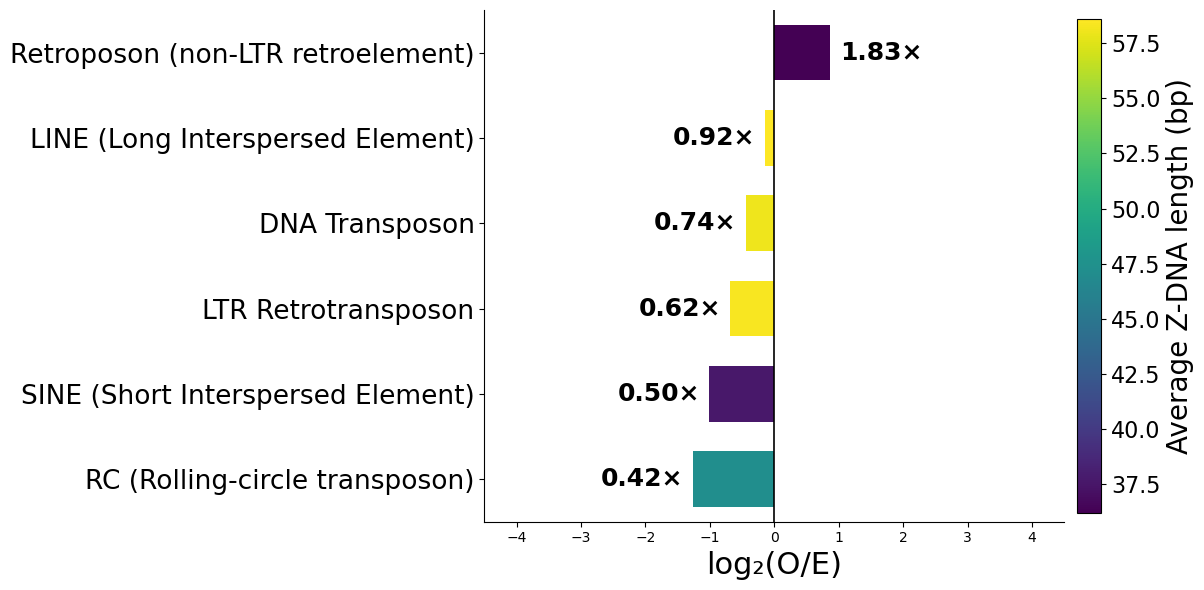

In [45]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.cm as cm

os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")

# ================================================================
# TE CLASSES WE KEEP
# ================================================================
FEATURE_LABELS = {
    "LINE":        "LINE (Long Interspersed Element)",
    "SINE":        "SINE (Short Interspersed Element)",
    "LTR":         "LTR Retrotransposon",
    "DNA":         "DNA Transposon",
    "RC":          "RC (Rolling-circle transposon)",
    "Retroposon":  "Retroposon (non-LTR retroelement)",
}

ALLOWED = set(FEATURE_LABELS.keys())

# plotting rules
THRESH = 0.02
CAP = 3.5
OFFSET = 0.15
ZERO_EPS = 1e-6
LABEL_PAD = 0.5     # distance from y-axis for left-side labels

# ================================================================
# Load TE enrichment file
# ================================================================
df = pd.read_csv(
    "/work/10906/geomeg/vista/pangenomes_zdna/CHM13_trans_el_enrichment.tsv",
    sep="\t"
)

# ================================================================
# Extract ONLY allowed features
# ================================================================
ratio_cols = [c for c in df.columns if c.endswith("_ratio_enrichment")]
feats = [c.replace("_ratio_enrichment", "") for c in ratio_cols]

keep_mask = [f in ALLOWED for f in feats]
feats = [f for f, k in zip(feats, keep_mask) if k]
ratio_cols = [c for c, k in zip(ratio_cols, keep_mask) if k]

ratios = df.iloc[0][ratio_cols].to_numpy(float)

# get avg Z-DNA length
avg_cols = [f"{f}_avg_zdna_length" for f in feats]
avg_lengths = df.iloc[0][avg_cols].to_numpy(float)

# ================================================================
# Sort globally
# ================================================================
log2_vals = np.log2(ratios)
order = np.argsort(log2_vals)

feats_sorted   = [feats[i] for i in order]
ratios_sorted  = ratios[order]
avg_sorted     = avg_lengths[order]
log2_sorted    = log2_vals[order]
labels_sorted  = [FEATURE_LABELS[f] for f in feats_sorted]

# ================================================================
# Apply capping, <0.02, ≈0 logic
# ================================================================
log2_capped = np.zeros_like(log2_sorted)

for i, (lz, r) in enumerate(zip(log2_sorted, ratios_sorted)):
    if r < ZERO_EPS:
        log2_capped[i] = -CAP
    elif r < THRESH:
        log2_capped[i] = -CAP
    else:
        if abs(lz) < 0.15:
            log2_capped[i] = -0.15
        else:
            log2_capped[i] = np.clip(lz, -CAP, CAP)

# ================================================================
# Colors from avg Z-DNA length
# ================================================================
norm = Normalize(vmin=np.nanmin(avg_sorted), vmax=np.nanmax(avg_sorted))
colors = cm.viridis(norm(avg_sorted))

# ================================================================
# PLOT
# ================================================================
fig, ax = plt.subplots(figsize=(12, 6))

y_pos = np.arange(len(labels_sorted))

ax.barh(y_pos, log2_capped, color=colors, height=0.65)

# zero line
ax.axvline(0, color="black", linewidth=1.2)

# yticks
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_sorted, fontsize=19)

# limits and style
ax.set_ylim(-0.5, len(labels_sorted) - 0.5)
ax.set_xlim(-CAP - 1, CAP + 1)
ax.set_xlabel("log₂(O/E)", fontsize=22)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ================================================================
# Annotate bars
# ================================================================
for i, (lz_cap, r) in enumerate(zip(log2_capped, ratios_sorted)):

    if r < ZERO_EPS:
        text = "≈0×"
    elif r < THRESH:
        text = "<0.02×"
    else:
        text = f"{r:.2f}×"

    if lz_cap >= 0:
        x = lz_cap + OFFSET
        ha = "left"
    else:
        x = max(lz_cap - OFFSET, -CAP - LABEL_PAD)
        ha = "right"

    ax.text(
        x, i, text,
        fontsize=18, va="center", ha=ha, fontweight="bold"
    )

# ================================================================
# Colorbar
# ================================================================
cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cm.viridis),
    ax=ax, fraction=0.04, pad=0.02
)
cbar.set_label("Average Z-DNA length (bp)", fontsize=20)
cbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig("CHM13_TE_class_enrichment.png", dpi=600)
plt.show()


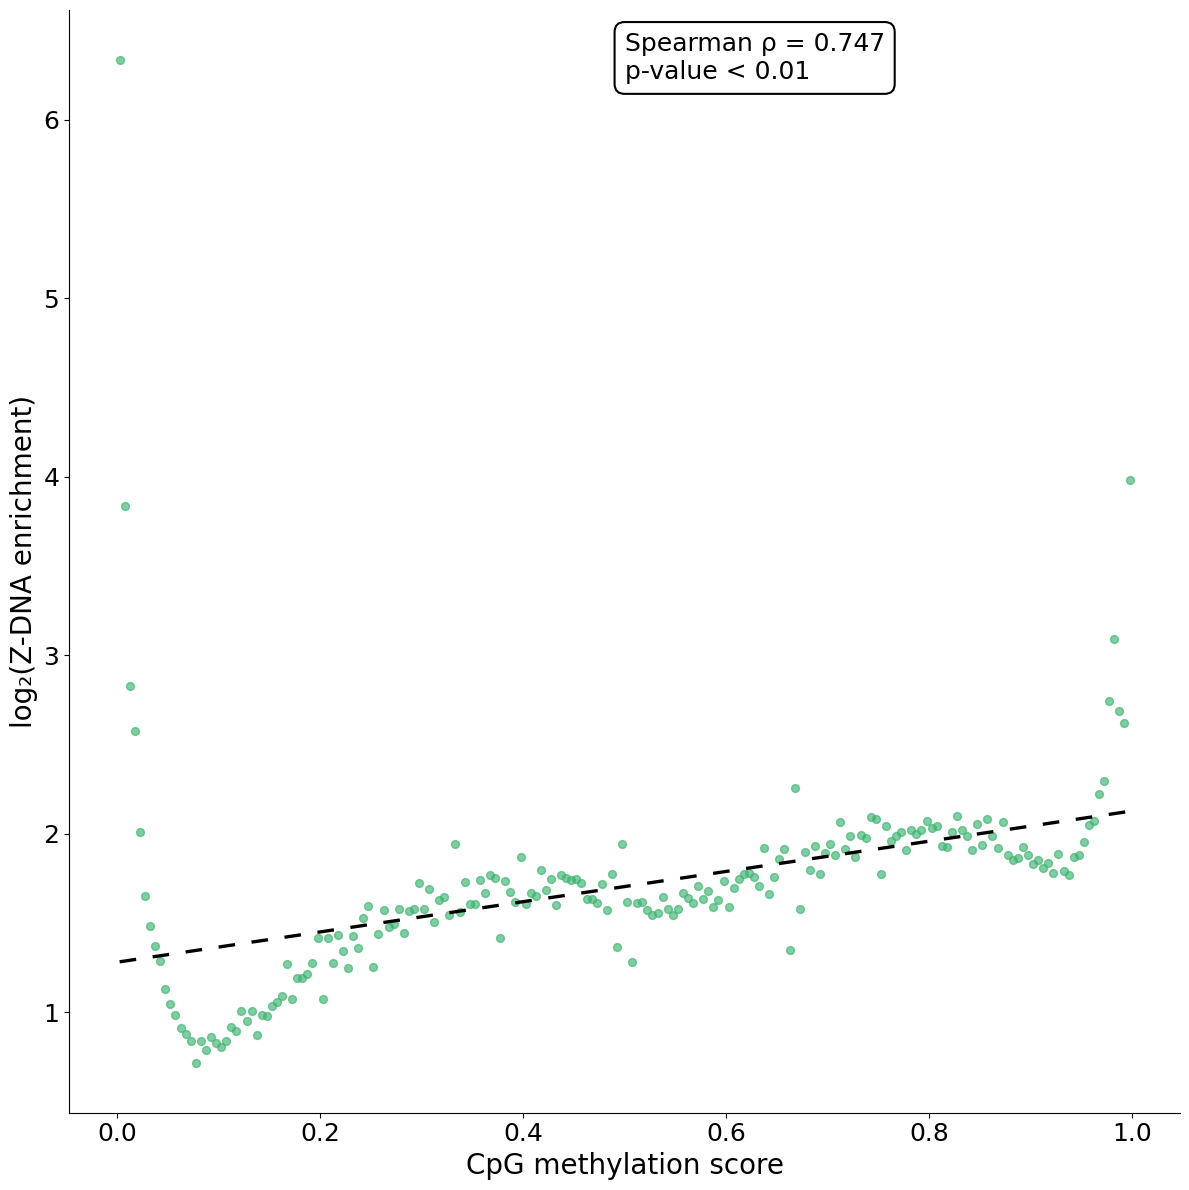

In [35]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.linear_model import LinearRegression

# # -------------------------------------------------------------
# # INPUT FILES
# # -------------------------------------------------------------
# cpg_all_bed = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/CpG_all.bedgraph"
# zdna_csv    = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"
# chrom_info  = "/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv"


# # -------------------------------------------------------------
# # LOAD GENOME LENGTH (sum of all chromosomes)
# # -------------------------------------------------------------
# pan = pd.read_csv(chrom_info, sep="\t", dtype=str)
# pan["gcf_seq_length"] = pd.to_numeric(pan["gcf_seq_length"])
# GENOME_SIZE = pan["gcf_seq_length"].sum()
# print(f"[INFO] Genome size: {GENOME_SIZE:,} bp")


# # -------------------------------------------------------------
# # LOAD Z-DNA intervals (genome-wide)
# # -------------------------------------------------------------
# zd = pd.read_csv(zdna_csv)
# zd["Start"] = zd["Start"].astype(int)
# zd["End"]   = zd["End"].astype(int)

# zd_intervals = zd[["Chromosome", "Start", "End"]].copy()

# # compute total Z-DNA bp
# ZDNA_BP = (zd_intervals["End"] - zd_intervals["Start"] + 1).sum()
# ZDNA_FRACTION = ZDNA_BP / GENOME_SIZE

# print(f"[INFO] Total Z-DNA bp: {ZDNA_BP:,}")
# print(f"[INFO] Genome-wide Z-DNA fraction: {ZDNA_FRACTION:.6f}")


# # -------------------------------------------------------------
# # LOAD ALL CpG methylation calls (genome-wide)
# # -------------------------------------------------------------
# cpg = pd.read_csv(
#     cpg_all_bed,
#     sep="\t",
#     header=None,
#     names=["chrom", "start", "end", "score"]
# )

# cpg["pos"] = cpg["start"].astype(int)
# print(f"[INFO] Total CpG positions: {len(cpg):,}")


# # -------------------------------------------------------------
# # BUILD PER-CHROMOSOME INTERVAL LISTS FOR FAST OVERLAP
# # -------------------------------------------------------------
# intervals_by_chr = {}

# for chrom in zd_intervals["Chromosome"].unique():
#     arr = zd_intervals[zd_intervals["Chromosome"] == chrom][["Start", "End"]].to_numpy()
#     arr = arr[np.argsort(arr[:,0])]
#     intervals_by_chr[chrom] = arr


# def check_overlap_vectorized(positions, intervals):
#     """
#     Given:
#       positions: array of ints
#       intervals: Nx2 array of sorted intervals [start,end]
#     Return boolean array: True if position ∈ any interval.
#     """
#     if len(intervals) == 0:
#         return np.zeros(len(positions), dtype=bool)

#     idx = np.searchsorted(intervals[:,0], positions, side="right") - 1
#     valid = idx >= 0
#     idx2 = idx[valid]
#     pos2 = positions[valid]
#     hits = pos2 <= intervals[idx2, 1]

#     out = np.zeros(len(positions), dtype=bool)
#     out[valid] = hits
#     return out


# # -------------------------------------------------------------
# # MARK CpG positions overlapping Z-DNA (genome-wide)
# # -------------------------------------------------------------
# overlap_flags = np.zeros(len(cpg), dtype=bool)

# for chrom in cpg["chrom"].unique():
#     sub = cpg["chrom"] == chrom
#     pos = cpg.loc[sub, "pos"].values
#     intervals = intervals_by_chr.get(chrom, np.zeros((0,2), int))
#     overlap_flags[sub] = check_overlap_vectorized(pos, intervals)

# cpg["overlap_z"] = overlap_flags
# print(f"[INFO] CpG positions overlapping Z-DNA: {cpg['overlap_z'].sum():,}")


# # -------------------------------------------------------------
# # BINNING (GLOBAL, GENOME-WIDE)
# # Score from 0→1, 200 bins
# # -------------------------------------------------------------
# bins = np.linspace(0, 1, 201)
# centers = 0.5 * (bins[:-1] + bins[1:])

# cpg["bin"] = pd.cut(cpg["score"], bins=bins, labels=False)

# results = []

# for b in range(len(centers)):
#     sub = cpg[cpg["bin"] == b]
#     if sub.empty:
#         results.append((centers[b], np.nan))
#         continue

#     observed = sub["overlap_z"].mean()  # P(CpG∈ZDNA | methylation bin)
#     expected = ZDNA_FRACTION            # genome-wide baseline

#     enrichment = observed / expected
#     results.append((centers[b], enrichment))

# df_res = pd.DataFrame(results, columns=["meth_score", "enrichment"]).dropna()


# =============================================================
# STATS: Spearman correlation (ρ and p)
# =============================================================
from scipy.stats import spearmanr

rho, pval = spearmanr(df_res["meth_score"], df_res["enrichment"])
p_display = "< 0.01" if pval < 0.01 else f"= {pval:.3f}"


# =============================================================
# LINEAR REGRESSION (log2 space)
# =============================================================
X = df_res["meth_score"].values.reshape(-1, 1)
y = np.log2(df_res["enrichment"].values)

model = LinearRegression().fit(X, y)
y_pred = model.predict(X)


# =============================================================
# FINAL GLOBAL PLOT
# =============================================================
plt.figure(figsize=(12, 12))

# BLUE scatter points
plt.scatter(
    df_res["meth_score"],
    np.log2(df_res["enrichment"]),
    s=32, alpha=0.65,
    color="mediumseagreen"
)

# Black dashed regression line
plt.plot(
    df_res["meth_score"], y_pred,
    linestyle="--",
    color="black",
    linewidth=2.4,
    dashes=(5, 5)
)

ax = plt.gca()

# -------------------------------------------------------------
# Cosmetics
# -------------------------------------------------------------
# remove top & right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# remove grid
ax.grid(False)

# thicker ticks
ax.tick_params(axis="both", labelsize=18)


# -------------------------------------------------------------
# Axis labels + title (larger font)
# -------------------------------------------------------------
plt.xlabel("CpG methylation score", fontsize=20)
plt.ylabel("log₂(Z-DNA enrichment)", fontsize=20)


# -------------------------------------------------------------
# Stats box (larger font)
# -------------------------------------------------------------
text = f"Spearman ρ = {rho:.3f}\np-value {p_display}"

plt.text(
    0.5, 0.98,
    text,
    transform=ax.transAxes,
    fontsize=18,    
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        linewidth=1.5,
        boxstyle="round,pad=0.4"
    )
)


plt.tight_layout()
import os
os.chdir("/work/10906/geomeg/vista/pangenomes_zdna")
plt.savefig("chm13_cpg.png", dpi=600, bbox_inches="tight")
plt.show()

## Controls

In [6]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
from pyfaidx import Fasta
import random, time, bisect, os, gc
from tqdm import tqdm

# ============================================================
# CONFIGURATION
# ============================================================
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
os.chdir(BASE)

random.seed(42)
np.random.seed(42)

GC_TOL  = 0.10
CPG_TOL = 0.10
MAX_TRIES_PER_Z = 10_000
FALLBACK_CHUNK  = 1_000_000

CPG_FILE   = "ann_files/CpG_all.bedgraph"
ZD_FILE    = "tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic_zdna_score.csv"
FASTA_FILE = "tmp/GCF_009914755.1_T2T-CHM13v2.0_genomic.fna"
MAP_FILE   = "tmp/GCF_PanSN_sequence_report_with_zdna.tsv"

OUT_DIR = f"{BASE}/controls"
os.makedirs(OUT_DIR, exist_ok=True)

# ============================================================
# LOAD FASTA + Z-DNA + CHR MAP
# ============================================================
print("### Loading reference FASTA into memory (pyfaidx lazy) ###")
fasta = Fasta(FASTA_FILE)

print("### Loading Z-DNA predictions (full genome) ###")
zd = pd.read_csv(ZD_FILE)

print("### Loading chr mapping ###")
mapping = pd.read_csv(MAP_FILE, sep="\t", dtype=str)
ref2ucsc = dict(zip(mapping["refseq_accession"], mapping["ucsc_pansn_name"]))

# Only include chromosomes present in FASTA and Z-DNA both
chrom_list = []
for ref, ucsc in ref2ucsc.items():
    if ref in fasta and ucsc in zd["Chromosome"].unique():
        chrom_list.append((ref, ucsc))

print(f"### Chromosomes to process: {len(chrom_list)} ###")
for ref, ucsc in chrom_list:
    print(f"  {ref}  →  {ucsc}")

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def within_tol(val, target, tol):
    if target <= 0:
        return val <= tol
    return abs(val - target) <= tol * target

# ------------------------------------------------------------
# RANDOM SAMPLER
# ------------------------------------------------------------
def random_sample(L, Lchr, gc_count, cpg_count,
                  t_gc, t_cpg,
                  overlaps_z, overlaps_ctrl,
                  max_tries=MAX_TRIES_PER_Z):
    if L >= Lchr:
        return None
    for _ in range(max_tries):
        s = np.random.randint(0, Lchr - L)
        e = s + L - 1
        if overlaps_z(s, e):     continue
        if overlaps_ctrl(s, e):  continue

        gc  = gc_count(s, e)  / L
        cpg = cpg_count(s, e) / L

        if not within_tol(gc, t_gc, GC_TOL):  continue
        if not within_tol(cpg, t_cpg, CPG_TOL): continue

        return s, e
    return None

# ------------------------------------------------------------
# FALLBACK DETERMINISTIC SCAN
# ------------------------------------------------------------
def deterministic_fallback(L, Lchr,
                           gc_count, cpg_count,
                           t_gc, t_cpg,
                           forbidden_intervals):

    if L >= Lchr:
        return None

    # Merge forbidden intervals
    intervals = sorted(forbidden_intervals)
    merged = []
    cur_s, cur_e = intervals[0]
    for s, e in intervals[1:]:
        if s > cur_e + 1:
            merged.append((cur_s, cur_e))
            cur_s, cur_e = s, e
        else:
            cur_e = max(cur_e, e)
    merged.append((cur_s, cur_e))

    # Compute free segments
    free_segments = []
    prev_e = -1
    for s, e in merged:
        if s - 1 >= prev_e + 1:
            free_segments.append((prev_e + 1, s - 1))
        prev_e = e
    if prev_e < Lchr - 1:
        free_segments.append((prev_e + 1, Lchr - 1))

    # Vectorized scan
    for fs, fe in free_segments:
        if fe - fs + 1 < L:
            continue

        max_start = fe - L + 1
        start = fs
        while start <= max_start:
            end = min(start + FALLBACK_CHUNK - 1, max_start)
            starts = np.arange(start, end + 1)
            ends   = starts + L - 1

            s_prev = np.maximum(starts - 1, 0)

            gc_vals = gc_count(0, ends) - gc_count(0, s_prev)
            gc_vals[starts == 0] = gc_count(0, L-1)
            gc_pct = gc_vals / L

            cpg_vals = cpg_count(0, ends) - cpg_count(0, s_prev)
            cpg_vals[starts == 0] = cpg_count(0, L-1)
            cpg_pct = cpg_vals / L

            if t_gc <= 0:
                good_gc = gc_pct <= GC_TOL
            else:
                good_gc = np.abs(gc_pct - t_gc) <= GC_TOL * t_gc

            if t_cpg <= 0:
                good_cpg = cpg_pct <= CPG_TOL
            else:
                good_cpg = np.abs(cpg_pct - t_cpg) <= CPG_TOL * t_cpg

            good = good_gc & good_cpg
            if np.any(good):
                idx = int(np.where(good)[0][0])
                s_best = int(starts[idx])
                return s_best, s_best + L - 1

            start = end + 1
    return None

# ============================================================
# MAIN GENOME-WIDE LOOP
# ============================================================

for REF, UCSC in tqdm(chrom_list, desc="Genome-wide", ncols=100):

    t_chr = time.time()
    print(f"\n=========== {REF} ({UCSC}) ===========")

    seq = str(fasta[REF])
    Lchr = len(seq)
    print(f"Length: {Lchr:,}")

    # ---------------- CpG STREAM ----------------
    print("  Loading CpG positions...")
    cpg_pos = np.zeros(Lchr, dtype=np.int8)
    with open(CPG_FILE) as fh:
        for line in fh:
            if line.startswith(UCSC + "\t"):
                try:
                    s = int(line.split("\t")[1])
                    if 0 <= s < Lchr:
                        cpg_pos[s] = 1
                except:
                    pass

    # ------------- GC/CpG CUMULATIVE -----------
    b = np.frombuffer(seq.encode("ascii"), dtype=np.uint8)
    gc_mask = ((b == ord("G")) | (b == ord("C")) |
               (b == ord("g")) | (b == ord("c"))).astype(np.int8)
    gc_cum  = np.cumsum(gc_mask, dtype=np.int32)
    cpg_cum = np.cumsum(cpg_pos, dtype=np.int32)

    def gc_count_local(s, e):
        return gc_cum[e] if s == 0 else gc_cum[e] - gc_cum[s-1]

    def cpg_count_local(s, e):
        return cpg_cum[e] if s == 0 else cpg_cum[e] - cpg_cum[s-1]

    # ------------- LOAD Z FOR THIS CHR ---------
    zdf = zd[zd["Chromosome"] == UCSC].copy().reset_index(drop=True)
    print(f"  Z sites: {len(zdf)}")

    if len(zdf) == 0:
        continue

    # Precompute composition
    zdf["Length"] = zdf["End"] - zdf["Start"] + 1
    zdf["GC_pct"]  = [gc_count_local(int(s), int(e)) /
                      (e - s + 1)
                      for s, e in zip(zdf["Start"], zdf["End"])]
    zdf["CpG_pct"] = [cpg_count_local(int(s), int(e)) /
                      (e - s + 1)
                      for s, e in zip(zdf["Start"], zdf["End"])]

    # Build Z overlap index
    Z_intervals = sorted([(int(s), int(e)) for s, e in
                          zip(zdf["Start"], zdf["End"])])
    Z_starts    = np.array([s for s, _ in Z_intervals], dtype=np.int32)

    def overlaps_z(s, e):
        if len(Z_starts) == 0:
            return False
        idx = np.searchsorted(Z_starts, e, side="right") - 1
        if idx < 0:
            return False
        s0, e0 = Z_intervals[idx]
        return not (e < s0 or e0 < s)

    # Track controls
    control_intervals = []
    def overlaps_ctrl(s, e):
        if not control_intervals:
            return False
        idx = bisect.bisect_right(control_intervals, (e, float("inf"))) - 1
        if idx < 0:
            return False
        s0, e0 = control_intervals[idx]
        return not (e < s0 or e0 < s)

    def register_control(s, e):
        bisect.insort(control_intervals, (s, e))

    # Output columns
    zdf["Ctrl_Start"] = np.nan
    zdf["Ctrl_End"]   = np.nan
    zdf["Ctrl_Seq"]   = ""

    # ============================================================
    # Stage 1: random sampling
    # ============================================================
    print(f"  Stage 1 (random)...")

    matched_random = 0
    for i, r in zdf.iterrows():
        L     = int(r.Length)
        tgc   = float(r.GC_pct)
        tcpg  = float(r.CpG_pct)

        res = random_sample(L, Lchr,
                            gc_count_local, cpg_count_local,
                            tgc, tcpg,
                            overlaps_z, overlaps_ctrl)
        if res is not None:
            s,e = res
            zdf.at[i,"Ctrl_Start"] = s
            zdf.at[i,"Ctrl_End"]   = e
            zdf.at[i,"Ctrl_Seq"]   = seq[s:e+1]
            register_control(s,e)
            matched_random += 1

    print(f"    Random matched: {matched_random}/{len(zdf)}")

    # ============================================================
    # Stage 2: deterministic fallback
    # ============================================================
    print(f"  Stage 2 (fallback)...")

    fallback_matched = 0
    for i, r in zdf[zdf["Ctrl_Start"].isna()].iterrows():

        L     = int(r.Length)
        tgc   = float(r.GC_pct)
        tcpg  = float(r.CpG_pct)

        # forbidden = Z + existing controls
        forbidden = Z_intervals + control_intervals
        forbidden = sorted(forbidden)

        res = deterministic_fallback(
                L, Lchr,
                gc_count_local, cpg_count_local,
                tgc, tcpg,
                forbidden
        )

        if res is not None:
            s,e = res
            zdf.at[i,"Ctrl_Start"] = s
            zdf.at[i,"Ctrl_End"]   = e
            zdf.at[i,"Ctrl_Seq"]   = seq[s:e+1]
            register_control(s,e)
            fallback_matched += 1

    total_matched = int(zdf["Ctrl_Start"].notna().sum())
    print(f"    Fallback matched: {fallback_matched}")
    print(f"    Total matched: {total_matched}/{len(zdf)}")

    # ============================================================
    # Save per-chromosome output
    # ============================================================
    out_path = f"{OUT_DIR}/{UCSC}_controls.tsv"
    zdf.to_csv(out_path, sep="\t", index=False)
    print(f"  Saved: {out_path}")

    # Free memory
    del zdf, cpg_pos, gc_cum, cpg_cum, control_intervals
    gc.collect()

    print(f"  Chr time: {time.time() - t_chr:.1f} sec")

print("\n### FINISHED GENOME-WIDE CONTROL GENERATION ###")

### Loading reference FASTA into memory (pyfaidx lazy) ###
### Loading Z-DNA predictions (full genome) ###
### Loading chr mapping ###
### Chromosomes to process: 24 ###
  NC_060925.1  →  chr1
  NC_060926.1  →  chr2
  NC_060927.1  →  chr3
  NC_060928.1  →  chr4
  NC_060929.1  →  chr5
  NC_060930.1  →  chr6
  NC_060931.1  →  chr7
  NC_060932.1  →  chr8
  NC_060933.1  →  chr9
  NC_060934.1  →  chr10
  NC_060935.1  →  chr11
  NC_060936.1  →  chr12
  NC_060937.1  →  chr13
  NC_060938.1  →  chr14
  NC_060939.1  →  chr15
  NC_060940.1  →  chr16
  NC_060941.1  →  chr17
  NC_060942.1  →  chr18
  NC_060943.1  →  chr19
  NC_060944.1  →  chr20
  NC_060945.1  →  chr21
  NC_060946.1  →  chr22
  NC_060947.1  →  chrX
  NC_060948.1  →  chrY


Genome-wide:   0%|                                                           | 0/24 [00:00<?, ?it/s]


=========== NC_060925.1 (chr1) ===========
Length: 248,387,328
  Loading CpG positions...
  Z sites: 20757
  Stage 1 (random)...
    Random matched: 18339/20757
  Stage 2 (fallback)...


Genome-wide:   4%|█▉                                            | 1/24 [34:22<13:10:43, 2062.77s/it]

    Fallback matched: 2079
    Total matched: 20418/20757
  Saved: /work/10906/geomeg/vista/pangenomes_zdna/controls/chr1_controls.tsv
  Chr time: 2062.8 sec

=========== NC_060926.1 (chr2) ===========
Length: 242,696,752
  Loading CpG positions...
  Z sites: 19054
  Stage 1 (random)...
    Random matched: 16796/19054
  Stage 2 (fallback)...


Genome-wide:   8%|███▋                                        | 2/24 [1:07:36<12:21:26, 2022.10s/it]

... (41 outputs left out)

Genome-wide:  96%|█████████████████████████████████████████████  | 23/24 [5:25:34<08:34, 514.06s/it]

    Fallback matched: 1064
    Total matched: 11429/11544
  Saved: /work/10906/geomeg/vista/pangenomes_zdna/controls/chrX_controls.tsv
  Chr time: 641.9 sec

=========== NC_060948.1 (chrY) ===========
Length: 62,460,029
  Loading CpG positions...
  Z sites: 2186
  Stage 1 (random)...
    Random matched: 2170/2186
  Stage 2 (fallback)...


Genome-wide: 100%|███████████████████████████████████████████████| 24/24 [5:25:45<00:00, 814.41s/it]

    Fallback matched: 15
    Total matched: 2185/2186
  Saved: /work/10906/geomeg/vista/pangenomes_zdna/controls/chrY_controls.tsv
  Chr time: 11.2 sec

### FINISHED GENOME-WIDE CONTROL GENERATION ###


## Mehtylation profiles

In [7]:
#!/usr/bin/env python3
import os
import gc
import glob
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Paths & setup
# ------------------------------------------------------------
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
CONTROLS_DIR = os.path.join(BASE, "controls")
CPG_BEDGRAPH = os.path.join(BASE, "ann_files", "CpG_all.bedgraph")
CHROM_INFO   = os.path.join(BASE, "tmp", "GCF_PanSN_sequence_report_with_zdna.tsv")

os.chdir(BASE)

t0 = time.time()
print("### Z-DNA methylation enrichment: Z vs controls ###")

# ------------------------------------------------------------
# Chromosome lengths (from PanSN table)
# ------------------------------------------------------------
chrom_info = pd.read_csv(CHROM_INFO, sep="\t", dtype=str)

# ucsc_pansn_name: chr1, chr2, ...
# pansn_seq_length: length in CHM13 coordinates
ucsc_to_len = {
    row["ucsc_pansn_name"]: int(row["pansn_seq_length"])
    for _, row in chrom_info.iterrows()
}

# ------------------------------------------------------------
# Discover control files
# Expecting controls like: controls/chr1_controls.tsv, chr2_controls.tsv, ...
# ------------------------------------------------------------
control_paths = sorted(glob.glob(os.path.join(CONTROLS_DIR, "chr*_controls.tsv")))

def chr_sort_key(path):
    name = os.path.basename(path).split("_")[0]  # "chr1"
    c = name[3:]
    if c == "X":
        return 23
    if c == "Y":
        return 24
    try:
        return int(c)
    except ValueError:
        return 100
control_paths = sorted(control_paths, key=chr_sort_key)

print("Found control files for chromosomes:")
for p in control_paths:
    print(" ", os.path.basename(p))

# ------------------------------------------------------------
# Helper: methylation class
# ------------------------------------------------------------
def meth_class(avg):
    if np.isnan(avg):
        return "no_CpG"
    if avg < 0.2:
        return "hypo"
    if avg < 0.8:
        return "partial"
    return "hyper"

# ------------------------------------------------------------
# MAIN: loop over chromosomes
# ------------------------------------------------------------
all_rows = []

for ctrl_path in tqdm(control_paths, desc="Chromosomes"):

    fname = os.path.basename(ctrl_path)
    chrom = fname.split("_")[0]   # e.g. "chr1"
    print(f"\n=== Processing {chrom} ===")
    L = ucsc_to_len[chrom]
    print(f"{chrom} length = {L:,}")

    # ----------------------------------------
    # 1) Build CpG arrays for this chromosome
    # ----------------------------------------
    print(f"[{chrom}] Streaming CpG_all.bedgraph ...")

    cpg_pos   = np.zeros(L, dtype=np.int8)     # 1 where CpG exists, else 0
    cpg_score = np.zeros(L, dtype=np.float32)  # methylation score at CpG sites

    with open(CPG_BEDGRAPH, "r") as fh:
        total_lines = 0
        used = 0
        prefix = f"{chrom}\t"
        for line in fh:
            total_lines += 1
            if not line.startswith(prefix):
                continue
            parts = line.rstrip("\n").split("\t")
            if len(parts) < 4:
                continue
            try:
                start = int(parts[1])
                score = float(parts[3])
            except ValueError:
                continue

            if 0 <= start < L:
                cpg_pos[start] = 1
                cpg_score[start] = score
                used += 1

    print(f"[{chrom}] CpG lines used: {used:,} (from {total_lines:,} total)")

    # ----------------------------------------
    # 2) Load controls for this chromosome
    # ----------------------------------------
    print(f"[{chrom}] Loading control file: {fname}")
    df = pd.read_csv(ctrl_path, sep="\t")

    # Keep only rows with a control (Ctrl_Start not NaN)
    if "Ctrl_Start" not in df.columns:
        raise RuntimeError(f"{fname} does not contain Ctrl_Start column; "
                           "make sure you're using the paired control files.")
    df = df[df["Ctrl_Start"].notna()].copy()
    if df.empty:
        print(f"[{chrom}] WARNING: no rows with controls, skipping.")
        del df, cpg_pos, cpg_score
        gc.collect()
        continue

    # enforce integer coordinates
    df["Start"]      = df["Start"].astype(int)
    df["End"]        = df["End"].astype(int)
    df["Ctrl_Start"] = df["Ctrl_Start"].astype(int)
    df["Ctrl_End"]   = df["Ctrl_End"].astype(int)

    # ----------------------------------------
    # 3) Helper: per-interval CpG methylation stats
    # ----------------------------------------
    def interval_stats(s, e):
        """
        Inclusive [s,e]. Returns:
          n_cpg, mean_meth, max_meth
        Only CpG sites (cpg_pos == 1) are considered.
        """
        # clamp to chromosome bounds
        if s < 0:
            s = 0
        if e >= L:
            e = L - 1
        if e < s:
            return 0, np.nan, np.nan

        mask = cpg_pos[s:e+1] == 1
        n_cpg = int(mask.sum())
        if n_cpg == 0:
            return 0, np.nan, np.nan

        vals = cpg_score[s:e+1][mask]
        return n_cpg, float(vals.mean()), float(vals.max())

    # ----------------------------------------
    # 4) Compute stats for all Z and control intervals
    # ----------------------------------------
    print(f"[{chrom}] Computing interval methylation stats ...")

    # Z-side
    z_n_cpg     = []
    z_mean_meth = []
    z_max_meth  = []
    z_class     = []

    # Control-side
    c_n_cpg     = []
    c_mean_meth = []
    c_max_meth  = []
    c_class     = []

    for _, row in df.iterrows():
        z_s, z_e = int(row["Start"]), int(row["End"])
        c_s, c_e = int(row["Ctrl_Start"]), int(row["Ctrl_End"])

        zn, zmean, zmax = interval_stats(z_s, z_e)
        cn, cmean, cmax = interval_stats(c_s, c_e)

        z_n_cpg.append(zn)
        z_mean_meth.append(zmean)
        z_max_meth.append(zmax)
        z_class.append(meth_class(zmean))

        c_n_cpg.append(cn)
        c_mean_meth.append(cmean)
        c_max_meth.append(cmax)
        c_class.append(meth_class(cmean))

    df["Z_nCpG"]         = z_n_cpg
    df["Z_meanMeth"]     = z_mean_meth
    df["Z_maxMeth"]      = z_max_meth
    df["Z_methClass"]    = z_class

    df["Ctrl_nCpG"]      = c_n_cpg
    df["Ctrl_meanMeth"]  = c_mean_meth
    df["Ctrl_maxMeth"]   = c_max_meth
    df["Ctrl_methClass"] = c_class

    # To global table, but keep only columns we care about
    subset = df[[
        "Chromosome",
        "Start", "End", "Sequence", "Length", "GC_pct", "CpG_pct",
        "Z_nCpG", "Z_meanMeth", "Z_maxMeth", "Z_methClass",
        "Ctrl_Start", "Ctrl_End", "Ctrl_Seq",
        "Ctrl_nCpG", "Ctrl_meanMeth", "Ctrl_maxMeth", "Ctrl_methClass"
    ]].copy()

    all_rows.append(subset)

    # free per-chromosome arrays
    del df, subset, cpg_pos, cpg_score
    gc.collect()

# ------------------------------------------------------------
# Concatenate all chromosomes and save
# ------------------------------------------------------------
print("\n### Concatenating all chromosomes ###")
if not all_rows:
    raise RuntimeError("No data collected; check your control files and paths.")

full = pd.concat(all_rows, ignore_index=True)
out_path = os.path.join(BASE, "zdna_z_vs_ctrl_methylation.tsv")
full.to_csv(out_path, sep="\t", index=False)

t1 = time.time()
print(f"Saved: {out_path}")
print(f"Total runtime: {t1 - t0:.1f} seconds")
print("### DONE ###")


### Z-DNA methylation enrichment: Z vs controls ###
Found control files for chromosomes:
  chr1_controls.tsv
  chr2_controls.tsv
  chr3_controls.tsv
  chr4_controls.tsv
  chr5_controls.tsv
  chr6_controls.tsv
  chr7_controls.tsv
  chr8_controls.tsv
  chr9_controls.tsv
  chr10_controls.tsv
  chr11_controls.tsv
  chr12_controls.tsv
  chr13_controls.tsv
  chr14_controls.tsv
  chr15_controls.tsv
  chr16_controls.tsv
  chr17_controls.tsv
  chr18_controls.tsv
  chr19_controls.tsv
  chr20_controls.tsv
  chr21_controls.tsv
  chr22_controls.tsv
  chrX_controls.tsv
  chrY_controls.tsv


Chromosomes:   0%|          | 0/24 [00:00<?, ?it/s]


=== Processing chr1 ===
chr1 length = 248,387,328
[chr1] Streaming CpG_all.bedgraph ...
[chr1] CpG lines used: 3,070,564 (from 31,691,501 total)
[chr1] Loading control file: chr1_controls.tsv
[chr1] Computing interval methylation stats ...

=== Processing chr2 ===
chr2 length = 242,696,752
[chr2] Streaming CpG_all.bedgraph ...
[chr2] CpG lines used: 2,185,329 (from 31,691,501 total)
[chr2] Loading control file: chr2_controls.tsv
[chr2] Computing interval methylation stats ...

=== Processing chr3 ===
chr3 length = 201,105,948
[chr3] Streaming CpG_all.bedgraph ...
[chr3] CpG lines used: 1,643,164 (from 31,691,501 total)
[chr3] Loading control file: chr3_controls.tsv
[chr3] Computing interval methylation stats ...

=== Processing chr4 ===
chr4 length = 193,574,945
[chr4] Streaming CpG_all.bedgraph ...
[chr4] CpG lines used: 1,512,209 (from 31,691,501 total)
[chr4] Loading control file: chr4_controls.tsv
[chr4] Computing interval methylation stats ...

=== Processing chr5 ===
chr5 length

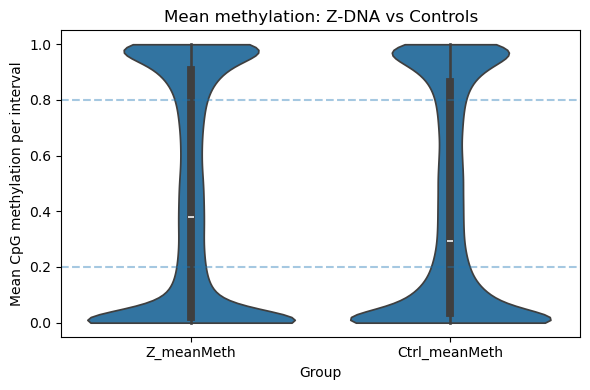

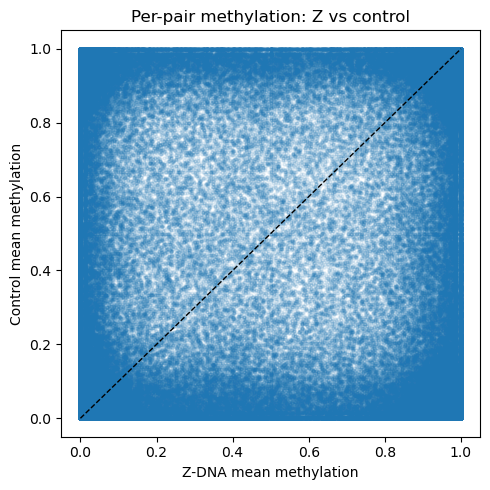

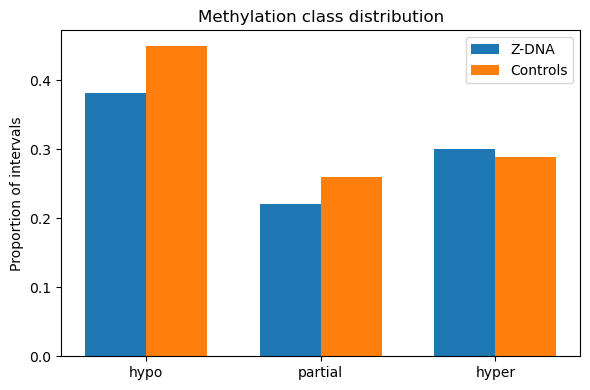

Wilcoxon signed-rank Z vs Ctrl: 8844347136.0 2.2304212315274737e-126
Chi-square on methylation classes: chi2= 952.6952373495537 p= 1.3330846932378743e-207


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/work/10906/geomeg/vista/pangenomes_zdna/zdna_z_vs_ctrl_methylation.tsv", sep="\t")

# Drop pairs with no CpGs on both sides
df_nonempty = df[(df["Z_nCpG"] > 0) | (df["Ctrl_nCpG"] > 0)].copy()
plt.figure(figsize=(6,4))
sns.violinplot(
    data=df_nonempty[["Z_meanMeth", "Ctrl_meanMeth"]].melt(
        var_name="Group", value_name="meanMeth"
    ),
    x="Group", y="meanMeth", cut=0
)
plt.axhline(0.2, linestyle="--", alpha=0.4)
plt.axhline(0.8, linestyle="--", alpha=0.4)
plt.ylabel("Mean CpG methylation per interval")
plt.title("Mean methylation: Z-DNA vs Controls")
plt.tight_layout()
plt.show()
plt.figure(figsize=(5,5))
plt.scatter(df_nonempty["Z_meanMeth"], df_nonempty["Ctrl_meanMeth"], alpha=0.1, s=5)
plt.plot([0,1],[0,1], "k--", linewidth=1)
plt.xlabel("Z-DNA mean methylation")
plt.ylabel("Control mean methylation")
plt.title("Per-pair methylation: Z vs control")
plt.tight_layout()
plt.show()

from collections import Counter

z_counts = Counter(df_nonempty["Z_methClass"])
c_counts = Counter(df_nonempty["Ctrl_methClass"])

cats = ["hypo", "partial", "hyper"]

z_props = [z_counts[c] / sum(z_counts.values()) for c in cats]
c_props = [c_counts[c] / sum(c_counts.values()) for c in cats]

x = np.arange(len(cats))
w = 0.35

plt.figure(figsize=(6,4))
plt.bar(x - w/2, z_props, width=w, label="Z-DNA")
plt.bar(x + w/2, c_props, width=w, label="Controls")
plt.xticks(x, cats)
plt.ylabel("Proportion of intervals")
plt.title("Methylation class distribution")
plt.legend()
plt.tight_layout()
plt.show()

from scipy.stats import wilcoxon

mask = (~df_nonempty["Z_meanMeth"].isna()) & (~df_nonempty["Ctrl_meanMeth"].isna())
stat, pval = wilcoxon(
    df_nonempty.loc[mask, "Z_meanMeth"],
    df_nonempty.loc[mask, "Ctrl_meanMeth"]
)
print("Wilcoxon signed-rank Z vs Ctrl:", stat, pval)

import numpy as np
from scipy.stats import chi2_contingency

table = np.array([
    [z_counts["hypo"],    z_counts["partial"],    z_counts["hyper"]],
    [c_counts["hypo"],    c_counts["partial"],    c_counts["hyper"]],
])
chi2, p, dof, expected = chi2_contingency(table)
print("Chi-square on methylation classes: chi2=", chi2, "p=", p)


In [13]:
#!/usr/bin/env python3
import os
import glob
import time

import numpy as np
import pandas as pd
import pyranges as pr
from tqdm import tqdm


# ------------------------------------------------------------
# Paths / setup
# ------------------------------------------------------------
BASE = "/work/10906/geomeg/vista/pangenomes_zdna"
CONTROLS_DIR = os.path.join(BASE, "controls")
CPG_BEDGRAPH = os.path.join(BASE, "ann_files", "CpG_all.bedgraph")
OUT_DIR = os.path.join(BASE, "methylation_analysis")
os.makedirs(OUT_DIR, exist_ok=True)

OUT_TABLE = os.path.join(OUT_DIR, "zdna_z_vs_ctrl_methylation.tsv")

print("Base directory:", BASE)
print("Controls directory:", CONTROLS_DIR)
print("CpG bedGraph:", CPG_BEDGRAPH)
print("Output table:", OUT_TABLE)

t0 = time.time()

# ------------------------------------------------------------
# 1. Load CpG bedgraph into PyRanges
# ------------------------------------------------------------
print("\n### Loading CpG_all.bedgraph into PyRanges ###")

# bedGraph: chrom, start, end, score
# pyranges will call the last column "Score" by default; we normalize to "score"
cpg_pr = pr.read_bed(CPG_BEDGRAPH, as_df=False)

# PyRanges stores df as cpg_pr.df
df = cpg_pr.df.copy()

# rename 4th column to "score" regardless of its original name
col4 = df.columns[3]
df = df.rename(columns={col4: "score"})

cpg_pr = pr.PyRanges(df)


print(f"Loaded CpG bedgraph: {len(cpg_df):,} rows")


# ------------------------------------------------------------
# 2. Helper: methylation class
# ------------------------------------------------------------
def meth_class(mean_meth: float) -> str:
    """
    Hypo / partial / hyper classification based on mean methylation.
      <0.2   → hypomethylated
      0.2–0.8 → partially methylated
      >=0.8  → hypermethylated
    """
    if mean_meth < 0.2:
        return "hypo"
    elif mean_meth < 0.8:
        return "partial"
    else:
        return "hyper"


# ------------------------------------------------------------
# 3. Loop over chromosomes (chr*_controls.tsv)
# ------------------------------------------------------------
tsv_files = sorted(glob.glob(os.path.join(CONTROLS_DIR, "chr*_controls.tsv")))
if not tsv_files:
    raise SystemExit(f"No chr*_controls.tsv files found in {CONTROLS_DIR}")

print("\nFound control files:")
for p in tsv_files:
    print("  ", os.path.basename(p))

all_results = []

print("\n### Processing chromosomes ###")

for tsv_path in tqdm(tsv_files, desc="Chromosomes"):

    chrom_name = os.path.basename(tsv_path).split("_")[0]  # e.g. "chr1"
    print(f"\n--- {chrom_name} ---")

    df = pd.read_csv(tsv_path, sep="\t")

    # Normalise column names a bit for convenience
    df = df.rename(columns={"Z-DNA Score": "Z_DNA_Score"})  # in case of space

    # Add unique row id per pair (Z + its control)
    df["pair_id"] = np.arange(len(df), dtype=int)

    # Extract CpG for this chromosome only, as PyRanges
    cpg_chr = cpg_pr[cpg_pr.Chromosome == chrom_name]
    if len(cpg_chr) == 0:
        print(f"No CpGs found in CpG file for {chrom_name}; setting all metrics to zero.")
        df["Z_nCpG"] = 0
        df["Z_meanMeth"] = 0.0
        df["Z_medianMeth"] = 0.0
        df["Z_maxMeth"] = 0.0

        df["Ctrl_nCpG"] = 0
        df["Ctrl_meanMeth"] = 0.0
        df["Ctrl_medianMeth"] = 0.0
        df["Ctrl_maxMeth"] = 0.0

        df["Z_methClass"] = "hypo"
        df["Ctrl_methClass"] = "hypo"

        all_results.append(df)
        continue

    # --------------------------------------------------------
    # 3a. Z-DNA intervals → PyRanges
    # --------------------------------------------------------
    z_df = df[["Chromosome", "Start", "End", "pair_id"]].copy()
    # ensure integer
    z_df["Start"] = z_df["Start"].astype(int)
    z_df["End"] = z_df["End"].astype(int)

    z_pr = pr.PyRanges(z_df)

    # join Z with CpGs on this chromosome
    z_hits = z_pr.join(cpg_chr, how="left")  # keeps intervals even if no hit
    z_hits_df = z_hits.df

    # choose score column name
    score_col = "score" if "score" in z_hits_df.columns else "Score"

    # group by pair_id to compute methylation stats
    z_grp = z_hits_df.groupby("pair_id", dropna=False)[score_col]

    # count of CpG rows (non-NaN)
    z_nCpG = z_grp.count()
    # mean, median, max – NaN if no CpGs, fill later
    z_mean = z_grp.mean()
    z_median = z_grp.median()
    z_max = z_grp.max()

    # --------------------------------------------------------
    # 3b. Control intervals → PyRanges
    # --------------------------------------------------------
    has_ctrl = df["Ctrl_Start"].notna()
    ctrl_df = df.loc[has_ctrl, ["Chromosome", "Ctrl_Start", "Ctrl_End", "pair_id"]].copy()
    ctrl_df = ctrl_df.rename(columns={"Ctrl_Start": "Start", "Ctrl_End": "End"})
    ctrl_df["Start"] = ctrl_df["Start"].astype(int)
    ctrl_df["End"] = ctrl_df["End"].astype(int)

    if len(ctrl_df) > 0:
        ctrl_pr = pr.PyRanges(ctrl_df)
        ctrl_hits = ctrl_pr.join(cpg_chr, how="left")
        ctrl_hits_df = ctrl_hits.df
        score_col_c = "score" if "score" in ctrl_hits_df.columns else "Score"
        ctrl_grp = ctrl_hits_df.groupby("pair_id", dropna=False)[score_col_c]

        ctrl_nCpG = ctrl_grp.count()
        ctrl_mean = ctrl_grp.mean()
        ctrl_median = ctrl_grp.median()
        ctrl_max = ctrl_grp.max()
    else:
        # no controls? should not happen, but handle it
        ctrl_nCpG = pd.Series(dtype=float)
        ctrl_mean = pd.Series(dtype=float)
        ctrl_median = pd.Series(dtype=float)
        ctrl_max = pd.Series(dtype=float)

    # --------------------------------------------------------
    # 3c. Attach stats back to df (reindex by pair_id)
    # --------------------------------------------------------
    # Initialise with zeros for CpG-free or control-free cases
    df["Z_nCpG"] = z_nCpG.reindex(df["pair_id"]).fillna(0).astype(int)
    df["Z_meanMeth"] = z_mean.reindex(df["pair_id"]).fillna(0.0).astype(float)
    df["Z_medianMeth"] = z_median.reindex(df["pair_id"]).fillna(0.0).astype(float)
    df["Z_maxMeth"] = z_max.reindex(df["pair_id"]).fillna(0.0).astype(float)

    df["Ctrl_nCpG"] = ctrl_nCpG.reindex(df["pair_id"]).fillna(0).astype(int)
    df["Ctrl_meanMeth"] = ctrl_mean.reindex(df["pair_id"]).fillna(0.0).astype(float)
    df["Ctrl_medianMeth"] = ctrl_median.reindex(df["pair_id"]).fillna(0.0).astype(float)
    df["Ctrl_maxMeth"] = ctrl_max.reindex(df["pair_id"]).fillna(0.0).astype(float)

    # --------------------------------------------------------
    # 3d. Methylation class labels
    # --------------------------------------------------------
    df["Z_methClass"] = df["Z_meanMeth"].apply(meth_class)
    df["Ctrl_methClass"] = df["Ctrl_meanMeth"].apply(meth_class)

    all_results.append(df)

# ------------------------------------------------------------
# 4. Concatenate all chromosomes and save
# ------------------------------------------------------------
print("\n### Concatenating all chromosomes ###")
all_df = pd.concat(all_results, ignore_index=True)

# Optional: clean up / reorder columns for the final table
cols_order = [
    "Chromosome",
    "Start", "End",
    "Z_DNA_Score" if "Z_DNA_Score" in all_df.columns else None,
    "Sequence",
    "Length", "GC_pct", "CpG_pct",
    "Ctrl_Start", "Ctrl_End", "Ctrl_Seq",
    "Z_nCpG", "Z_meanMeth", "Z_medianMeth", "Z_maxMeth",
    "Ctrl_nCpG", "Ctrl_meanMeth", "Ctrl_medianMeth", "Ctrl_maxMeth",
    "Z_methClass", "Ctrl_methClass",
]
cols_order = [c for c in cols_order if c in all_df.columns]

all_df[cols_order].to_csv(OUT_TABLE, sep="\t", index=False)

t1 = time.time()
print(f"Saved: {OUT_TABLE}")
print(f"Total runtime: {t1 - t0:.1f} seconds")
print("### DONE ###")


Base directory: /work/10906/geomeg/vista/pangenomes_zdna
Controls directory: /work/10906/geomeg/vista/pangenomes_zdna/controls
CpG bedGraph: /work/10906/geomeg/vista/pangenomes_zdna/ann_files/CpG_all.bedgraph
Output table: /work/10906/geomeg/vista/pangenomes_zdna/methylation_analysis/zdna_z_vs_ctrl_methylation.tsv

### Loading CpG_all.bedgraph into PyRanges ###
Loaded CpG bedgraph: 31,691,501 rows

Found control files:
   chr10_controls.tsv
   chr11_controls.tsv
   chr12_controls.tsv
   chr13_controls.tsv
   chr14_controls.tsv
   chr15_controls.tsv
   chr16_controls.tsv
   chr17_controls.tsv
   chr18_controls.tsv
   chr19_controls.tsv
   chr1_controls.tsv
   chr20_controls.tsv
   chr21_controls.tsv
   chr22_controls.tsv
   chr2_controls.tsv
   chr3_controls.tsv
   chr4_controls.tsv
   chr5_controls.tsv
   chr6_controls.tsv
   chr7_controls.tsv
   chr8_controls.tsv
   chr9_controls.tsv
   chrX_controls.tsv
   chrY_controls.tsv

### Processing chromosomes ###


Chromosomes:   0%|                                       | 0/24 [00:00<?, ?it/s]


--- chr10 ---


Chromosomes:   4%|█▎                             | 1/24 [00:00<00:07,  3.23it/s]


--- chr11 ---


Chromosomes:   8%|██▌                            | 2/24 [00:00<00:06,  3.37it/s]

... (33 outputs left out)

Chromosomes:  92%|███████████████████████████▌  | 22/24 [00:06<00:00,  2.81it/s]


--- chrX ---


Chromosomes: 100%|██████████████████████████████| 24/24 [00:07<00:00,  3.35it/s]



--- chrY ---
No CpGs found in CpG file for chrY; setting all metrics to zero.

### Concatenating all chromosomes ###
Saved: /work/10906/geomeg/vista/pangenomes_zdna/methylation_analysis/zdna_z_vs_ctrl_methylation.tsv
Total runtime: 19.7 seconds
### DONE ###


Scanning: 100%|█████████████████████████████████| 23/23 [07:58<00:00, 20.80s/it]


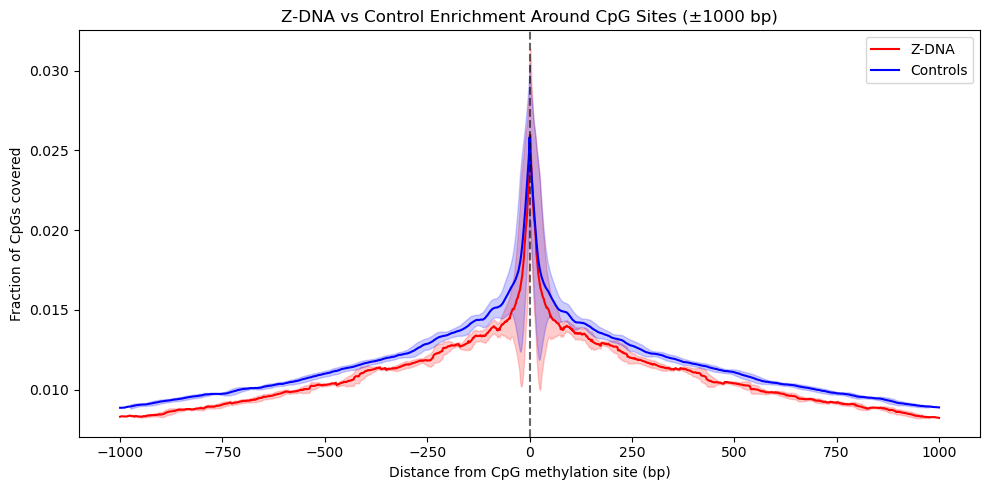

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# ---------------------------
# INPUTS
# ---------------------------
CPG = "/work/10906/geomeg/vista/pangenomes_zdna/ann_files/CpG_all.bedgraph"
PAIRED = "/work/10906/geomeg/vista/pangenomes_zdna/methylation_analysis/zdna_z_vs_ctrl_methylation.tsv"

WINDOW = 1000   # +/- 1000 bp

# ---------------------------
# Load CpG (chrom, start, end, score)
# ---------------------------
df_cpg = pd.read_csv(CPG, sep="\t", header=None,
                     names=["chrom","start","end","score"])

# Treat CpG coordinate as single base at "start"
df_cpg["pos"] = df_cpg["start"].astype(int)

# ---------------------------
# Load paired Z + control file
# ---------------------------
df = pd.read_csv(PAIRED, sep="\t")
df = df.dropna(subset=["Ctrl_Start", "Ctrl_End"]).copy()

# We need coordinates only
z_int = df[["Chromosome","Start","End"]].rename(
    columns={"Start":"z_s","End":"z_e"}
)
ctrl_int = df[["Chromosome","Ctrl_Start","Ctrl_End"]].rename(
    columns={"Ctrl_Start":"c_s","Ctrl_End":"c_e"}
)

# ---------------------------
# Build genome-wide Z / Ctrl coverage arrays
# ---------------------------

# Create dict: chrom → list of Z intervals, list of ctrl intervals
Z_by_chr = {}
C_by_chr = {}

for _, r in z_int.iterrows():
    chrom = r["Chromosome"]
    Z_by_chr.setdefault(chrom, []).append((int(r["z_s"]), int(r["z_e"])))

for _, r in ctrl_int.iterrows():
    chrom = r["Chromosome"]
    C_by_chr.setdefault(chrom, []).append((int(r["c_s"]), int(r["c_e"])))

# ---------------------------
# Function: count hits for distance bins
# ---------------------------
def collect_distances(df_cpg, intervals_by_chr, window):
    """
    For each CpG, look for any ZDNA interval within +/- window.
    For each offset delta in [-window, +window], count how many times
    an interval covers CpG+delta.
    Returns an array size window*2+1 with sums.
    """
    N = window*2 + 1
    counts = np.zeros(N, dtype=np.int64)

    # Preprocess intervals per chrom as arrays
    for chrom, group in tqdm(df_cpg.groupby("chrom"), desc="Scanning"):
        if chrom not in intervals_by_chr:
            continue

        ivals = intervals_by_chr[chrom]

        # convert list to numpy arrays for vectorization
        starts = np.array([s for s, e in ivals], dtype=np.int64)
        ends   = np.array([e for s, e in ivals], dtype=np.int64)

        for pos in group["pos"].values:
            # candidate genomic positions from pos-W to pos+W
            region_start = pos - window
            region_end   = pos + window

            # find intervals overlapping this window
            mask = ~((ends < region_start) | (starts > region_end))
            if not np.any(mask):
                continue

            # Overlapping intervals
            ov_s = starts[mask]
            ov_e = ends[mask]

            # For each delta in [-W, +W], check coverage
            # vectorized approach:
            deltas = np.arange(-window, window+1)
            positions = pos + deltas

            covered = np.any((positions[:,None] >= ov_s) &
                             (positions[:,None] <= ov_e), axis=1)

            counts += covered.astype(int)

    return counts

# ---------------------------
# Compute enrichment signals
# ---------------------------
z_signal = collect_distances(df_cpg, Z_by_chr, WINDOW)
c_signal = collect_distances(df_cpg, C_by_chr, WINDOW)

# Normalize to fraction of CpGs
n_cpg = len(df_cpg)
z_enrich = z_signal / n_cpg
c_enrich = c_signal / n_cpg

# X axis
x = np.arange(-WINDOW, WINDOW+1)

# ---------------------------
# Plot
# ---------------------------
plt.figure(figsize=(10,5))
sns.lineplot(x=x, y=z_enrich, label="Z-DNA", color="red")
sns.lineplot(x=x, y=c_enrich, label="Controls", color="blue")

# Smooth confidence bands using rolling window
win = 50
z_ci = pd.Series(z_enrich).rolling(win, center=True).std() * 1.96
c_ci = pd.Series(c_enrich).rolling(win, center=True).std() * 1.96

plt.fill_between(x, z_enrich - z_ci, z_enrich + z_ci,
                 color="red", alpha=0.2)
plt.fill_between(x, c_enrich - c_ci, c_enrich + c_ci,
                 color="blue", alpha=0.2)

plt.axvline(0, color="black", linestyle="--", alpha=0.6)
plt.xlabel("Distance from CpG methylation site (bp)")
plt.ylabel("Fraction of CpGs covered")
plt.title("Z-DNA vs Control Enrichment Around CpG Sites (±1000 bp)")
plt.legend()
plt.tight_layout()
plt.show()


## Mutational profiles

In [1]:
from pathlib import Path
import gzip
import pandas as pd

# Path to your VCF
vcf_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.vcf.gz")

def parse_VCF_first9(vcf_path: Path) -> pd.DataFrame:
    """
    Parse the VCF and return a DataFrame containing only the first 9 columns
    (#CHROM, POS, ID, REF, ALT, QUAL, FILTER, INFO, FORMAT).
    """
    with gzip.open(vcf_path, "rt") as f:
        # Skip meta lines, capture the VCF header line
        for line in f:
            if line.startswith("##"):
                continue
            header = line.strip().split("\t")[:9]
            break

        # Now f is positioned at the first data row
        df_vcf = pd.read_table(
            f,
            header=None,
            usecols=range(9),
            names=header
        )
    return df_vcf

df_vcf = parse_VCF_first9(vcf_path)
df_vcf.shape


(44559977, 9)

In [2]:
from collections import defaultdict

def classify_variant(allele: str, 
                     variant: str, 
                     smallins_thresh: int = 51, 
                     smalldel_thresh: int = 51) -> str:
    """
    Classify a REF/ALT pair according to your lab's rules:
    
    - len(ref) == len(alt) == 1       -> snp
    - len(ref) == len(alt) > 1        -> mnp
    - len(ref) < len(alt) and len(ref) == 1
          -> smallins if ins_len < 51
          -> ins otherwise
    - len(ref) > len(alt)
          -> smalldel if del_len < 51
          -> del otherwise
    - Otherwise -> complexins / complexdel
    """
    allele_N = len(allele)
    variant_N = len(variant)
    
    if allele_N == variant_N:
        return "snp" if allele_N == 1 else "mnp"
    
    if allele_N < variant_N:
        if allele_N == 1:
            return "smallins" if variant_N < smallins_thresh else "ins"
        else:
            return "complexins"
    
    if allele_N > variant_N:
        if variant_N == 1:
            return "smalldel" if allele_N < smalldel_thresh else "del"
        else:
            return "complexdel"
    
    raise ValueError(f"Unexpected allele/variant lengths: {allele}, {variant}")

def parse_attributes(attrs: str):
    """
    Parse the INFO field of a VCF row.
    Only keep: AC, AF, AN, LEN, TYPE, NS (same as lab script).
    Return a nested dict: attributes[key][i] = value_for_ALT_i
    and attributes['NS'][0], attributes['AN'][0] for constants.
    """
    attributes = defaultdict(dict)
    valid_attributes = {"AC", "AF", "AN", "LEN", "TYPE", "NS"}
    
    for aa in attrs.split(";"):
        if "=" not in aa:
            # Some flags may appear without '='
            continue
        key, val = aa.split("=", 1)
        if key not in valid_attributes:
            continue
        
        # NS, AN are single values
        if key in {"NS", "AN"}:
            try:
                val_cast = int(val)
            except ValueError:
                val_cast = val
            attributes[key][0] = val_cast
            continue
        
        # AC, AF, LEN, TYPE are per-ALT lists
        for i, v in enumerate(val.split(",")):
            if key in {"AC", "LEN"}:
                try:
                    v_cast = int(v)
                except ValueError:
                    v_cast = v
            elif key == "AF":
                try:
                    v_cast = float(v)
                except ValueError:
                    v_cast = v
            else:
                v_cast = v
            attributes[key][i] = v_cast

    return attributes


In [3]:
from tqdm import tqdm
import uuid

def explode_vcf(df_vcf: pd.DataFrame) -> pd.DataFrame:
    """
    For each VCF row, split multiple ALT alleles into separate rows.
    Compute:
        - seqID (chromosome)
        - start (0-based)
        - end (0-based half-open)
        - mutation (fine-grained type: snp, smallins, ins, etc.)
        - general_mut (ins / del / snp / mnp / complexins / complexdel)
        - reference, variant
        - INFO-derived attributes: AC, AF, AN, LEN, TYPE, NS
    """
    vcf_enriched = []
    
    for _, row in tqdm(df_vcf.iterrows(), total=df_vcf.shape[0]):
        seqID = row['#CHROM']
        reference = row['REF']
        var = row['ALT']
        info = row['INFO']
        pos = row['POS'] - 1  # convert to 0-based
        ref_len = len(reference)
        
        # Skip rows with missing ALT
        if isinstance(var, float):
            # e.g. NaN
            continue
        
        # ALT can be comma-separated
        alt_list = var.split(",")
        attributes = parse_attributes(info)
        subvariants = len(alt_list)
        unique_id = uuid.uuid4().hex[:8]
        
        # Coordinates in 0-based half-open (BED-like)
        start = int(pos)
        if ref_len == 1:
            end = start + 1
        else:
            end = start + ref_len
        
        constant_attrs = {"AN", "NS"}
        per_alt_attrs = {"AC", "AF", "LEN", "TYPE"}
        
        for i, alt in enumerate(alt_list):
            specific_mutation = classify_variant(reference, alt)
            # general category: ins / del / snp / mnp / complex*
            if specific_mutation.endswith("ins"):
                mutation_group = "ins"
            elif specific_mutation.endswith("del"):
                mutation_group = "del"
            else:
                mutation_group = specific_mutation  # snp, mnp, etc.
            
            attrs = {}
            for key in per_alt_attrs:
                if key in attributes and i in attributes[key]:
                    attrs[key] = attributes[key][i]
            for key in constant_attrs:
                if key in attributes and 0 in attributes[key]:
                    attrs[key] = attributes[key][0]
            
            vcf_enriched.append(
                {
                    "seqID": seqID,
                    "start": start,
                    "end": end,
                    "mutation": specific_mutation,
                    "general_mut": mutation_group,
                    "subvariants": subvariants,
                    "mut_id": unique_id,
                    "reference": reference,
                    "variant": alt,
                } | attrs
            )
    
    vcf_enriched = pd.DataFrame(vcf_enriched)
    return vcf_enriched

vcf_enriched = explode_vcf(df_vcf)
vcf_enriched.head()


100%|████████████████████████████████████████████████████████████████████| 44559977/44559977 [27:03<00:00, 27444.23it/s]


,seqID,start,end,mutation,general_mut,subvariants,mut_id,reference,variant,AF,AC,LEN,TYPE,AN,NS
0,chr10,0,1,smallins,ins,5,efecbaf5,C,CTAACCCTAAACCCCTAACCCTAACCTAACCC,0.021277,1,31,ins,47,232
1,chr10,0,1,smallins,ins,5,efecbaf5,C,CTAACCCTAACCAACCCTAACCACCCTAACCCTAACCC,0.021277,1,37,ins,47,232
2,chr10,0,1,smallins,ins,5,efecbaf5,C,CTAACCCTAACCCT,0.021277,1,13,ins,47,232
3,chr10,0,1,ins,ins,5,efecbaf5,C,CTAACCCTAACCTAACCCTAACCCTAACCCTAACCCTAACCCTAAC...,0.021277,1,64,ins,47,232
4,chr10,0,1,smallins,ins,5,efecbaf5,C,CTAACCCTAACCTAACCCTAACCCTAACCTAACCC,0.021277,1,34,ins,47,232


In [4]:
output_exploded_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.exploded.tsv.gz")

vcf_enriched.to_csv(
    output_exploded_path,
    sep="\t",
    index=False,
    compression="gzip"
)

output_exploded_path

PosixPath('/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.exploded.tsv.gz')

In [5]:
# If you've just created vcf_enriched in memory, you can reuse it.
# Otherwise, reload it from disk:
# vcf_enriched = pd.read_table(output_exploded_path, compression="gzip")

# Create a BED-like DataFrame
# Standard BED: chrom, start, end, name, score, strand
# We'll fill: chrom, start, end, name=mutation, score='.', strand='.'

bed_df = pd.DataFrame({
    "chrom": vcf_enriched["seqID"],
    "start": vcf_enriched["start"].astype(int),
    "end": vcf_enriched["end"].astype(int),
    "name": vcf_enriched["mutation"],
    "score": ".",
    "strand": ".",
    # Extra useful columns:
    "general_mut": vcf_enriched["general_mut"],
    "reference": vcf_enriched["reference"],
    "variant": vcf_enriched["variant"],
})

bed_output_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.bed.gz")

bed_df.to_csv(
    bed_output_path,
    sep="\t",
    header=False,  # pure BED style
    index=False,
    compression="gzip"
)

bed_output_path

PosixPath('/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.bed.gz')

In [6]:
threecol_df = pd.DataFrame({
    "chrom": vcf_enriched["seqID"],
    "pos": vcf_enriched["start"],  # 0-based coordinate
    "mutation": vcf_enriched["mutation"],
})

threecol_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.3col.tsv.gz")
threecol_df.to_csv(threecol_path, sep="\t", index=False, compression="gzip")
threecol_path

PosixPath('/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.3col.tsv.gz')

Loading mutations...
Loading Z-DNA + controls...
Loading chromosome lengths...
Building interval dictionaries...
Computing SNP mutation-density profiles...
Using substitution types: ['G>A', 'C>T', 'A>G', 'T>C', 'G>T', 'C>A', 'C>G', 'G>C', 'T>G', 'A>C', 'T>A', 'A>T']


Processing SNPs by chromosome: 100%|████████████████████████████████████████████████████| 25/25 [21:45<00:00, 52.21s/it]


Aggregating all SNPs profile...
Plotting...


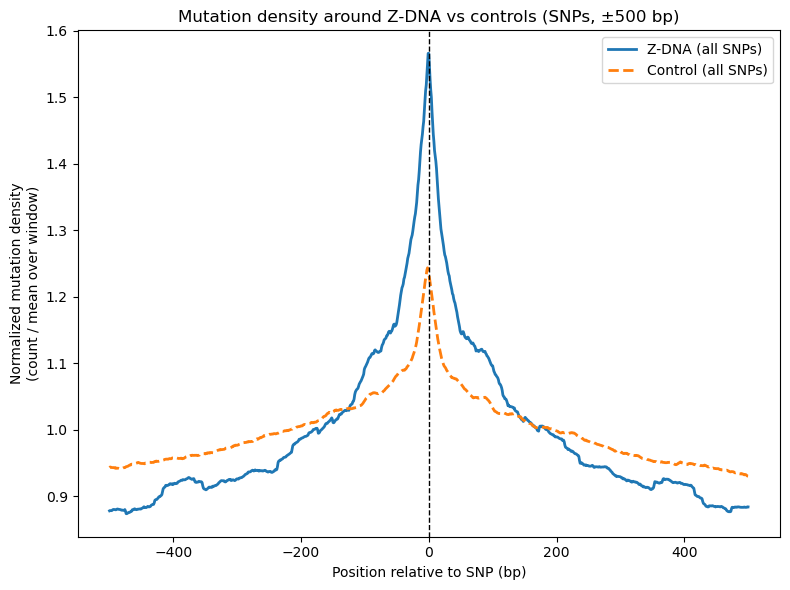

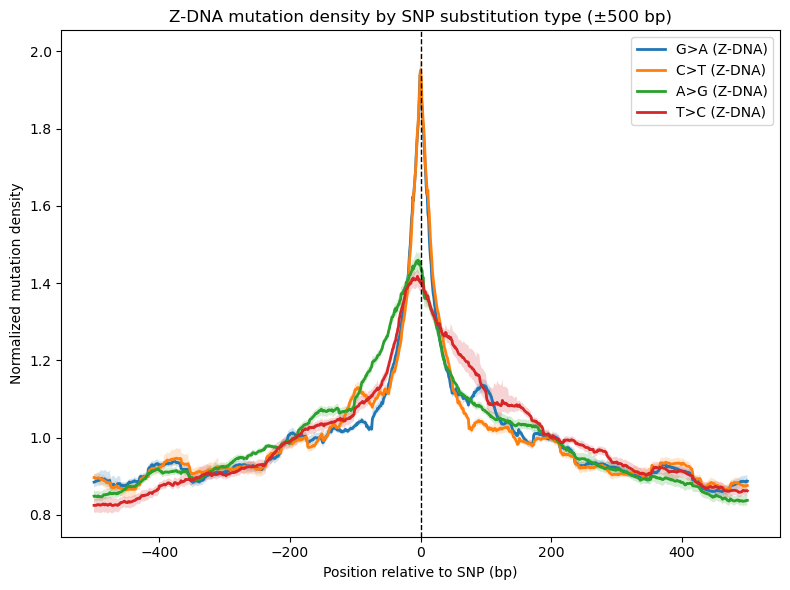

In [1]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt

# ================================================================
# CONFIG
# ================================================================
# Paths (adjust if needed)
mut_bed_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.bed.gz")
zdna_tsv_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_z_vs_ctrl_methylation.tsv")
chrom_len_tsv_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv")

# window radius (-R .. +R)
WINDOW_RADIUS = 500  # 1 kb window
# bootstrap parameters
N_BOOTS = 500
CI_LOW, CI_HIGH = 2.5, 97.5

# minimum SNP count per substitution type to include in plotting
MIN_SNPS_PER_TYPE = 1000

# ================================================================
# HELPERS
# ================================================================
def position_in_intervals_array(positions, starts, ends):
    """
    Given sorted intervals [start, end) (arrays starts, ends) and an array of positions,
    return a boolean array: True if position is inside any interval.
    """
    n = positions.size
    if n == 0 or starts.size == 0:
        return np.zeros(n, dtype=bool)

    idx = np.searchsorted(starts, positions, side="right") - 1
    # positions before the first interval
    mask_valid = idx >= 0
    in_itvl = np.zeros(n, dtype=bool)
    if not mask_valid.any():
        return in_itvl

    valid_idx = idx[mask_valid]
    valid_pos = positions[mask_valid]
    in_itvl[mask_valid] = valid_pos < ends[valid_idx]
    return in_itvl


def build_interval_dict(zdna_df):
    """
    Build dictionaries:
        zdna_intervals[chrom] -> (starts_Z, ends_Z)
        ctrl_intervals[chrom] -> (starts_C, ends_C)
    intervals are sorted by start.
    """
    zdna_intervals = {}
    ctrl_intervals = {}

    for chrom, group in zdna_df.groupby("Chromosome"):
        # Z-DNA intervals
        starts_z = group["Start"].astype(int).to_numpy()
        ends_z   = group["End"].astype(int).to_numpy()
        order_z  = np.argsort(starts_z)
        starts_z = starts_z[order_z]
        ends_z   = ends_z[order_z]
        zdna_intervals[chrom] = (starts_z, ends_z)

        # Control intervals
        starts_c = group["Ctrl_Start"].astype(int).to_numpy()
        ends_c   = group["Ctrl_End"].astype(int).to_numpy()
        order_c  = np.argsort(starts_c)
        starts_c = starts_c[order_c]
        ends_c   = ends_c[order_c]
        ctrl_intervals[chrom] = (starts_c, ends_c)

    return zdna_intervals, ctrl_intervals


def bootstrap_chrom_weighted_profiles(chrom_profiles, chrom_lengths, n_boot=500,
                                      ci_low=2.5, ci_high=97.5):
    """
    chrom_profiles: dict[chrom] -> 1D np.array (profile over offsets)
    chrom_lengths:  dict[chrom] -> length (weight)
    Returns: (lower_CI, upper_CI) arrays of same length as profile.
    Performs block bootstrap at the chromosome level.
    """
    chroms = list(chrom_profiles.keys())
    if len(chroms) == 0:
        return None, None

    profiles = [chrom_profiles[c] for c in chroms]
    weights = np.array([chrom_lengths[c] for c in chroms], dtype=float)

    profiles = np.stack(profiles, axis=0)  # shape: (n_chrom, n_offsets)
    n_chrom, n_offsets = profiles.shape

    boot_mat = np.zeros((n_boot, n_offsets), dtype=float)

    for b in range(n_boot):
        # sample chromosomes with replacement
        idx = np.random.randint(0, n_chrom, size=n_chrom)
        sampled_profiles = profiles[idx]      # (n_chrom, n_offsets)
        sampled_weights  = weights[idx]       # (n_chrom,)

        total_w = sampled_weights.sum()
        if total_w == 0:
            continue
        # length-weighted mean
        boot_mat[b] = (sampled_profiles.T @ sampled_weights) / total_w

    lower = np.percentile(boot_mat, ci_low, axis=0)
    upper = np.percentile(boot_mat, ci_high, axis=0)
    return lower, upper

# ================================================================
# CORE: compute profiles by SNP subtype
# ================================================================
def compute_snp_profiles(
    mut_df,
    zdna_intervals,
    ctrl_intervals,
    chrom_lengths,
    window_radius=500,
    min_snps_per_type=1000
):
    """
    For SNPs only:
      - build substitution type (ref>alt),
      - compute mutation-density profiles around Z-DNA and control,
      - per-chromosome, per-substitution type,
      - normalize per chromosome (counts / mean(counts)),
      - length-weighted global aggregation.

    Returns:
      offsets,
      profiles_by_type: dict[subtype] = {
          "global_Z": 1D array,
          "global_C": 1D array,
          "global_Z_ci_low": 1D array,
          "global_Z_ci_high": 1D array,
          "global_C_ci_low": 1D array,
          "global_C_ci_high": 1D array  
      }
    """
    offsets = np.arange(-window_radius, window_radius + 1, dtype=int)
    n_offsets = offsets.size

    # keep only SNPs
    snp_df = mut_df[mut_df["mutation_name"] == "snp"].copy()
    # define substitution type ref>alt
    snp_df["sub_type"] = snp_df["reference"].astype(str) + ">" + snp_df["variant"].astype(str)

    # filter to canonical bases if you want (optional)
    valid_bases = set(["A", "C", "G", "T"])
    mask_valid = snp_df["reference"].isin(valid_bases) & snp_df["variant"].isin(valid_bases)
    snp_df = snp_df[mask_valid]

    # count per subtype
    subtype_counts = snp_df["sub_type"].value_counts()

    # only keep subtypes with enough SNPs
    keep_subtypes = [st for st, cnt in subtype_counts.items() if cnt >= min_snps_per_type]
    if len(keep_subtypes) == 0:
        print("⚠️ No SNP substitution type passes MIN_SNPS_PER_TYPE. Lower the threshold?")
        return offsets, {}

    print("Using substitution types:", keep_subtypes)

    # nested structure:
    #   per_type_chrom_counts_Z[subtype][chrom] = counts array (length n_offsets)
    #   same for ctrl
    per_type_chrom_counts_Z = {st: defaultdict(lambda: np.zeros(n_offsets, dtype=int)) for st in keep_subtypes}
    per_type_chrom_counts_C = {st: defaultdict(lambda: np.zeros(n_offsets, dtype=int)) for st in keep_subtypes}

    # --- MAIN LOOP: per chromosome ---
    for chrom, group_chrom in tqdm(snp_df.groupby("chrom"), desc="Processing SNPs by chromosome"):
        if chrom not in zdna_intervals or chrom not in ctrl_intervals:
            continue

        starts_Z, ends_Z = zdna_intervals[chrom]
        starts_C, ends_C = ctrl_intervals[chrom]

        # for per-subtype splitting
        for sub_type, group_sub in group_chrom.groupby("sub_type"):
            if sub_type not in keep_subtypes:
                continue

            centers = group_sub["center"].astype(int).to_numpy()
            if centers.size == 0:
                continue

            counts_Z = per_type_chrom_counts_Z[sub_type][chrom]
            counts_C = per_type_chrom_counts_C[sub_type][chrom]

            # loop over SNP centers in this (chrom, subtype)
            for c in centers:
                positions = c + offsets

                # Z-DNA occupancy
                in_Z = position_in_intervals_array(positions, starts_Z, ends_Z)
                # control occupancy
                in_C = position_in_intervals_array(positions, starts_C, ends_C)

                counts_Z += in_Z.astype(int)
                counts_C += in_C.astype(int)

    # --- Convert counts to normalized per-chrom enrichment and aggregate ---
    profiles_by_type = {}

    for sub_type in keep_subtypes:
        chrom_counts_Z = per_type_chrom_counts_Z[sub_type]
        chrom_counts_C = per_type_chrom_counts_C[sub_type]

        if len(chrom_counts_Z) == 0:
            continue

        # per-chrom enrichment arrays
        chrom_enr_Z = {}
        chrom_enr_C = {}
        chrom_w = {}

        for chrom, counts_Z in chrom_counts_Z.items():
            counts_C = chrom_counts_C.get(chrom, None)
            if counts_C is None:
                continue

            # per-chrom mean mutation rate across window
            # if all zero, skip
            if counts_Z.sum() == 0 and counts_C.sum() == 0:
                continue

            # avoid zero mean; if mean=0, skip chrom
            mean_Z = counts_Z.mean()
            mean_C = counts_C.mean()
            if mean_Z == 0 or mean_C == 0:
                continue

            enr_Z = counts_Z / mean_Z
            enr_C = counts_C / mean_C

            chrom_enr_Z[chrom] = enr_Z.astype(float)
            chrom_enr_C[chrom] = enr_C.astype(float)
            if chrom in chrom_lengths:
                chrom_w[chrom] = float(chrom_lengths[chrom])
            else:
                # if missing length, just weight equally as 1
                chrom_w[chrom] = 1.0

        if len(chrom_enr_Z) == 0:
            continue

        # length-weighted global mean profile
        chroms = list(chrom_enr_Z.keys())
        w = np.array([chrom_w[c] for c in chroms], dtype=float)
        Z_mat = np.stack([chrom_enr_Z[c] for c in chroms], axis=0)
        C_mat = np.stack([chrom_enr_C[c] for c in chroms], axis=0)

        total_w = w.sum()
        global_Z = (Z_mat.T @ w) / total_w
        global_C = (C_mat.T @ w) / total_w

        # bootstrap CIs (chrom-block bootstrap)
        Z_ci_low, Z_ci_high = bootstrap_chrom_weighted_profiles(chrom_enr_Z, chrom_w,
                                                                n_boot=N_BOOTS,
                                                                ci_low=CI_LOW,
                                                                ci_high=CI_HIGH)
        C_ci_low, C_ci_high = bootstrap_chrom_weighted_profiles(chrom_enr_C, chrom_w,
                                                                n_boot=N_BOOTS,
                                                                ci_low=CI_LOW,
                                                                ci_high=CI_HIGH)

        profiles_by_type[sub_type] = {
            "global_Z": global_Z,
            "global_C": global_C,
            "global_Z_ci_low": Z_ci_low,
            "global_Z_ci_high": Z_ci_high,
            "global_C_ci_low": C_ci_low,
            "global_C_ci_high": C_ci_high
        }

    return offsets, profiles_by_type


# ================================================================
# MAIN
# ================================================================
def main():
    # ------------------------------------------------------------
    # 1) Load mutations BED
    # ------------------------------------------------------------
    mut_cols = [
        "chrom", "start", "end", "mutation_name", "score",
        "strand", "general_mut", "reference", "variant"
    ]

    print("Loading mutations...")
    mut_df = pd.read_csv(
        mut_bed_path,
        sep="\t",
        header=None,
        names=mut_cols,
        compression="gzip"
    )

    # midpoint: integer center of [start, end)
    mut_df["center"] = (mut_df["start"] + mut_df["end"]) // 2

    # ------------------------------------------------------------
    # 2) Load Z-DNA + control table
    # ------------------------------------------------------------
    print("Loading Z-DNA + controls...")
    zdna_df = pd.read_csv(zdna_tsv_path, sep="\t")

    # ------------------------------------------------------------
    # 3) Load chromosome lengths
    # ------------------------------------------------------------
    print("Loading chromosome lengths...")
    chrom_len_df = pd.read_csv(chrom_len_tsv_path, sep="\t")
    chrom_name_col = "ucsc_pansn_name"
    chrom_len_col = "gcf_seq_length"
    chrom_lengths = dict(zip(chrom_len_df[chrom_name_col], chrom_len_df[chrom_len_col]))

    # ------------------------------------------------------------
    # 4) Build interval dictionaries
    # ------------------------------------------------------------
    print("Building interval dictionaries...")
    zdna_intervals, ctrl_intervals = build_interval_dict(zdna_df)

    # ------------------------------------------------------------
    # 5) Compute SNP profiles by substitution type
    # ------------------------------------------------------------
    print("Computing SNP mutation-density profiles...")
    offsets, profiles_by_type = compute_snp_profiles(
        mut_df=mut_df,
        zdna_intervals=zdna_intervals,
        ctrl_intervals=ctrl_intervals,
        chrom_lengths=chrom_lengths,
        window_radius=WINDOW_RADIUS,
        min_snps_per_type=MIN_SNPS_PER_TYPE,
    )

    if not profiles_by_type:
        print("No profiles were computed. Check thresholds / inputs.")
        return

    # ------------------------------------------------------------
    # 6) Aggregate "all SNPs" (across types) for a main global curve
    #     (length-weighted over subtypes by their SNP counts)
    # ------------------------------------------------------------
    print("Aggregating all SNPs profile...")
    subtypes = list(profiles_by_type.keys())
    # approximate weights = number of SNPs per subtype (recompute quickly)
    snp_df = mut_df[mut_df["mutation_name"] == "snp"].copy()
    snp_df["sub_type"] = snp_df["reference"].astype(str) + ">" + snp_df["variant"].astype(str)
    subtype_counts = snp_df["sub_type"].value_counts()

    w_sub = np.array([subtype_counts.get(st, 0) for st in subtypes], dtype=float)
    total_w_sub = w_sub.sum()
    # stack profiles
    Z_stack = np.stack([profiles_by_type[st]["global_Z"] for st in subtypes], axis=0)
    C_stack = np.stack([profiles_by_type[st]["global_C"] for st in subtypes], axis=0)

    global_Z_all = (Z_stack.T @ w_sub) / total_w_sub
    global_C_all = (C_stack.T @ w_sub) / total_w_sub


    # ------------------------------------------------------------
    # 7) Plot: main figure for all SNPs + subtypes
    # ------------------------------------------------------------
    print("Plotting...")

    # --- Panel 1: all SNPs Z vs control with polynomial + residual inset style ---
    plt.figure(figsize=(8,6))
    
    plt.plot(offsets, global_Z_all, label="Z-DNA (all SNPs)", linewidth=2)
    plt.plot(offsets, global_C_all, label="Control (all SNPs)", linewidth=2, linestyle="--")
    
    plt.axvline(0, linestyle="--", color="black", linewidth=1)
    plt.ylabel("Normalized mutation density\n(count / mean over window)")
    plt.title("Mutation density around Z-DNA vs controls (SNPs, ±500 bp)")
    plt.legend(loc="best")
    
    plt.xlabel("Position relative to SNP (bp)")
    plt.tight_layout()
    plt.show()

    # --- Panel 2: overlay a few substitution types (Z only) with CIs ---
    # pick up to 4 most frequent substitution types
    top_subtypes = [
        st for st in subtype_counts.index
        if st in profiles_by_type
    ][:4]

    if top_subtypes:
        plt.figure(figsize=(8, 6))
        for st in top_subtypes:
            prof = profiles_by_type[st]
            Z = prof["global_Z"]
            Z_lo = prof["global_Z_ci_low"]
            Z_hi = prof["global_Z_ci_high"]

            plt.plot(offsets, Z, label=f"{st} (Z-DNA)", linewidth=2)
            if Z_lo is not None and Z_hi is not None:
                plt.fill_between(offsets, Z_lo, Z_hi, alpha=0.2)

        plt.axvline(0, linestyle="--", color="black", linewidth=1)
        plt.xlabel("Position relative to SNP (bp)")
        plt.ylabel("Normalized mutation density")
        plt.title("Z-DNA mutation density by SNP substitution type (±500 bp)")
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("No substitution types available for subtype-specific plot.")


if __name__ == "__main__":
    main()
    

Loading mutations...
Loading Z-DNA + controls...
Loading chromosome lengths...
Computing SNP mutation-density profiles...
Using substitution types: ['G>A', 'C>T', 'A>G', 'T>C', 'G>T', 'C>A', 'C>G', 'G>C', 'T>G', 'A>C', 'T>A', 'A>T']


Processing SNP subtypes (PyRanges):   0%|                                                        | 0/12 [00:00<?, ?it/s]/tmp/ipykernel_962703/316669759.py:152: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chrom, dfZ_ch in df_Z.groupby("Chromosome"):
/tmp/ipykernel_962703/316669759.py:188: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chrom, dfC_ch in df_C.groupby("Chromosome"):
Processing SNP subtypes (PyRanges):   8%|████                                            | 1/12 [00:05<00:56,  5.11s/it]/tmp/ipykernel_962703/316669759.py:152: FutureWarning: The default of observed=False is deprecated and wil

Aggregating all SNPs profile...
Plotting...


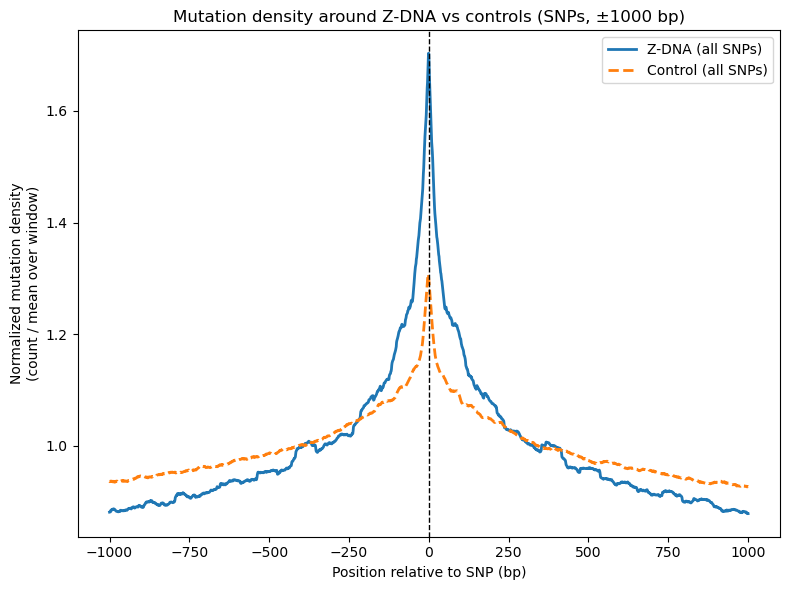

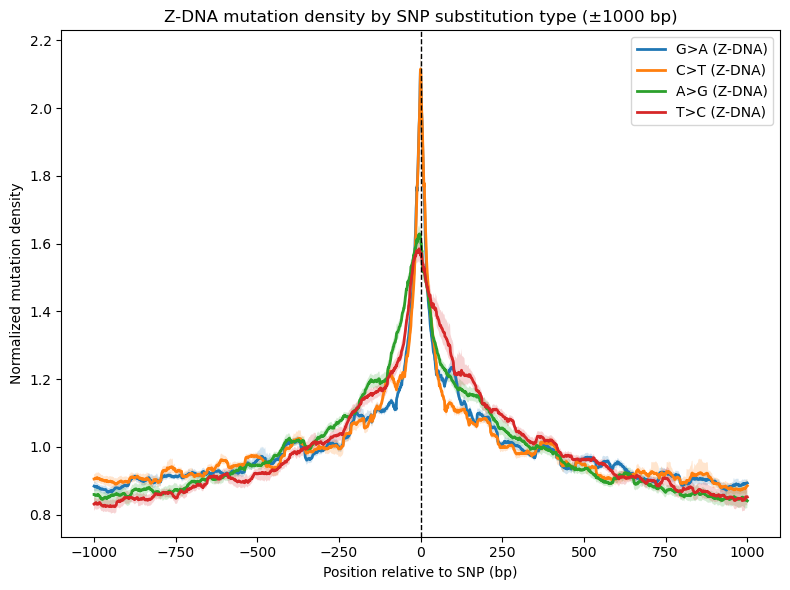

In [2]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt
import pyranges as pr

# ================================================================
# CONFIG
# ================================================================
# Paths (adjust if needed)
mut_bed_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.bed.gz")
zdna_tsv_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_z_vs_ctrl_methylation.tsv")
chrom_len_tsv_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv")

# window radius (-R .. +R)
WINDOW_RADIUS = 1000  # 2 kb window total (2001 offsets)
# bootstrap parameters
N_BOOTS = 500
CI_LOW, CI_HIGH = 2.5, 97.5

# minimum SNP count per substitution type to include in plotting
MIN_SNPS_PER_TYPE = 1000

# ================================================================
# HELPERS
# ================================================================
def bootstrap_chrom_weighted_profiles(chrom_profiles, chrom_lengths, n_boot=500,
                                      ci_low=2.5, ci_high=97.5):
    """
    chrom_profiles: dict[chrom] -> 1D np.array (profile over offsets)
    chrom_lengths:  dict[chrom] -> length (weight)
    Returns: (lower_CI, upper_CI) arrays of same length as profile.
    Performs block bootstrap at the chromosome level.
    """
    chroms = list(chrom_profiles.keys())
    if len(chroms) == 0:
        return None, None

    profiles = [chrom_profiles[c] for c in chroms]
    weights = np.array([chrom_lengths[c] for c in chroms], dtype=float)

    profiles = np.stack(profiles, axis=0)  # shape: (n_chrom, n_offsets)
    n_chrom, n_offsets = profiles.shape

    boot_mat = np.zeros((n_boot, n_offsets), dtype=float)

    for b in range(n_boot):
        # sample chromosomes with replacement
        idx = np.random.randint(0, n_chrom, size=n_chrom)
        sampled_profiles = profiles[idx]      # (n_chrom, n_offsets)
        sampled_weights  = weights[idx]       # (n_chrom,)

        total_w = sampled_weights.sum()
        if total_w == 0:
            continue
        # length-weighted mean
        boot_mat[b] = (sampled_profiles.T @ sampled_weights) / total_w

    lower = np.percentile(boot_mat, ci_low, axis=0)
    upper = np.percentile(boot_mat, ci_high, axis=0)
    return lower, upper


# ================================================================
# CORE: compute profiles by SNP subtype (PyRanges-based)
# ================================================================
def compute_snp_profiles(
    mut_df,
    zdna_pr,
    ctrl_pr,
    chrom_lengths,
    window_radius=1000,
    min_snps_per_type=1000
):
    """
    For SNPs only:
      - build substitution type (ref>alt),
      - compute mutation-density profiles around Z-DNA and control,
      - per-chromosome, per-substitution type,
      - normalize per chromosome (counts / mean(counts)),
      - length-weighted global aggregation.

    Uses PyRanges joins between SNP-centered windows and Z/control intervals.

    Returns:
      offsets,
      profiles_by_type: dict[subtype] = {
          "global_Z": 1D array,
          "global_C": 1D array,
          "global_Z_ci_low": 1D array,
          "global_Z_ci_high": 1D array,
          "global_C_ci_low": 1D array,
          "global_C_ci_high": 1D array
      }
    """
    offsets = np.arange(-window_radius, window_radius + 1, dtype=int)
    n_offsets = offsets.size

    # keep only SNPs
    snp_df = mut_df[mut_df["mutation_name"] == "snp"].copy()
    # define substitution type ref>alt
    snp_df["sub_type"] = snp_df["reference"].astype(str) + ">" + snp_df["variant"].astype(str)

    # filter to canonical bases if you want (optional)
    valid_bases = set(["A", "C", "G", "T"])
    mask_valid = snp_df["reference"].isin(valid_bases) & snp_df["variant"].isin(valid_bases)
    snp_df = snp_df[mask_valid]

    # count per subtype
    subtype_counts = snp_df["sub_type"].value_counts()

    # only keep subtypes with enough SNPs
    keep_subtypes = [st for st, cnt in subtype_counts.items() if cnt >= min_snps_per_type]
    if len(keep_subtypes) == 0:
        print("⚠️ No SNP substitution type passes MIN_SNPS_PER_TYPE. Lower the threshold?")
        return offsets, {}

    print("Using substitution types:", keep_subtypes)

    profiles_by_type = {}

    # --- MAIN LOOP: per substitution type ---
    for sub_type in tqdm(keep_subtypes, desc="Processing SNP subtypes (PyRanges)"):
        snp_sub = snp_df[snp_df["sub_type"] == sub_type].copy()
        if snp_sub.empty:
            continue

        # build SNP-centered windows [center - R, center + R + 1)
        snp_sub["Chromosome"] = snp_sub["chrom"].astype(str)
        snp_sub["Start"] = (snp_sub["center"].astype(int) - window_radius)
        snp_sub["End"]   = (snp_sub["center"].astype(int) + window_radius + 1)

        # PyRanges for this subtype (SNP windows)
        snp_pr = pr.PyRanges(snp_sub[["Chromosome", "Start", "End", "center"]])

        # Join with Z-DNA and control intervals
        overlaps_Z = snp_pr.join(zdna_pr)
        overlaps_C = snp_pr.join(ctrl_pr)

        df_Z = overlaps_Z.df if len(overlaps_Z) > 0 else pd.DataFrame()
        df_C = overlaps_C.df if len(overlaps_C) > 0 else pd.DataFrame()

        # per-chromosome counts arrays
        chrom_counts_Z = defaultdict(lambda: np.zeros(n_offsets, dtype=int))
        chrom_counts_C = defaultdict(lambda: np.zeros(n_offsets, dtype=int))

        # --- Accumulate counts for Z-DNA overlaps ---
        if not df_Z.empty:
            for chrom, dfZ_ch in df_Z.groupby("Chromosome"):
                # difference array trick for fast range increments
                diffZ = np.zeros(n_offsets + 1, dtype=int)

                center = dfZ_ch["center"].to_numpy(dtype=int)
                win_start = dfZ_ch["Start"].to_numpy(dtype=int)   # = center - R
                win_end   = dfZ_ch["End"].to_numpy(dtype=int)     # = center + R + 1
                z_start   = dfZ_ch["Start_b"].to_numpy(dtype=int)
                z_end     = dfZ_ch["End_b"].to_numpy(dtype=int)

                # intersection of SNP window with Z interval
                ov_start = np.maximum(win_start, z_start)
                ov_end   = np.minimum(win_end,   z_end)

                # offsets relative to SNP center (k_start inclusive, k_end exclusive)
                k_start = ov_start - center
                k_end   = ov_end   - center

                # clip to [-R, R+1]
                k_start = np.maximum(k_start, -window_radius)
                k_end   = np.minimum(k_end,   window_radius + 1)

                # keep only non-empty ranges
                mask = k_start < k_end
                if mask.any():
                    i_start = k_start[mask] + window_radius   # map offset -> index
                    i_end   = k_end[mask]   + window_radius   # exclusive

                    # apply increments
                    np.add.at(diffZ, i_start, 1)
                    np.add.at(diffZ, i_end,   -1)

                chrom_counts_Z[chrom] = np.cumsum(diffZ)[:n_offsets]

        # --- Accumulate counts for control overlaps ---
        if not df_C.empty:
            for chrom, dfC_ch in df_C.groupby("Chromosome"):
                diffC = np.zeros(n_offsets + 1, dtype=int)

                center = dfC_ch["center"].to_numpy(dtype=int)
                win_start = dfC_ch["Start"].to_numpy(dtype=int)
                win_end   = dfC_ch["End"].to_numpy(dtype=int)
                c_start   = dfC_ch["Start_b"].to_numpy(dtype=int)
                c_end     = dfC_ch["End_b"].to_numpy(dtype=int)

                ov_start = np.maximum(win_start, c_start)
                ov_end   = np.minimum(win_end,   c_end)

                k_start = ov_start - center
                k_end   = ov_end   - center

                k_start = np.maximum(k_start, -window_radius)
                k_end   = np.minimum(k_end,   window_radius + 1)

                mask = k_start < k_end
                if mask.any():
                    i_start = k_start[mask] + window_radius
                    i_end   = k_end[mask]   + window_radius
                    np.add.at(diffC, i_start, 1)
                    np.add.at(diffC, i_end,   -1)

                chrom_counts_C[chrom] = np.cumsum(diffC)[:n_offsets]

        # --- Convert counts to normalized per-chrom enrichment and aggregate ---
        if not chrom_counts_Z:
            continue

        chrom_enr_Z = {}
        chrom_enr_C = {}
        chrom_w = {}

        for chrom, counts_Z in chrom_counts_Z.items():
            counts_C = chrom_counts_C.get(chrom, None)
            if counts_C is None:
                continue

            # per-chrom mean mutation rate across window
            if counts_Z.sum() == 0 and counts_C.sum() == 0:
                continue

            mean_Z = counts_Z.mean()
            mean_C = counts_C.mean()
            if mean_Z == 0 or mean_C == 0:
                continue

            enr_Z = counts_Z / mean_Z
            enr_C = counts_C / mean_C

            chrom_enr_Z[chrom] = enr_Z.astype(float)
            chrom_enr_C[chrom] = enr_C.astype(float)

            if chrom in chrom_lengths:
                chrom_w[chrom] = float(chrom_lengths[chrom])
            else:
                chrom_w[chrom] = 1.0

        if len(chrom_enr_Z) == 0:
            continue

        # length-weighted global mean profile
        chroms = list(chrom_enr_Z.keys())
        w = np.array([chrom_w[c] for c in chroms], dtype=float)
        Z_mat = np.stack([chrom_enr_Z[c] for c in chroms], axis=0)
        C_mat = np.stack([chrom_enr_C[c] for c in chroms], axis=0)

        total_w = w.sum()
        global_Z = (Z_mat.T @ w) / total_w
        global_C = (C_mat.T @ w) / total_w

        # bootstrap CIs (chrom-block bootstrap)
        Z_ci_low, Z_ci_high = bootstrap_chrom_weighted_profiles(
            chrom_enr_Z, chrom_w,
            n_boot=N_BOOTS,
            ci_low=CI_LOW,
            ci_high=CI_HIGH,
        )
        C_ci_low, C_ci_high = bootstrap_chrom_weighted_profiles(
            chrom_enr_C, chrom_w,
            n_boot=N_BOOTS,
            ci_low=CI_LOW,
            ci_high=CI_HIGH,
        )

        profiles_by_type[sub_type] = {
            "global_Z": global_Z,
            "global_C": global_C,
            "global_Z_ci_low": Z_ci_low,
            "global_Z_ci_high": Z_ci_high,
            "global_C_ci_low": C_ci_low,
            "global_C_ci_high": C_ci_high,
        }

    return offsets, profiles_by_type


# ================================================================
# MAIN
# ================================================================
def main():
    # ------------------------------------------------------------
    # 1) Load mutations BED
    # ------------------------------------------------------------
    mut_cols = [
        "chrom", "start", "end", "mutation_name", "score",
        "strand", "general_mut", "reference", "variant"
    ]

    print("Loading mutations...")
    mut_df = pd.read_csv(
        mut_bed_path,
        sep="\t",
        header=None,
        names=mut_cols,
        compression="gzip"
    )

    # midpoint: integer center of [start, end)
    mut_df["center"] = (mut_df["start"] + mut_df["end"]) // 2

    # ------------------------------------------------------------
    # 2) Load Z-DNA + control table
    # ------------------------------------------------------------
    print("Loading Z-DNA + controls...")
    zdna_df = pd.read_csv(zdna_tsv_path, sep="\t")

    # Build PyRanges for Z-DNA and control intervals
    zdna_ranges_df = zdna_df[["Chromosome", "Start", "End"]].copy()
    zdna_ranges_df["Start"] = zdna_ranges_df["Start"].astype(int)
    zdna_ranges_df["End"]   = zdna_ranges_df["End"].astype(int)
    zdna_pr = pr.PyRanges(zdna_ranges_df)

    ctrl_ranges_df = zdna_df[["Chromosome", "Ctrl_Start", "Ctrl_End"]].copy()
    ctrl_ranges_df = ctrl_ranges_df.rename(columns={"Ctrl_Start": "Start", "Ctrl_End": "End"})
    ctrl_ranges_df["Start"] = ctrl_ranges_df["Start"].astype(int)
    ctrl_ranges_df["End"]   = ctrl_ranges_df["End"].astype(int)
    ctrl_pr = pr.PyRanges(ctrl_ranges_df)

    # ------------------------------------------------------------
    # 3) Load chromosome lengths
    # ------------------------------------------------------------
    print("Loading chromosome lengths...")
    chrom_len_df = pd.read_csv(chrom_len_tsv_path, sep="\t")
    chrom_name_col = "ucsc_pansn_name"
    chrom_len_col = "gcf_seq_length"
    chrom_lengths = dict(zip(chrom_len_df[chrom_name_col], chrom_len_df[chrom_len_col]))

    # ------------------------------------------------------------
    # 4) Compute SNP profiles by substitution type (PyRanges)
    # ------------------------------------------------------------
    print("Computing SNP mutation-density profiles...")
    offsets, profiles_by_type = compute_snp_profiles(
        mut_df=mut_df,
        zdna_pr=zdna_pr,
        ctrl_pr=ctrl_pr,
        chrom_lengths=chrom_lengths,
        window_radius=WINDOW_RADIUS,
        min_snps_per_type=MIN_SNPS_PER_TYPE,
    )

    if not profiles_by_type:
        print("No profiles were computed. Check thresholds / inputs.")
        return

    # ------------------------------------------------------------
    # 5) Aggregate "all SNPs" (across types) for a main global curve
    #     (length-weighted over subtypes by their SNP counts)
    # ------------------------------------------------------------
    print("Aggregating all SNPs profile...")
    subtypes = list(profiles_by_type.keys())
    # approximate weights = number of SNPs per subtype (recompute quickly)
    snp_df = mut_df[mut_df["mutation_name"] == "snp"].copy()
    snp_df["sub_type"] = snp_df["reference"].astype(str) + ">" + snp_df["variant"].astype(str)
    subtype_counts = snp_df["sub_type"].value_counts()

    w_sub = np.array([subtype_counts.get(st, 0) for st in subtypes], dtype=float)
    total_w_sub = w_sub.sum()

    # stack profiles
    Z_stack = np.stack([profiles_by_type[st]["global_Z"] for st in subtypes], axis=0)
    C_stack = np.stack([profiles_by_type[st]["global_C"] for st in subtypes], axis=0)

    global_Z_all = (Z_stack.T @ w_sub) / total_w_sub
    global_C_all = (C_stack.T @ w_sub) / total_w_sub

    # ------------------------------------------------------------
    # 6) Plot: main figure for all SNPs + subtypes
    # ------------------------------------------------------------
    print("Plotting...")

    # --- Panel 1: all SNPs Z vs control ---
    plt.figure(figsize=(8, 6))

    plt.plot(offsets, global_Z_all, label="Z-DNA (all SNPs)", linewidth=2)
    plt.plot(offsets, global_C_all, label="Control (all SNPs)", linewidth=2, linestyle="--")

    plt.axvline(0, linestyle="--", color="black", linewidth=1)
    plt.ylabel("Normalized mutation density\n(count / mean over window)")
    plt.title("Mutation density around Z-DNA vs controls (SNPs, ±1000 bp)")
    plt.legend(loc="best")

    plt.xlabel("Position relative to SNP (bp)")
    plt.tight_layout()
    plt.show()

    # --- Panel 2: overlay a few substitution types (Z only) with CIs ---
    # pick up to 4 most frequent substitution types
    top_subtypes = [
        st for st in subtype_counts.index
        if st in profiles_by_type
    ][:4]

    if top_subtypes:
        plt.figure(figsize=(8, 6))
        for st in top_subtypes:
            prof = profiles_by_type[st]
            Z = prof["global_Z"]
            Z_lo = prof["global_Z_ci_low"]
            Z_hi = prof["global_Z_ci_high"]

            plt.plot(offsets, Z, label=f"{st} (Z-DNA)", linewidth=2)
            if Z_lo is not None and Z_hi is not None:
                plt.fill_between(offsets, Z_lo, Z_hi, alpha=0.2)

        plt.axvline(0, linestyle="--", color="black", linewidth=1)
        plt.xlabel("Position relative to SNP (bp)")
        plt.ylabel("Normalized mutation density")
        plt.title("Z-DNA mutation density by SNP substitution type (±1000 bp)")
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("No substitution types available for subtype-specific plot.")


if __name__ == "__main__":
    main()


Loading mutations...
Loading Z-DNA + controls...
Loading chromosome lengths...
Computing mutation-density profiles by category...
Using mutation categories: ['snp', 'smalldel', 'complexins', 'smallins', 'complexdel', 'mnp', 'ins', 'del']


Processing mutation categories (PyRanges):   0%|                                                  | 0/8 [00:00<?, ?it/s]/tmp/ipykernel_962703/2008240784.py:144: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chrom, dfZ_ch in df_Z.groupby("Chromosome"):
/tmp/ipykernel_962703/2008240784.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for chrom, dfC_ch in df_C.groupby("Chromosome"):
Processing mutation categories (PyRanges):  12%|█████▎                                    | 1/8 [00:13<01:35, 13.58s/it]/tmp/ipykernel_962703/2008240784.py:144: FutureWarning: The default of observed=False is deprecated and 

Plotting per mutation category...


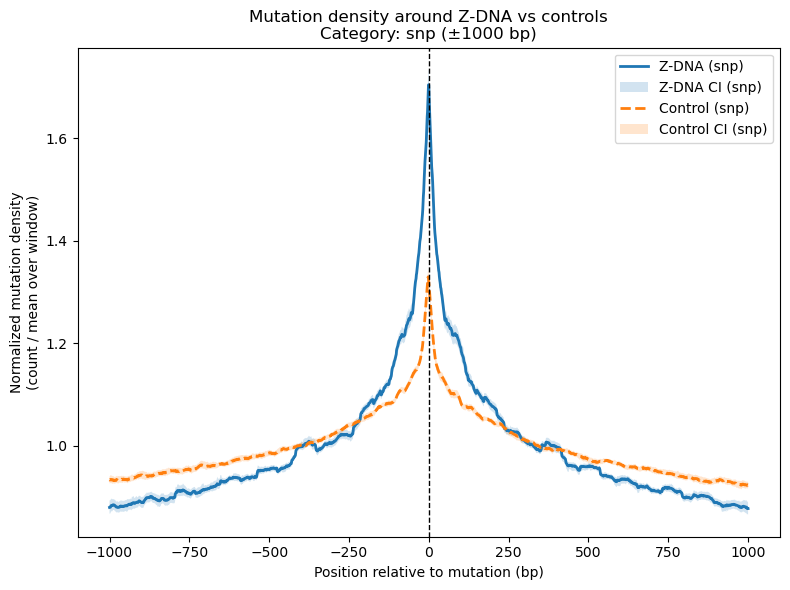

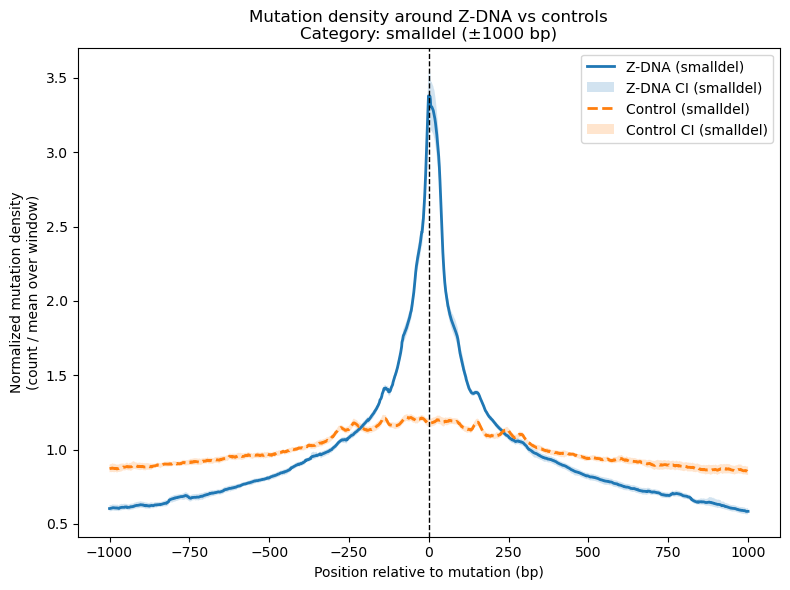

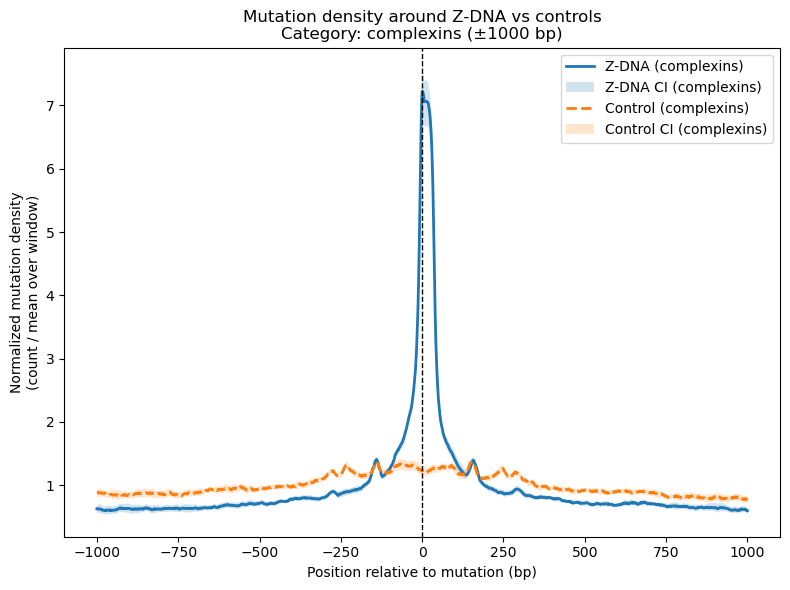

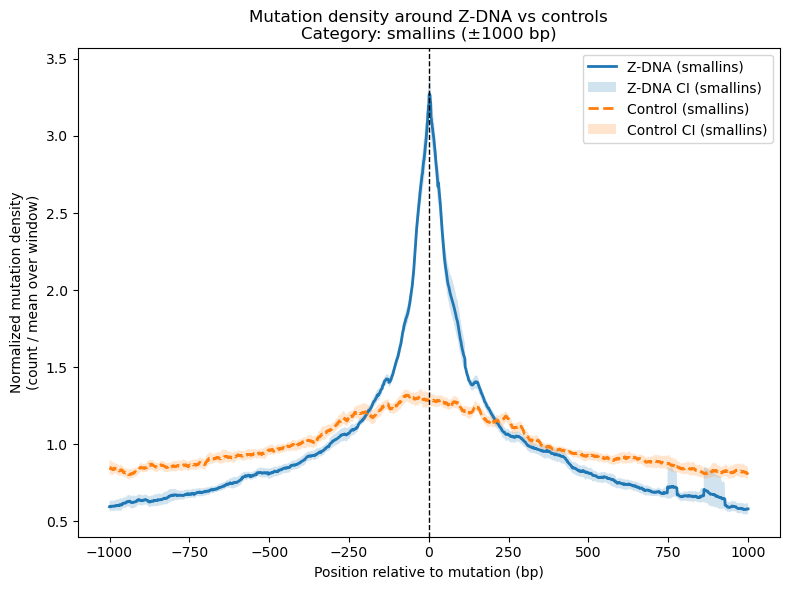

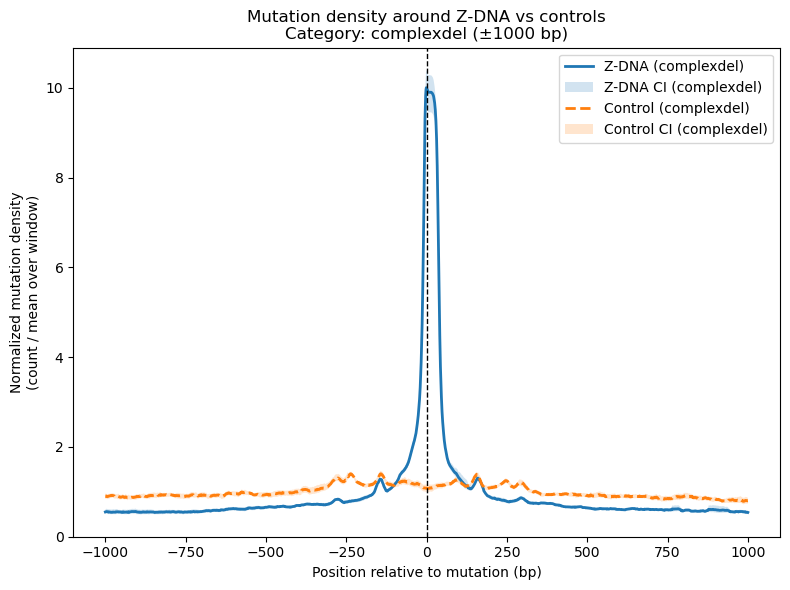

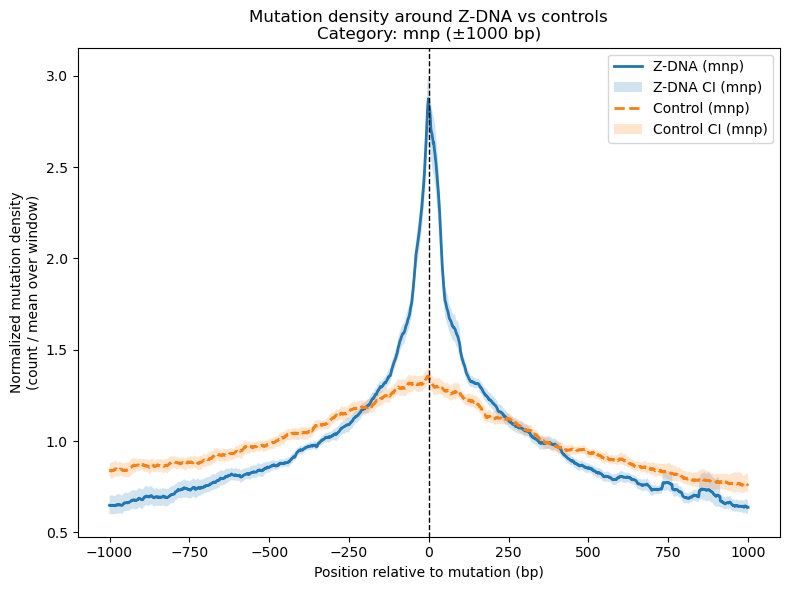

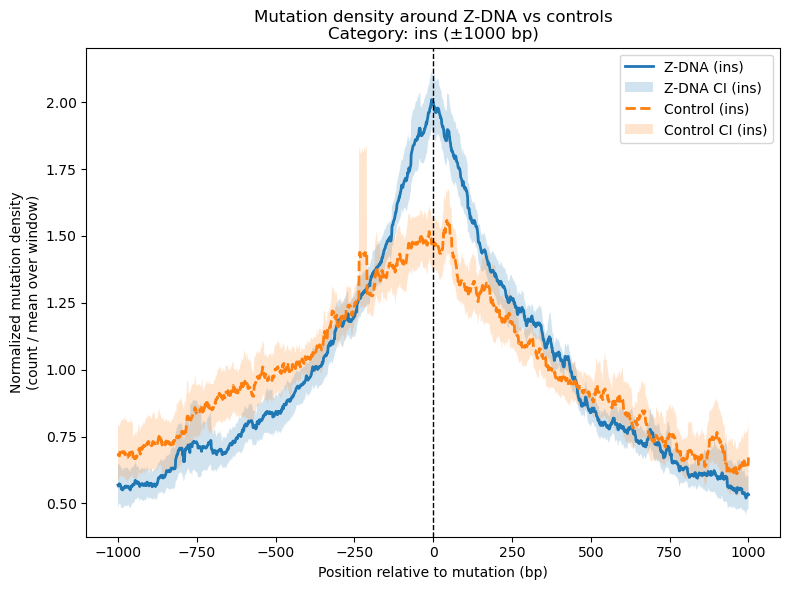

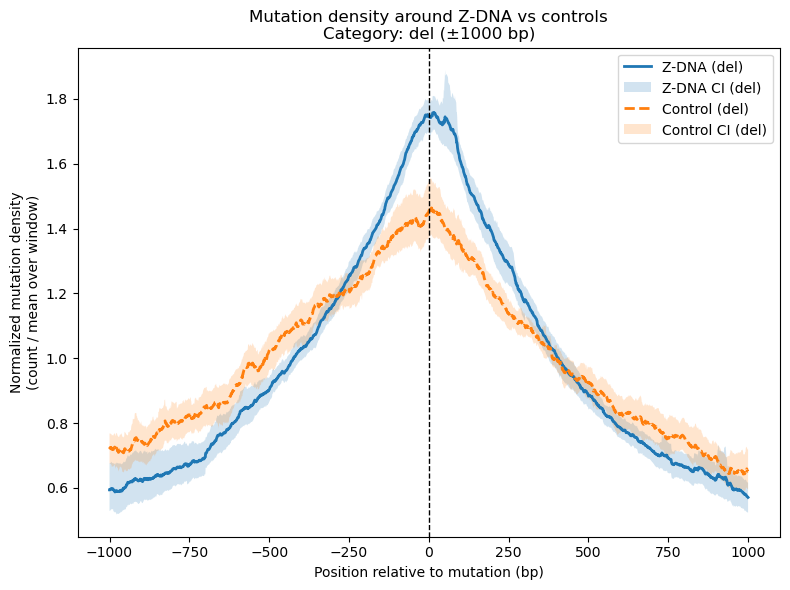

In [3]:
#!/usr/bin/env python3
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt
import pyranges as pr

# ================================================================
# CONFIG
# ================================================================
# Paths (adjust if needed)
mut_bed_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/ann_files/hprc-v2.0-mc-chm13.wave.mutations.bed.gz")
zdna_tsv_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/zdna_z_vs_ctrl_methylation.tsv")
chrom_len_tsv_path = Path("/work/10906/geomeg/vista/pangenomes_zdna/tmp/GCF_PanSN_sequence_report_with_zdna.tsv")

# window radius (-R .. +R)
WINDOW_RADIUS = 1000  # 2 kb window total (2001 offsets)

# bootstrap parameters
N_BOOTS = 500
CI_LOW, CI_HIGH = 2.5, 97.5

# minimum mutation count per category to include in plotting
MIN_MUTS_PER_CATEGORY = 1000

# ================================================================
# HELPERS
# ================================================================
def bootstrap_chrom_weighted_profiles(chrom_profiles, chrom_lengths, n_boot=500,
                                      ci_low=2.5, ci_high=97.5):
    """
    chrom_profiles: dict[chrom] -> 1D np.array (profile over offsets)
    chrom_lengths:  dict[chrom] -> length (weight)
    Returns: (lower_CI, upper_CI) arrays of same length as profile.
    Performs block bootstrap at the chromosome level.
    """
    chroms = list(chrom_profiles.keys())
    if len(chroms) == 0:
        return None, None

    profiles = [chrom_profiles[c] for c in chroms]
    weights = np.array([chrom_lengths[c] for c in chroms], dtype=float)

    profiles = np.stack(profiles, axis=0)  # shape: (n_chrom, n_offsets)
    n_chrom, n_offsets = profiles.shape

    boot_mat = np.zeros((n_boot, n_offsets), dtype=float)

    for b in range(n_boot):
        # sample chromosomes with replacement
        idx = np.random.randint(0, n_chrom, size=n_chrom)
        sampled_profiles = profiles[idx]      # (n_chrom, n_offsets)
        sampled_weights  = weights[idx]       # (n_chrom,)

        total_w = sampled_weights.sum()
        if total_w == 0:
            continue
        # length-weighted mean
        boot_mat[b] = (sampled_profiles.T @ sampled_weights) / total_w

    lower = np.percentile(boot_mat, ci_low, axis=0)
    upper = np.percentile(boot_mat, ci_high, axis=0)
    return lower, upper


# ================================================================
# CORE: compute profiles by mutation category (PyRanges-based)
# ================================================================
def compute_mutation_profiles(
    mut_df,
    zdna_pr,
    ctrl_pr,
    chrom_lengths,
    window_radius=1000,
    min_muts_per_category=1000,
):
    """
    For each mutation category (mut_df['mutation_name']):
      - build windows around mutation centers (center - R, center + R),
      - compute mutation-density profiles around Z-DNA and control via PyRanges joins,
      - per-chromosome, per-category,
      - normalize per chromosome (counts / mean(counts)),
      - length-weighted global aggregation.

    Returns:
      offsets,
      profiles_by_category: dict[mutation_name] = {
          "global_Z": 1D array,
          "global_C": 1D array,
          "global_Z_ci_low": 1D array,
          "global_Z_ci_high": 1D array,
          "global_C_ci_low": 1D array,
          "global_C_ci_high": 1D array
      }
    """
    offsets = np.arange(-window_radius, window_radius + 1, dtype=int)
    n_offsets = offsets.size

    # Count per mutation category
    category_counts = mut_df["mutation_name"].value_counts()

    # Only keep categories with enough mutations
    keep_categories = [
        cat for cat, cnt in category_counts.items()
        if cnt >= min_muts_per_category
    ]
    if len(keep_categories) == 0:
        print("⚠️ No mutation category passes MIN_MUTS_PER_CATEGORY. Lower the threshold?")
        return offsets, {}

    print("Using mutation categories:", keep_categories)

    profiles_by_category = {}

    # --- MAIN LOOP: per mutation category ---
    for category in tqdm(keep_categories, desc="Processing mutation categories (PyRanges)"):
        mut_cat = mut_df[mut_df["mutation_name"] == category].copy()
        if mut_cat.empty:
            continue

        # Build mutation-centered windows [center - R, center + R + 1)
        mut_cat["Chromosome"] = mut_cat["chrom"].astype(str)
        mut_cat["Start"] = (mut_cat["center"].astype(int) - window_radius)
        mut_cat["End"]   = (mut_cat["center"].astype(int) + window_radius + 1)

        # PyRanges object for this category
        mut_pr = pr.PyRanges(mut_cat[["Chromosome", "Start", "End", "center"]])

        # Join with Z-DNA and control intervals
        overlaps_Z = mut_pr.join(zdna_pr)
        overlaps_C = mut_pr.join(ctrl_pr)

        df_Z = overlaps_Z.df if len(overlaps_Z) > 0 else pd.DataFrame()
        df_C = overlaps_C.df if len(overlaps_C) > 0 else pd.DataFrame()

        # Per-chromosome counts arrays
        chrom_counts_Z = defaultdict(lambda: np.zeros(n_offsets, dtype=int))
        chrom_counts_C = defaultdict(lambda: np.zeros(n_offsets, dtype=int))

        # --- Accumulate counts for Z-DNA overlaps ---
        if not df_Z.empty:
            for chrom, dfZ_ch in df_Z.groupby("Chromosome"):
                diffZ = np.zeros(n_offsets + 1, dtype=int)

                center = dfZ_ch["center"].to_numpy(dtype=int)
                win_start = dfZ_ch["Start"].to_numpy(dtype=int)   # = center - R
                win_end   = dfZ_ch["End"].to_numpy(dtype=int)     # = center + R + 1
                z_start   = dfZ_ch["Start_b"].to_numpy(dtype=int)
                z_end     = dfZ_ch["End_b"].to_numpy(dtype=int)

                # Intersection of mutation window with Z interval
                ov_start = np.maximum(win_start, z_start)
                ov_end   = np.minimum(win_end,   z_end)

                # offsets relative to mutation center (k_start inclusive, k_end exclusive)
                k_start = ov_start - center
                k_end   = ov_end   - center

                # clip to [-R, R+1]
                k_start = np.maximum(k_start, -window_radius)
                k_end   = np.minimum(k_end,   window_radius + 1)

                # keep only non-empty ranges
                mask = k_start < k_end
                if mask.any():
                    i_start = k_start[mask] + window_radius   # map offset -> index
                    i_end   = k_end[mask]   + window_radius   # exclusive

                    np.add.at(diffZ, i_start, 1)
                    np.add.at(diffZ, i_end,   -1)

                chrom_counts_Z[chrom] = np.cumsum(diffZ)[:n_offsets]

        # --- Accumulate counts for control overlaps ---
        if not df_C.empty:
            for chrom, dfC_ch in df_C.groupby("Chromosome"):
                diffC = np.zeros(n_offsets + 1, dtype=int)

                center = dfC_ch["center"].to_numpy(dtype=int)
                win_start = dfC_ch["Start"].to_numpy(dtype=int)
                win_end   = dfC_ch["End"].to_numpy(dtype=int)
                c_start   = dfC_ch["Start_b"].to_numpy(dtype=int)
                c_end     = dfC_ch["End_b"].to_numpy(dtype=int)

                ov_start = np.maximum(win_start, c_start)
                ov_end   = np.minimum(win_end,   c_end)

                k_start = ov_start - center
                k_end   = ov_end   - center

                k_start = np.maximum(k_start, -window_radius)
                k_end   = np.minimum(k_end,   window_radius + 1)

                mask = k_start < k_end
                if mask.any():
                    i_start = k_start[mask] + window_radius
                    i_end   = k_end[mask]   + window_radius
                    np.add.at(diffC, i_start, 1)
                    np.add.at(diffC, i_end,   -1)

                chrom_counts_C[chrom] = np.cumsum(diffC)[:n_offsets]

        # --- Convert counts to normalized per-chrom enrichment and aggregate ---
        if not chrom_counts_Z:
            continue

        chrom_enr_Z = {}
        chrom_enr_C = {}
        chrom_w = {}

        for chrom, counts_Z in chrom_counts_Z.items():
            counts_C = chrom_counts_C.get(chrom, None)
            if counts_C is None:
                continue

            # per-chrom mean mutation rate across window
            if counts_Z.sum() == 0 and counts_C.sum() == 0:
                continue

            mean_Z = counts_Z.mean()
            mean_C = counts_C.mean()
            if mean_Z == 0 or mean_C == 0:
                continue

            enr_Z = counts_Z / mean_Z
            enr_C = counts_C / mean_C

            chrom_enr_Z[chrom] = enr_Z.astype(float)
            chrom_enr_C[chrom] = enr_C.astype(float)

            if chrom in chrom_lengths:
                chrom_w[chrom] = float(chrom_lengths[chrom])
            else:
                chrom_w[chrom] = 1.0

        if len(chrom_enr_Z) == 0:
            continue

        # length-weighted global mean profile
        chroms = list(chrom_enr_Z.keys())
        w = np.array([chrom_w[c] for c in chroms], dtype=float)
        Z_mat = np.stack([chrom_enr_Z[c] for c in chroms], axis=0)
        C_mat = np.stack([chrom_enr_C[c] for c in chroms], axis=0)

        total_w = w.sum()
        global_Z = (Z_mat.T @ w) / total_w
        global_C = (C_mat.T @ w) / total_w

        # bootstrap CIs (chrom-block bootstrap)
        Z_ci_low, Z_ci_high = bootstrap_chrom_weighted_profiles(
            chrom_enr_Z, chrom_w,
            n_boot=N_BOOTS,
            ci_low=CI_LOW,
            ci_high=CI_HIGH,
        )
        C_ci_low, C_ci_high = bootstrap_chrom_weighted_profiles(
            chrom_enr_C, chrom_w,
            n_boot=N_BOOTS,
            ci_low=CI_LOW,
            ci_high=CI_HIGH,
        )

        profiles_by_category[category] = {
            "global_Z": global_Z,
            "global_C": global_C,
            "global_Z_ci_low": Z_ci_low,
            "global_Z_ci_high": Z_ci_high,
            "global_C_ci_low": C_ci_low,
            "global_C_ci_high": C_ci_high,
        }

    return offsets, profiles_by_category


# ================================================================
# MAIN
# ================================================================
def main():
    # ------------------------------------------------------------
    # 1) Load mutations BED
    # ------------------------------------------------------------
    mut_cols = [
        "chrom", "start", "end", "mutation_name", "score",
        "strand", "general_mut", "reference", "variant"
    ]

    print("Loading mutations...")
    mut_df = pd.read_csv(
        mut_bed_path,
        sep="\t",
        header=None,
        names=mut_cols,
        compression="gzip"
    )

    # midpoint: integer center of [start, end)
    mut_df["center"] = (mut_df["start"] + mut_df["end"]) // 2

    # ------------------------------------------------------------
    # 2) Load Z-DNA + control table
    # ------------------------------------------------------------
    print("Loading Z-DNA + controls...")
    zdna_df = pd.read_csv(zdna_tsv_path, sep="\t")

    # Build PyRanges for Z-DNA and control intervals
    zdna_ranges_df = zdna_df[["Chromosome", "Start", "End"]].copy()
    zdna_ranges_df["Start"] = zdna_ranges_df["Start"].astype(int)
    zdna_ranges_df["End"]   = zdna_ranges_df["End"].astype(int)
    zdna_pr = pr.PyRanges(zdna_ranges_df)

    ctrl_ranges_df = zdna_df[["Chromosome", "Ctrl_Start", "Ctrl_End"]].copy()
    ctrl_ranges_df = ctrl_ranges_df.rename(columns={"Ctrl_Start": "Start", "Ctrl_End": "End"})
    ctrl_ranges_df["Start"] = ctrl_ranges_df["Start"].astype(int)
    ctrl_ranges_df["End"]   = ctrl_ranges_df["End"].astype(int)
    ctrl_pr = pr.PyRanges(ctrl_ranges_df)

    # ------------------------------------------------------------
    # 3) Load chromosome lengths
    # ------------------------------------------------------------
    print("Loading chromosome lengths...")
    chrom_len_df = pd.read_csv(chrom_len_tsv_path, sep="\t")
    chrom_name_col = "ucsc_pansn_name"
    chrom_len_col = "gcf_seq_length"
    chrom_lengths = dict(zip(chrom_len_df[chrom_name_col], chrom_len_df[chrom_len_col]))

    # ------------------------------------------------------------
    # 4) Compute mutation profiles by category (PyRanges)
    # ------------------------------------------------------------
    print("Computing mutation-density profiles by category...")
    offsets, profiles_by_category = compute_mutation_profiles(
        mut_df=mut_df,
        zdna_pr=zdna_pr,
        ctrl_pr=ctrl_pr,
        chrom_lengths=chrom_lengths,
        window_radius=WINDOW_RADIUS,
        min_muts_per_category=MIN_MUTS_PER_CATEGORY,
    )

    if not profiles_by_category:
        print("No profiles were computed. Check thresholds / inputs.")
        return

    # ------------------------------------------------------------
    # 5) Plot: one figure per mutation category
    # ------------------------------------------------------------
    print("Plotting per mutation category...")

    for category, prof in profiles_by_category.items():
        Z = prof["global_Z"]
        C = prof["global_C"]
        Z_lo = prof["global_Z_ci_low"]
        Z_hi = prof["global_Z_ci_high"]
        C_lo = prof["global_C_ci_low"]
        C_hi = prof["global_C_ci_high"]

        plt.figure(figsize=(8, 6))

        # Z-DNA curve + CI
        plt.plot(offsets, Z, label=f"Z-DNA ({category})", linewidth=2)
        if Z_lo is not None and Z_hi is not None:
            plt.fill_between(offsets, Z_lo, Z_hi, alpha=0.2, label=f"Z-DNA CI ({category})")

        # Control curve + CI
        plt.plot(offsets, C, label=f"Control ({category})", linewidth=2, linestyle="--")
        if C_lo is not None and C_hi is not None:
            plt.fill_between(offsets, C_lo, C_hi, alpha=0.2, linestyle="--", label=f"Control CI ({category})")

        plt.axvline(0, linestyle="--", color="black", linewidth=1)
        plt.xlabel("Position relative to mutation (bp)")
        plt.ylabel("Normalized mutation density\n(count / mean over window)")
        plt.title(f"Mutation density around Z-DNA vs controls\nCategory: {category} (±{WINDOW_RADIUS} bp)")
        plt.legend(loc="best")
        plt.tight_layout()
        plt.show()


if __name__ == "__main__":
    main()


## Draft